# Analyse Bayernwerk 2025

In [3]:
import psycopg
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime

## Wind Bayernwerk

In [2]:
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

query = """
    SELECT 
        timestamp,
        SUM(verlust) AS verlust_kwh
    FROM dwd.wind_bayernwerk_2025_interpolated
    GROUP BY timestamp
    ORDER BY timestamp
"""
df_wind = pd.read_sql(query, conn)
conn.close()

C:\Users\user\AppData\Local\Temp\ipykernel_20520\1262667546.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_wind = pd.read_sql(query, conn)


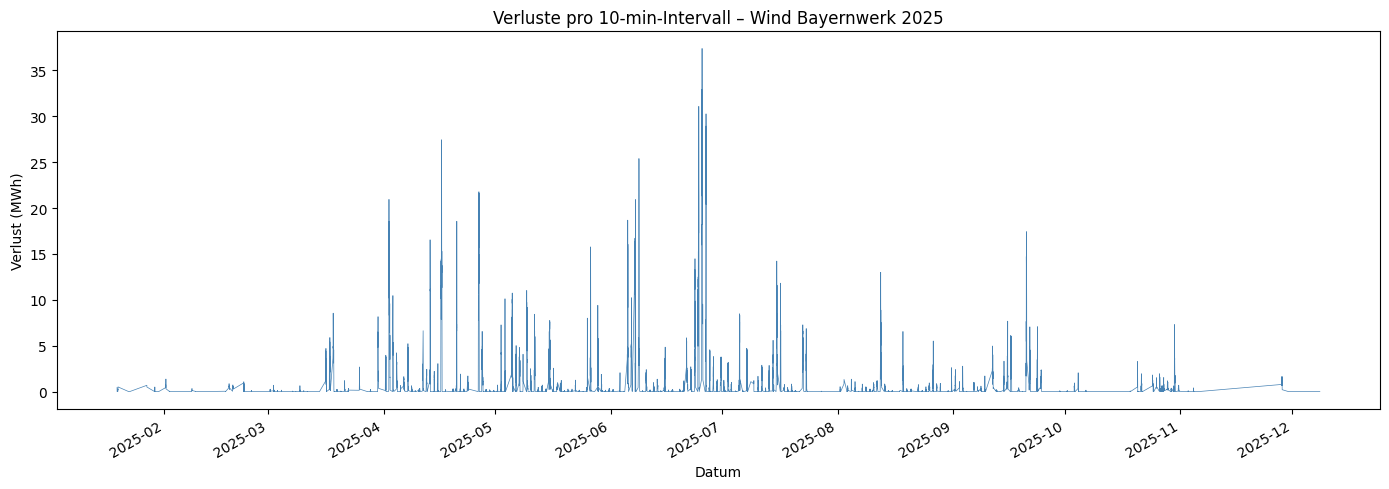

In [3]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_wind["timestamp"], df_wind["verlust_kwh"] / 1e3, linewidth=0.5, color="steelblue")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (MWh)")
ax.set_title("Verluste pro 10-min-Intervall \u2013 Wind Bayernwerk 2025")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

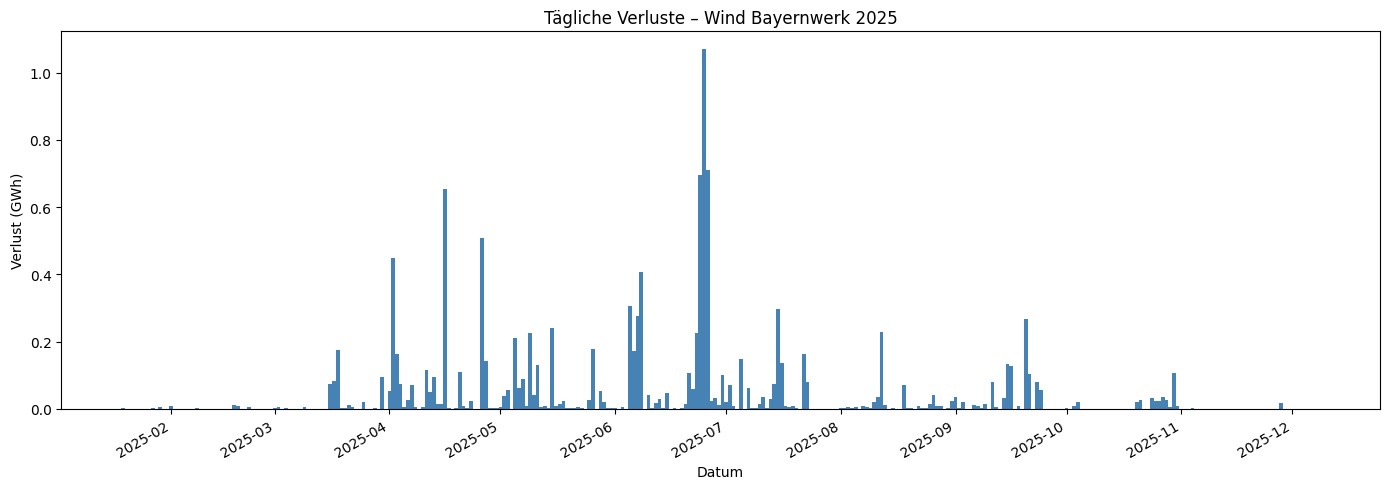

In [4]:
df_wind_daily = df_wind.groupby(df_wind["timestamp"].dt.date)["verlust_kwh"].sum().reset_index()
df_wind_daily.columns = ["tag", "verlust_kwh"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(df_wind_daily["tag"], df_wind_daily["verlust_kwh"] / 1e6, width=1, color="steelblue")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (GWh)")
ax.set_title("T\u00e4gliche Verluste \u2013 Wind Bayernwerk 2025")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Solar Bayernwerk

In [5]:
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

query = """
    SELECT 
        timestamp,
        SUM(verlust) AS verlust_kwh
    FROM dwd.solar_bayernwerk_2025_interpolated
    GROUP BY timestamp
    ORDER BY timestamp
"""
df_solar = pd.read_sql(query, conn)
conn.close()

C:\Users\user\AppData\Local\Temp\ipykernel_20520\3541510362.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_solar = pd.read_sql(query, conn)


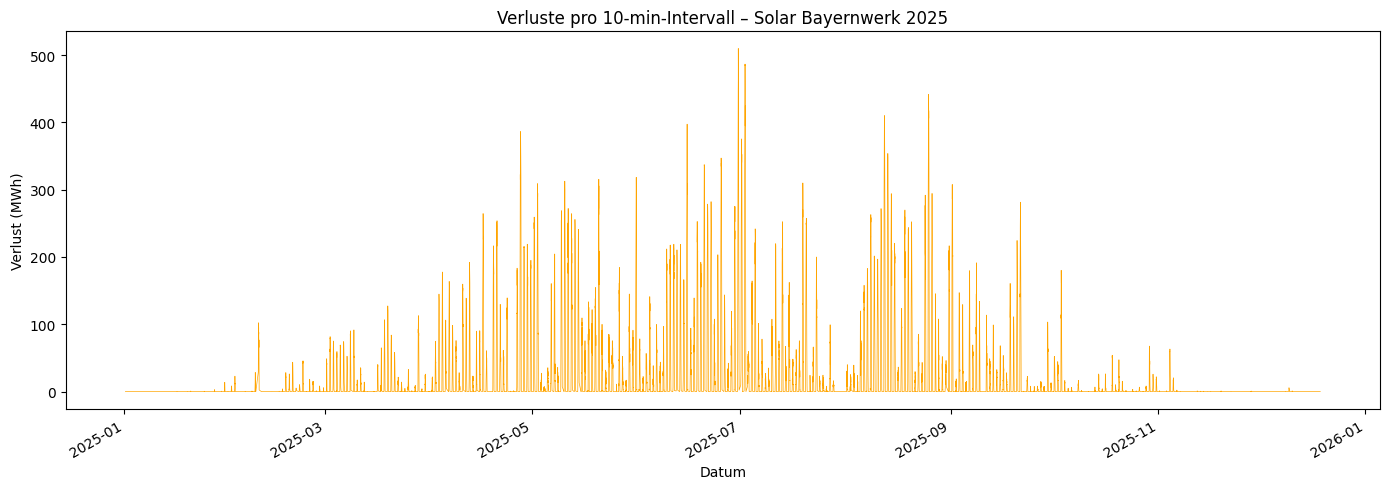

In [6]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_solar["timestamp"], df_solar["verlust_kwh"] / 1e3, linewidth=0.5, color="orange")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (MWh)")
ax.set_title("Verluste pro 10-min-Intervall \u2013 Solar Bayernwerk 2025")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

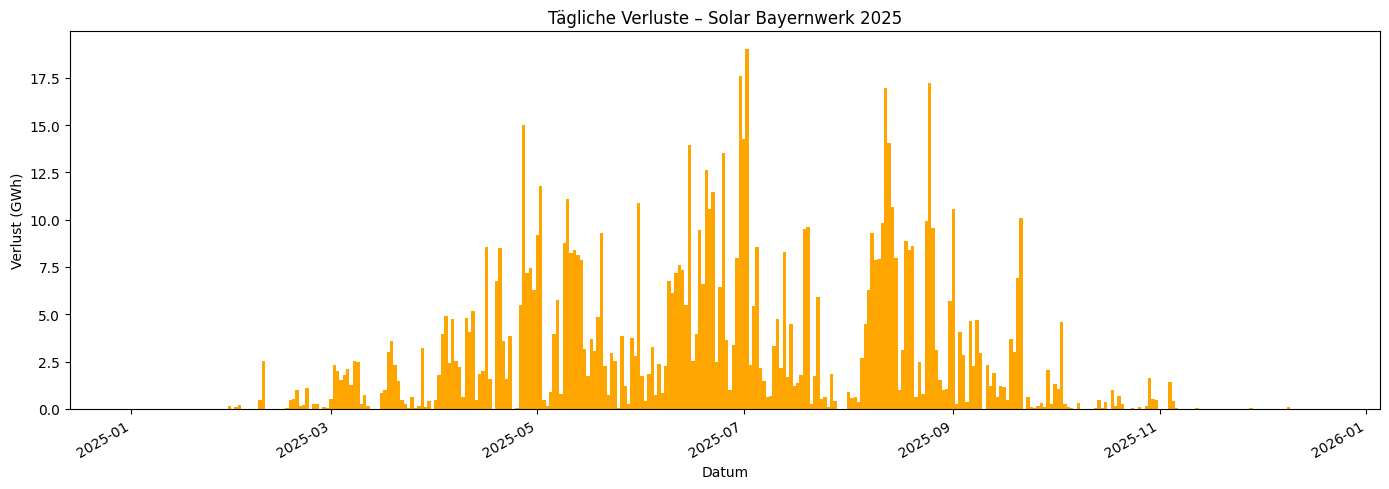

In [7]:
df_solar_daily = df_solar.groupby(df_solar["timestamp"].dt.date)["verlust_kwh"].sum().reset_index()
df_solar_daily.columns = ["tag", "verlust_kwh"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(df_solar_daily["tag"], df_solar_daily["verlust_kwh"] / 1e6, width=1, color="orange")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (GWh)")
ax.set_title("T\u00e4gliche Verluste \u2013 Solar Bayernwerk 2025")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Kombiniert: Wind + Solar Bayernwerk

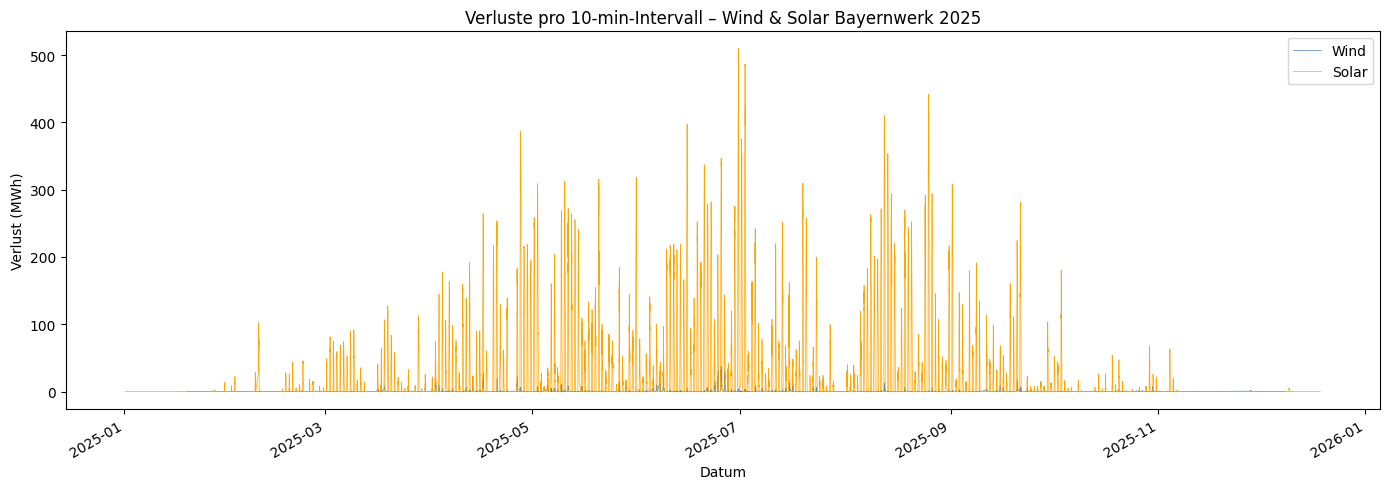

In [8]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_wind["timestamp"], df_wind["verlust_kwh"] / 1e3, linewidth=0.5, color="steelblue", label="Wind")
ax.plot(df_solar["timestamp"], df_solar["verlust_kwh"] / 1e3, linewidth=0.5, color="orange", label="Solar")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (MWh)")
ax.set_title("Verluste pro 10-min-Intervall \u2013 Wind & Solar Bayernwerk 2025")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

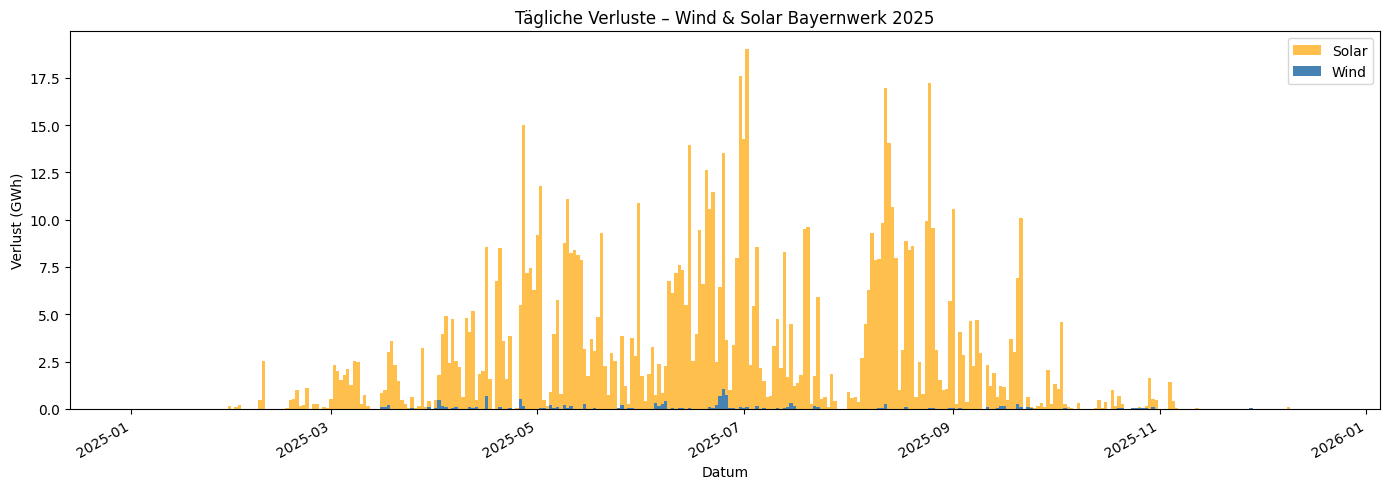

In [9]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(df_solar_daily["tag"], df_solar_daily["verlust_kwh"] / 1e6, width=1, color="orange", alpha=0.7, label="Solar")
ax.bar(df_wind_daily["tag"], df_wind_daily["verlust_kwh"] / 1e6, width=1, color="steelblue", label="Wind")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (GWh)")
ax.set_title("T\u00e4gliche Verluste \u2013 Wind & Solar Bayernwerk 2025")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


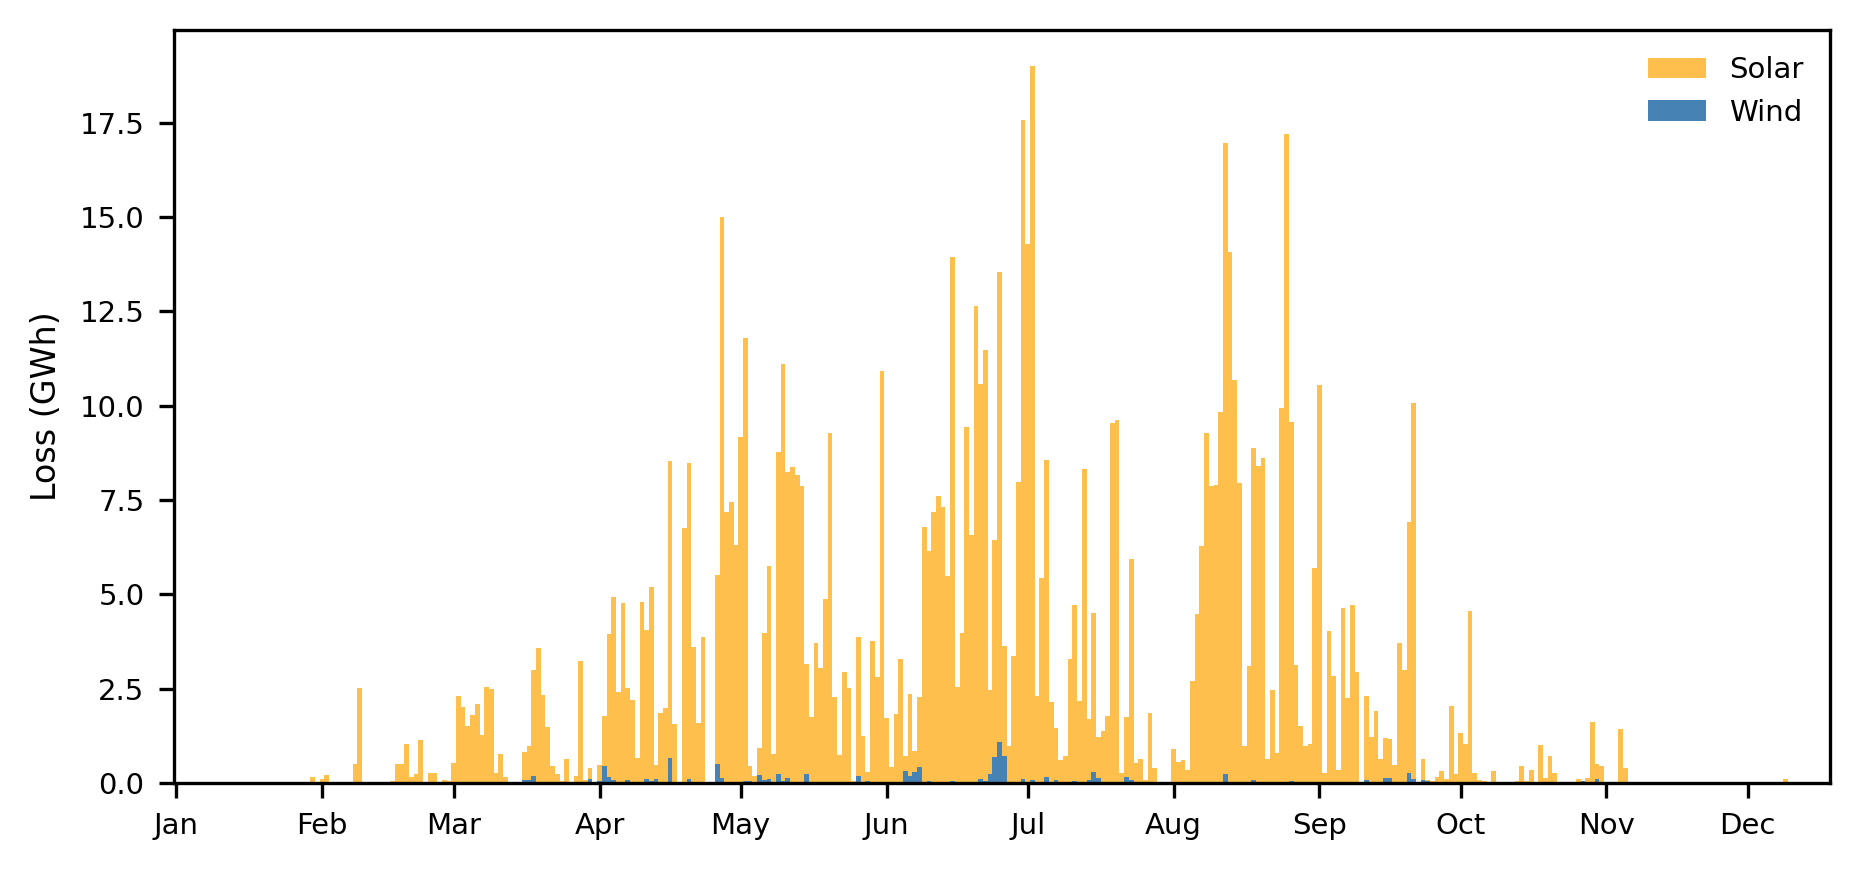

In [14]:
# Figure sized for the A4 text width (16 cm) so it can be embedded without rescaling
fig, ax = plt.subplots(figsize=(6.3, 3.0), dpi=300)
ax.bar(df_solar_daily["tag"], df_solar_daily["verlust_kwh"] / 1e6, width=1, color="orange", alpha=0.7, label="Solar")
ax.bar(df_wind_daily["tag"], df_wind_daily["verlust_kwh"] / 1e6, width=1, color="steelblue", label="Wind")
ax.set_ylabel("Loss (GWh)", fontsize=8)
ax.tick_params(axis="both", labelsize=7)
ax.legend(fontsize=7, frameon=False)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.margins(x=0)
plt.tight_layout()
plt.show()


In [13]:
# total losses
verlust_wind_kwh = df_wind["verlust_kwh"].sum()
verlust_solar_kwh = df_solar["verlust_kwh"].sum()
verlust_gesamt_kwh = verlust_wind_kwh + verlust_solar_kwh

print(f"Gesamt: {verlust_gesamt_kwh:,.2f} kWh | {verlust_gesamt_kwh / 1e3:,.2f} MWh | {verlust_gesamt_kwh / 1e6:,.2f} GWh")
print(f"Wind:   {verlust_wind_kwh:,.2f} kWh | {verlust_wind_kwh / 1e3:,.2f} MWh | {verlust_wind_kwh / 1e6:,.2f} GWh")
print(f"Solar:  {verlust_solar_kwh:,.2f} kWh | {verlust_solar_kwh / 1e3:,.2f} MWh | {verlust_solar_kwh / 1e6:,.2f} GWh")


Gesamt: 878,268,156.76 kWh | 878,268.16 MWh | 878.27 GWh
Wind:   11,987,997.67 kWh | 11,988.00 MWh | 11.99 GWh
Solar:  866,280,159.09 kWh | 866,280.16 MWh | 866.28 GWh


In [17]:
# Kennzahlen für die Abbildungsbeschreibung
df_daily_all = (
    pd.concat([df_wind_daily.assign(quelle="Wind"), df_solar_daily.assign(quelle="Solar")])
    .groupby("tag", as_index=False)["verlust_kwh"].sum()
)

# Tage mit Abregelungsanordnung (Daten vorhanden) vs. Tage mit tatsächlichem Verlust
tage_mit_daten = len(df_daily_all)
tage_mit_verlust = (df_daily_all["verlust_kwh"] > 0).sum()

print(f"Anteil Wind:  {verlust_wind_kwh / verlust_gesamt_kwh:.1%}")
print(f"Anteil Solar: {verlust_solar_kwh / verlust_gesamt_kwh:.1%}")
print(f"Tage mit Abregelungsanordnung: {tage_mit_daten}")
print(f"Tage mit Verlust > 0: {tage_mit_verlust}")
print(f"Mittel pro Anordnungstag: {verlust_gesamt_kwh / tage_mit_daten / 1e6:.3f} GWh")
print(f"Mittel pro Verlusttag:    {verlust_gesamt_kwh / tage_mit_verlust / 1e6:.3f} GWh")

top_days = df_daily_all.nlargest(5, "verlust_kwh")
print("\nTop-5-Tage (GWh):")
print(top_days.assign(gwh=lambda d: d["verlust_kwh"] / 1e6)[["tag", "gwh"]].to_string(index=False))

anteil_top10 = df_daily_all.nlargest(10, "verlust_kwh")["verlust_kwh"].sum() / verlust_gesamt_kwh
print(f"\nAnteil der 10 stärksten Tage am Jahresverlust: {anteil_top10:.1%}")

monat = pd.to_datetime(df_daily_all["tag"]).dt.month
print("\nVerlust pro Monat (GWh):")
print((df_daily_all.groupby(monat)["verlust_kwh"].sum() / 1e6).round(2).to_string())

monat_w = pd.to_datetime(df_wind_daily["tag"]).dt.month
monat_s = pd.to_datetime(df_solar_daily["tag"]).dt.month
print("\nWind pro Monat (GWh):")
print((df_wind_daily.groupby(monat_w)["verlust_kwh"].sum() / 1e6).round(2).to_string())
print("\nSolar pro Monat (GWh):")
print((df_solar_daily.groupby(monat_s)["verlust_kwh"].sum() / 1e6).round(2).to_string())


Anteil Wind:  1.4%
Anteil Solar: 98.6%
Tage mit Abregelungsanordnung: 344
Tage mit Verlust > 0: 294
Mittel pro Anordnungstag: 2.553 GWh
Mittel pro Verlusttag:    2.987 GWh

Top-5-Tage (GWh):
       tag       gwh
2025-07-02 19.083153
2025-06-30 17.680724
2025-08-25 17.221066
2025-08-12 17.188640
2025-04-27 15.132053

Anteil der 10 stärksten Tage am Jahresverlust: 17.8%

Verlust pro Monat (GWh):
tag
1       0.22
2       7.58
3      35.60
4     120.42
5     144.18
6     185.49
7     115.32
8     183.80
9      69.76
10     13.81
11      1.97
12      0.13

Wind pro Monat (GWh):
tag
1     0.01
2     0.04
3     0.48
4     2.60
5     1.47
6     4.36
7     1.18
8     0.52
9     0.98
10    0.34
11    0.02
12    0.00

Solar pro Monat (GWh):
tag
1       0.22
2       7.54
3      35.12
4     117.81
5     142.71
6     181.13
7     114.14
8     183.29
9      68.78
10     13.46
11      1.95
12      0.13


## Grid connection points with the highest curtailment loss

In [4]:
import numpy as np

# Shared figure style for the thesis: A4 text width (16 cm) so figures need no rescaling
FIGSIZE = (6.3, 3.0)
DPI = 300
FS_LABEL, FS_TICK, FS_TITLE = 8, 7, 9
COLOR_DSO = "darkorange"        # Bayernwerk colour for all single-series figures


def scale_energy(values_kwh):
    """Scale energy values given in kWh to kWh/MWh/GWh/TWh and return (values, unit)."""
    peak = float(np.nanmax(np.abs(np.asarray(values_kwh, dtype=float)))) if len(values_kwh) else 0.0
    for faktor, einheit in ((1e9, "TWh"), (1e6, "GWh"), (1e3, "MWh")):
        if peak >= faktor:
            return values_kwh / faktor, einheit
    return values_kwh, "kWh"


def scale_power(values_kw):
    """Scale power values given in kW to kW/MW/GW and return (values, unit)."""
    peak = float(np.nanmax(np.abs(np.asarray(values_kw, dtype=float)))) if len(values_kw) else 0.0
    for faktor, einheit in ((1e6, "GW"), (1e3, "MW")):
        if peak >= faktor:
            return values_kw / faktor, einheit
    return values_kw, "kW"


C:\Users\user\AppData\Local\Temp\ipykernel_6012\1744195774.py:21: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_top = pd.read_sql(query_top, conn)


,grid connection,total loss (GWh)
0,SEL921912871635,27.36
1,SEL966883065133,25.87
2,SEL946403455972,25.00
3,SEL984190354412,23.30
4,SEL983097014405,22.86
5,SEL967833167709,21.79
6,SEL908751168898,14.69
7,SEL987958667335,13.26
8,SEL965650034839,11.14
9,SEL920198484980,8.86


C:\Users\user\AppData\Local\Temp\ipykernel_6012\1744195774.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


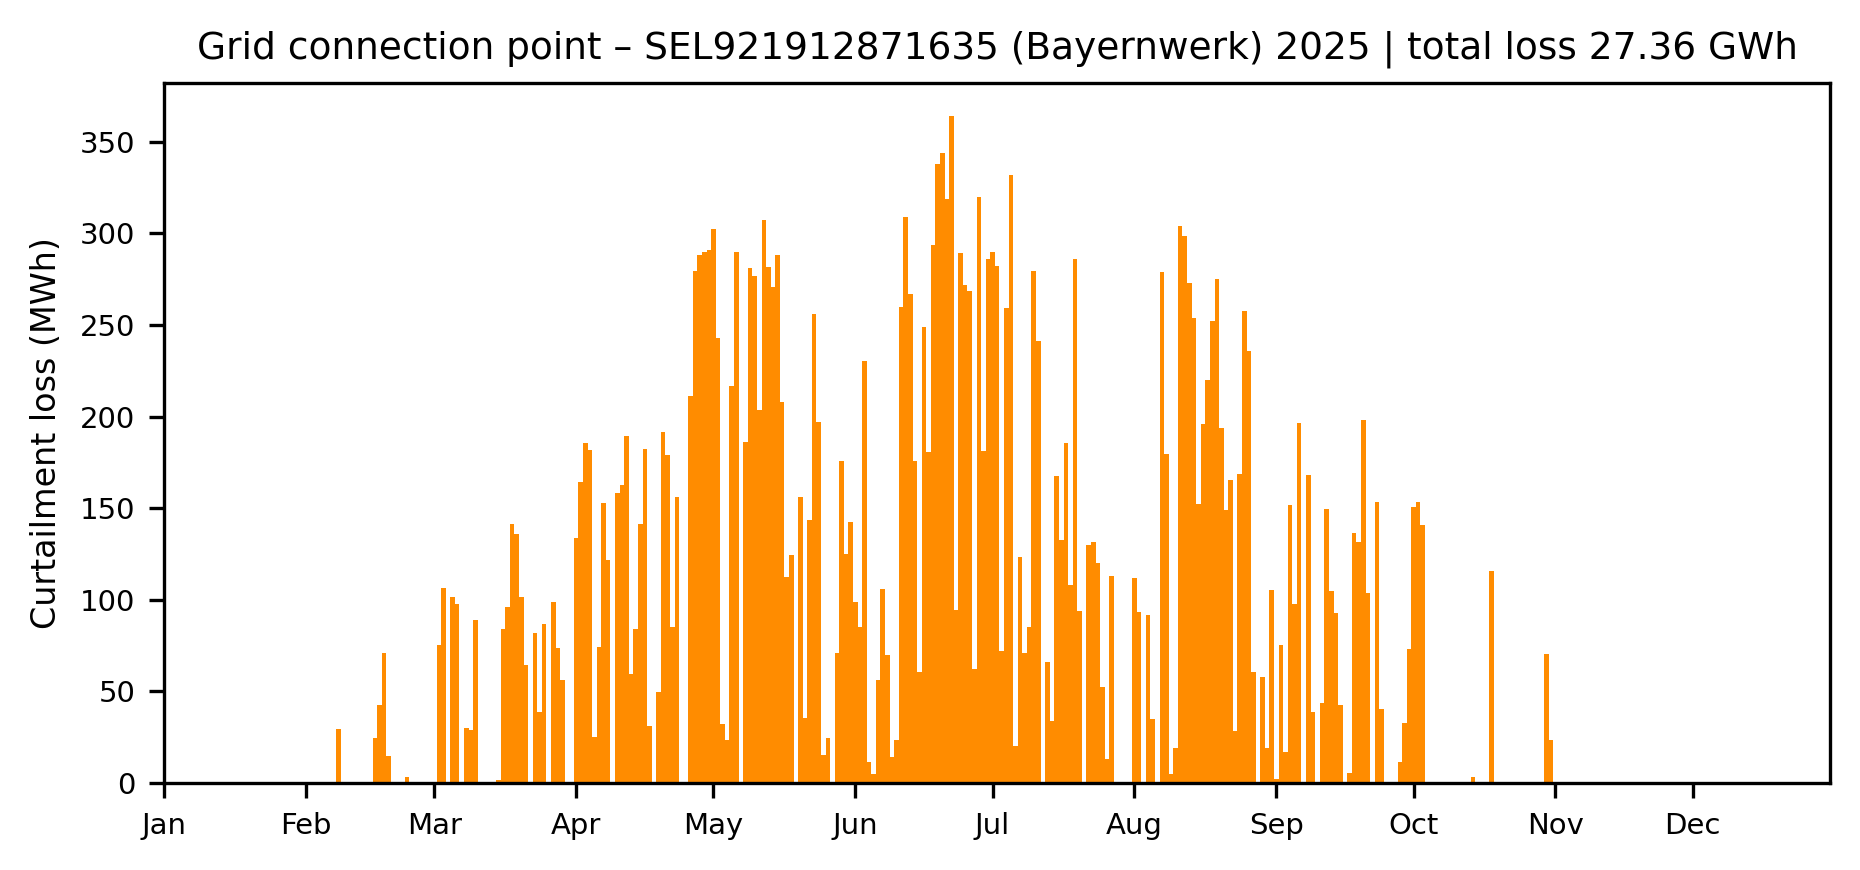

C:\Users\user\AppData\Local\Temp\ipykernel_6012\1744195774.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


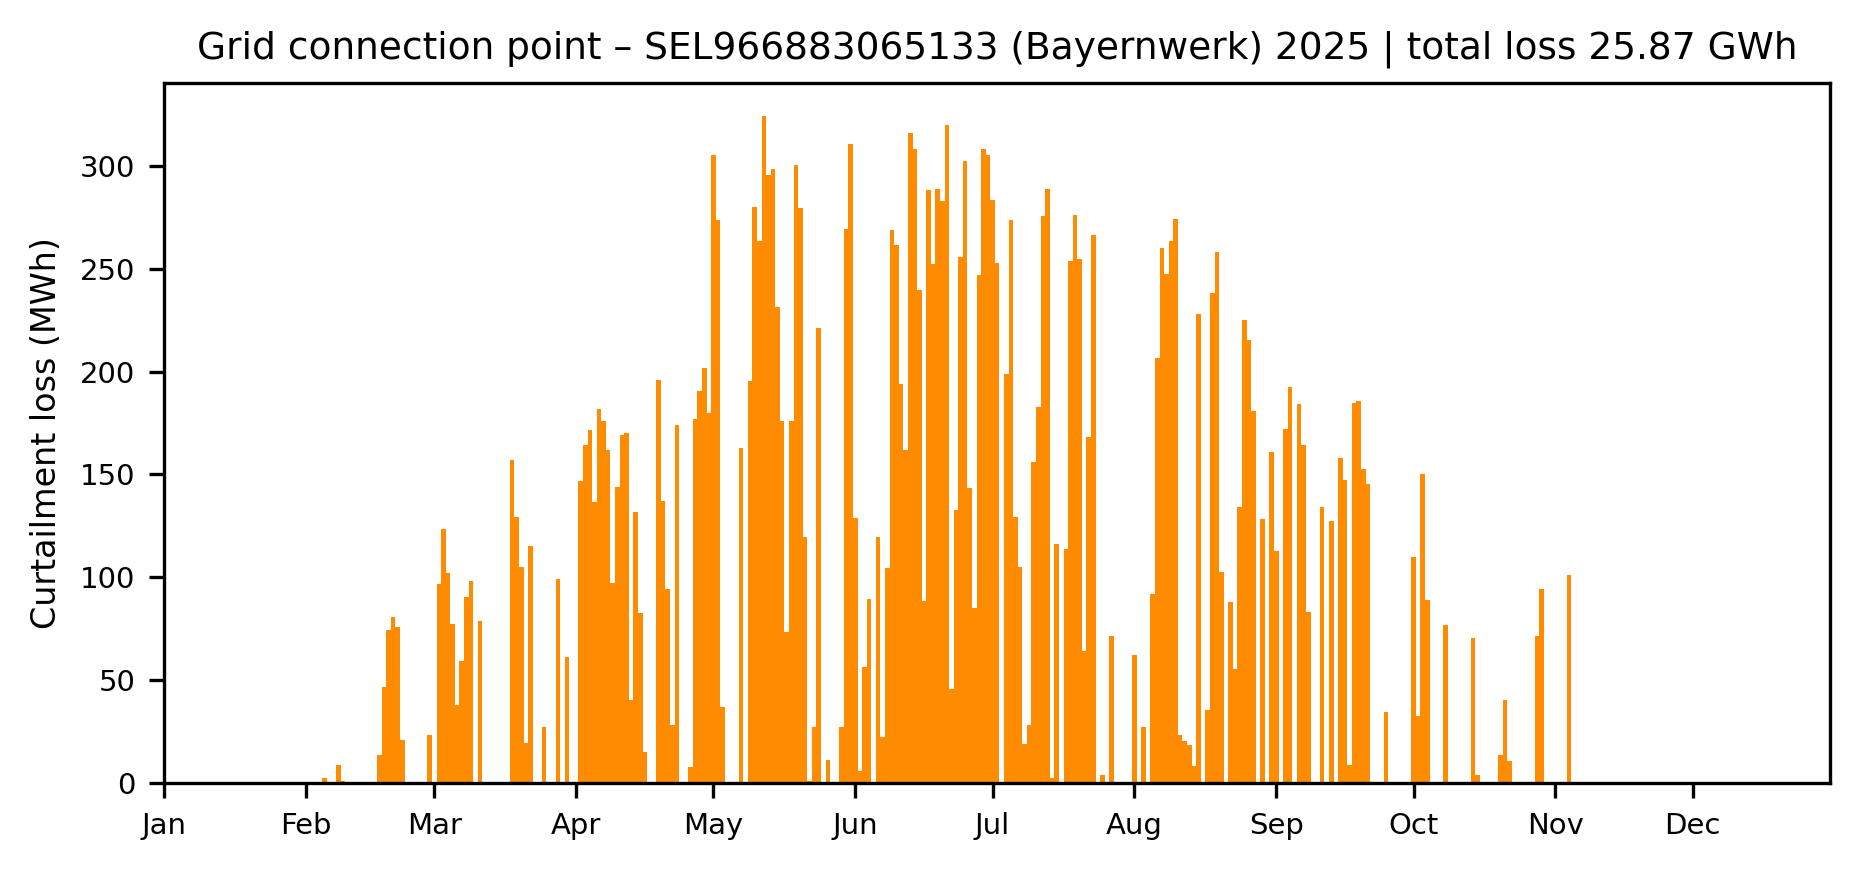

C:\Users\user\AppData\Local\Temp\ipykernel_6012\1744195774.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


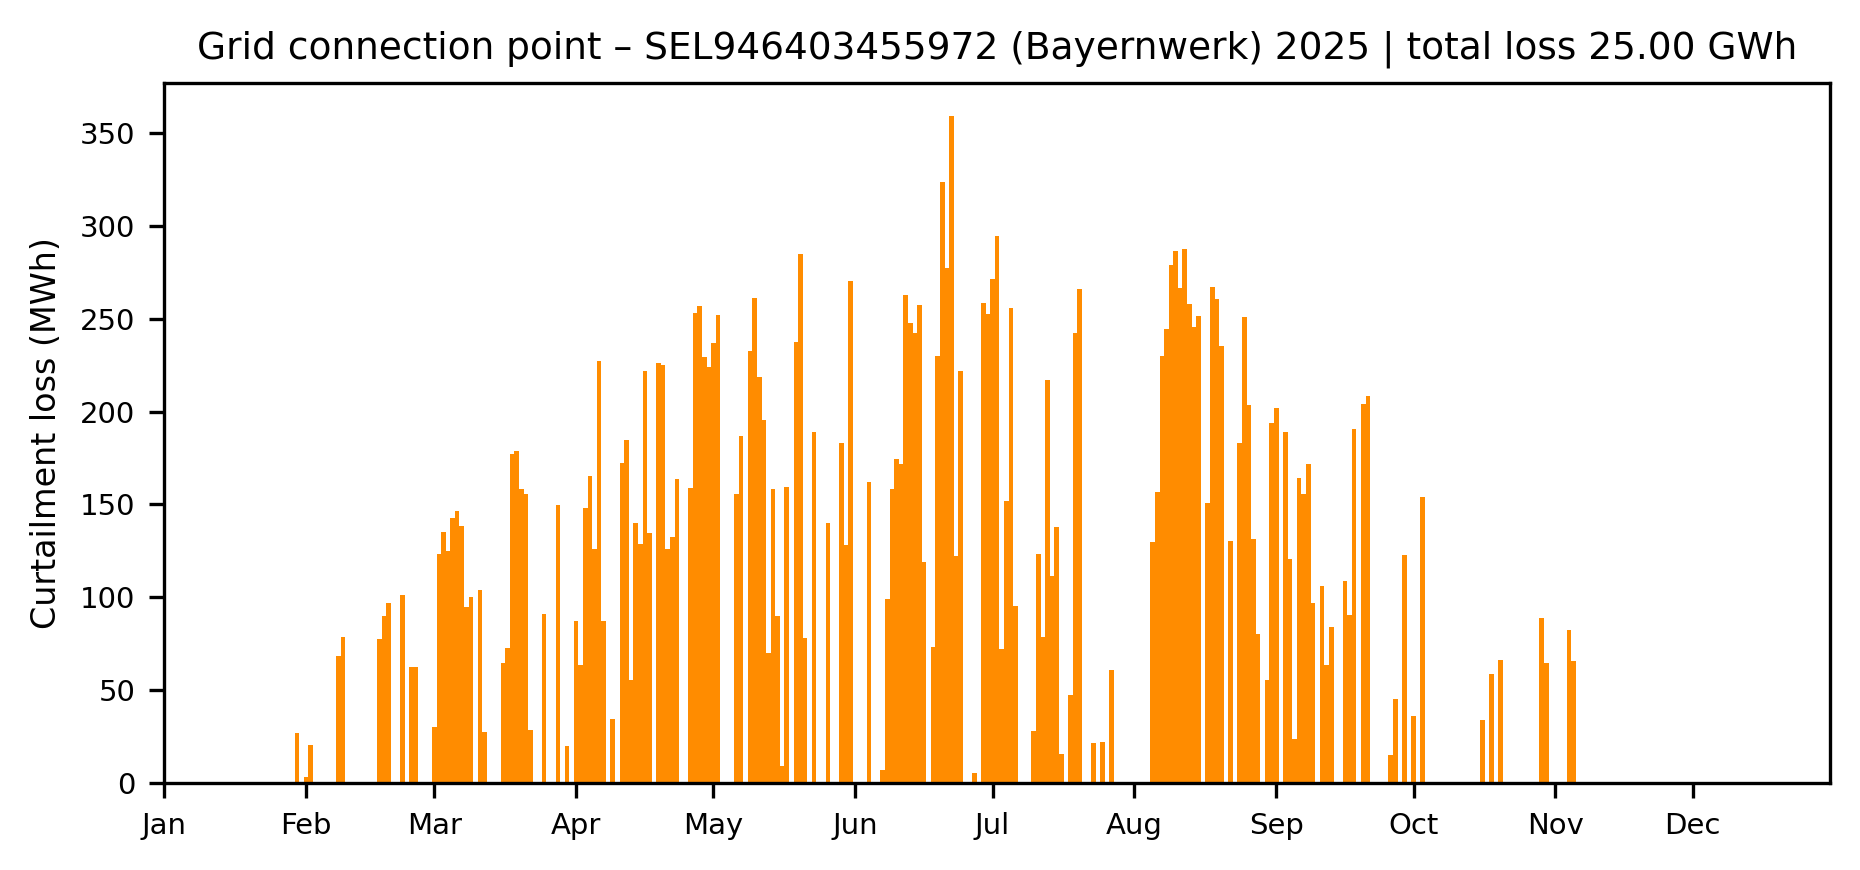

C:\Users\user\AppData\Local\Temp\ipykernel_6012\1744195774.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


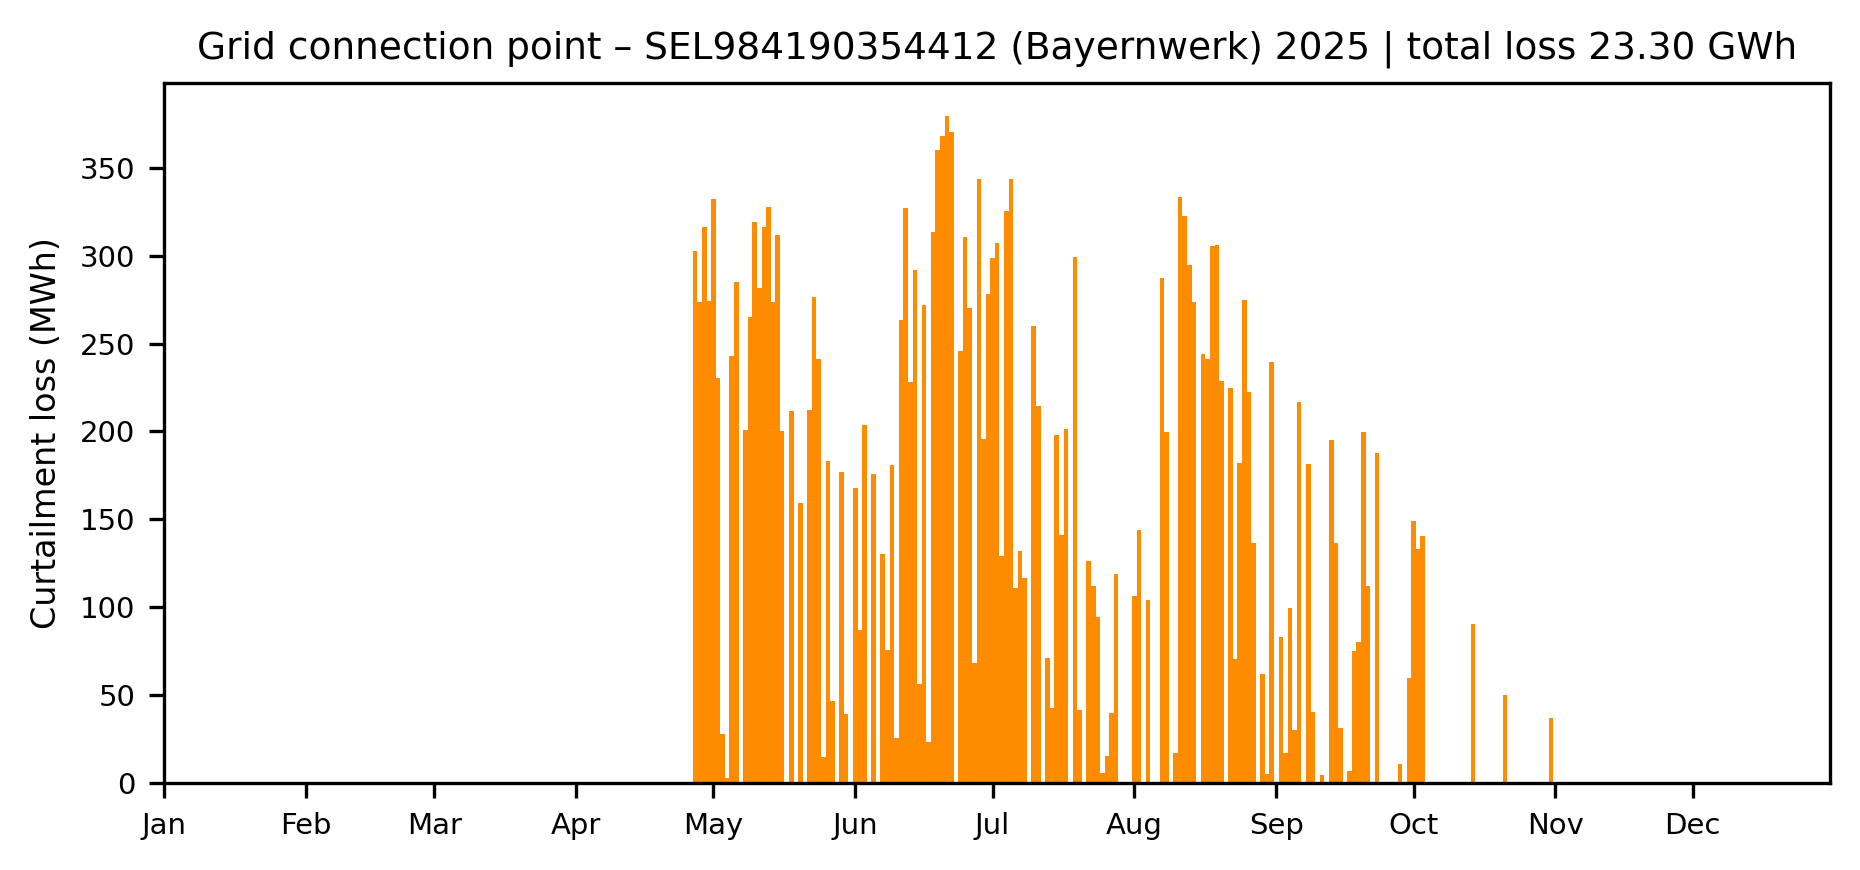

C:\Users\user\AppData\Local\Temp\ipykernel_6012\1744195774.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


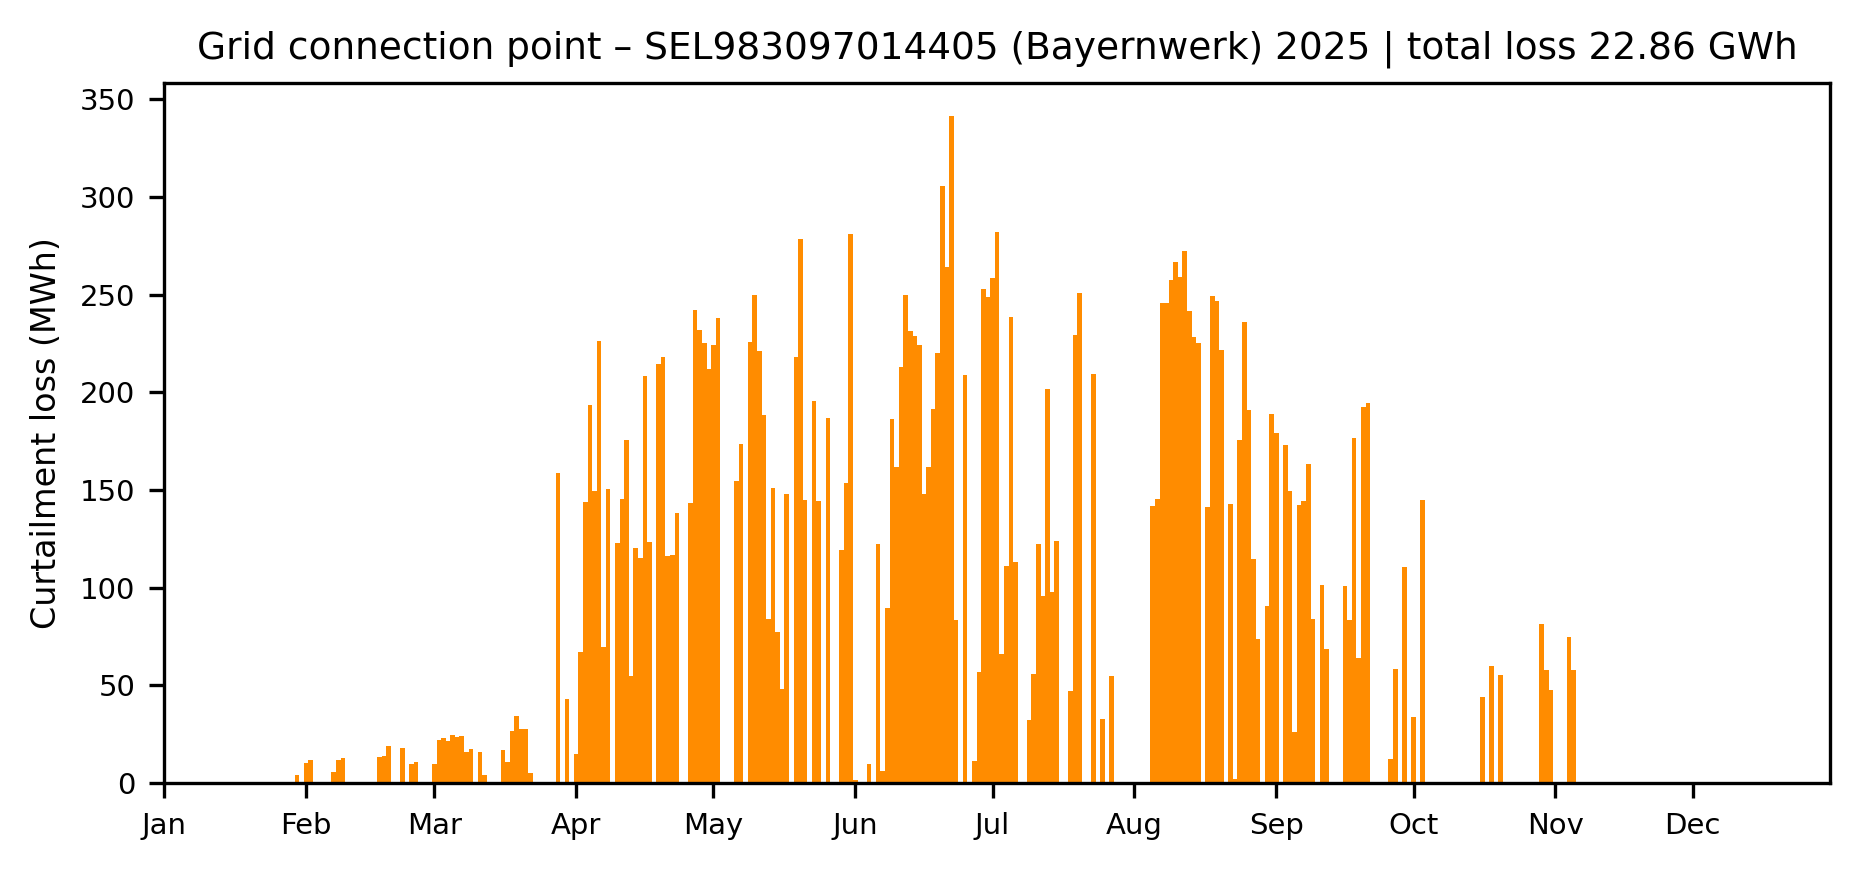

C:\Users\user\AppData\Local\Temp\ipykernel_6012\1744195774.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


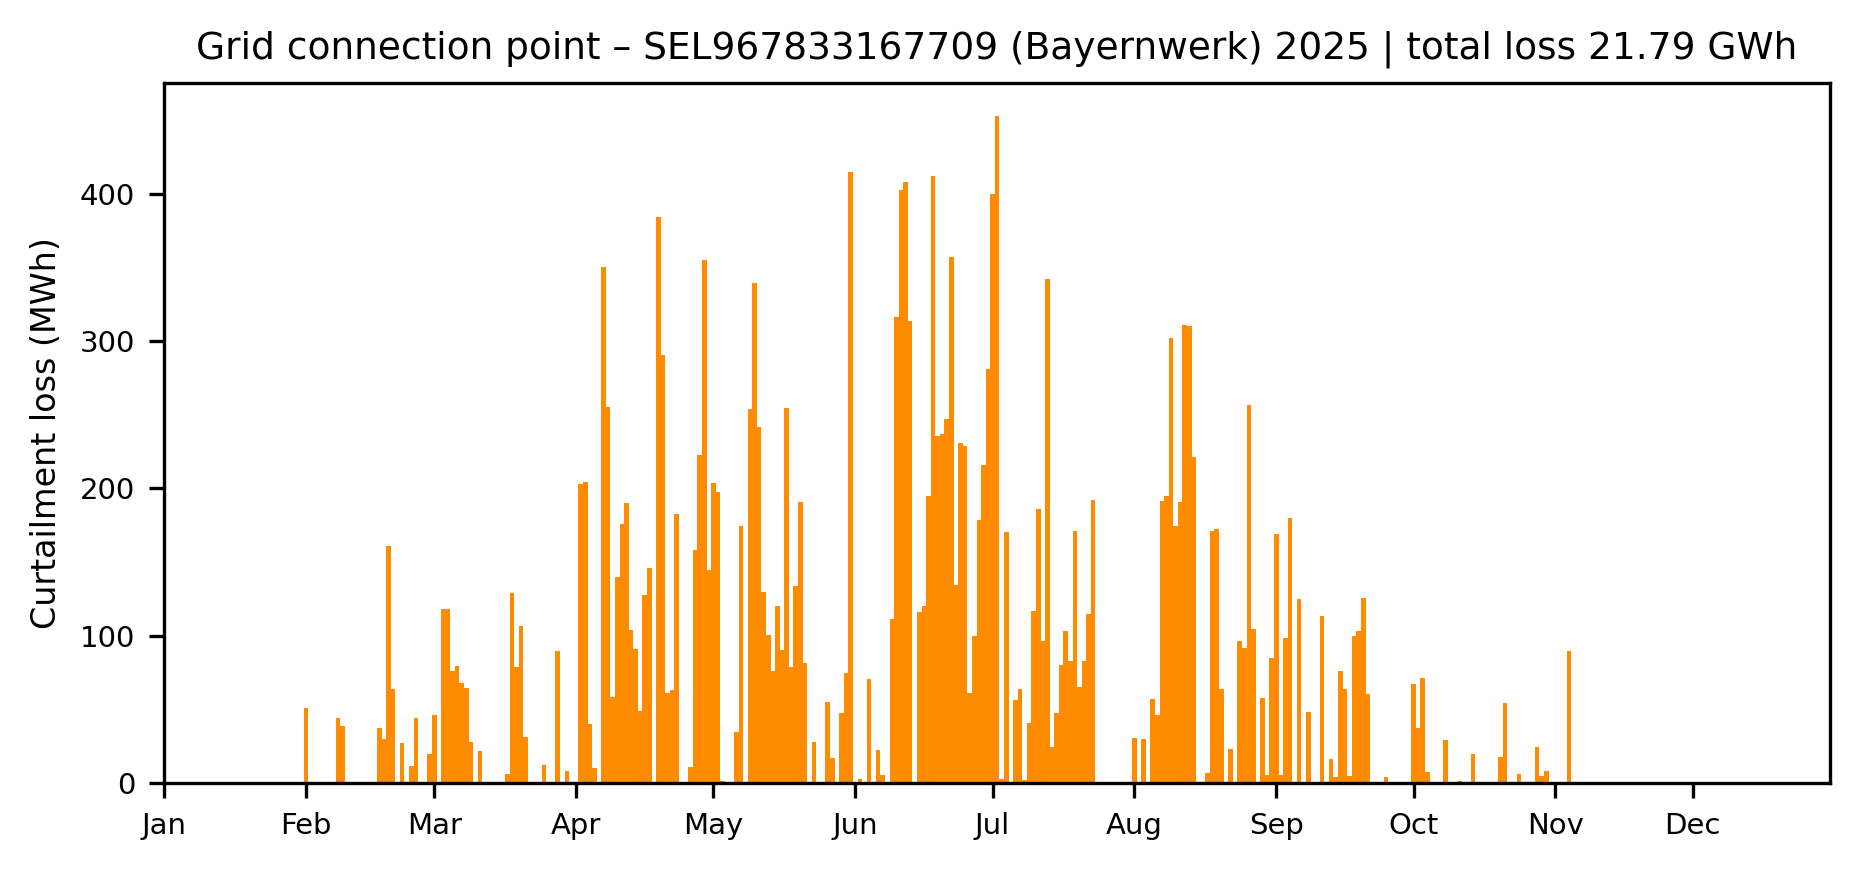

C:\Users\user\AppData\Local\Temp\ipykernel_6012\1744195774.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


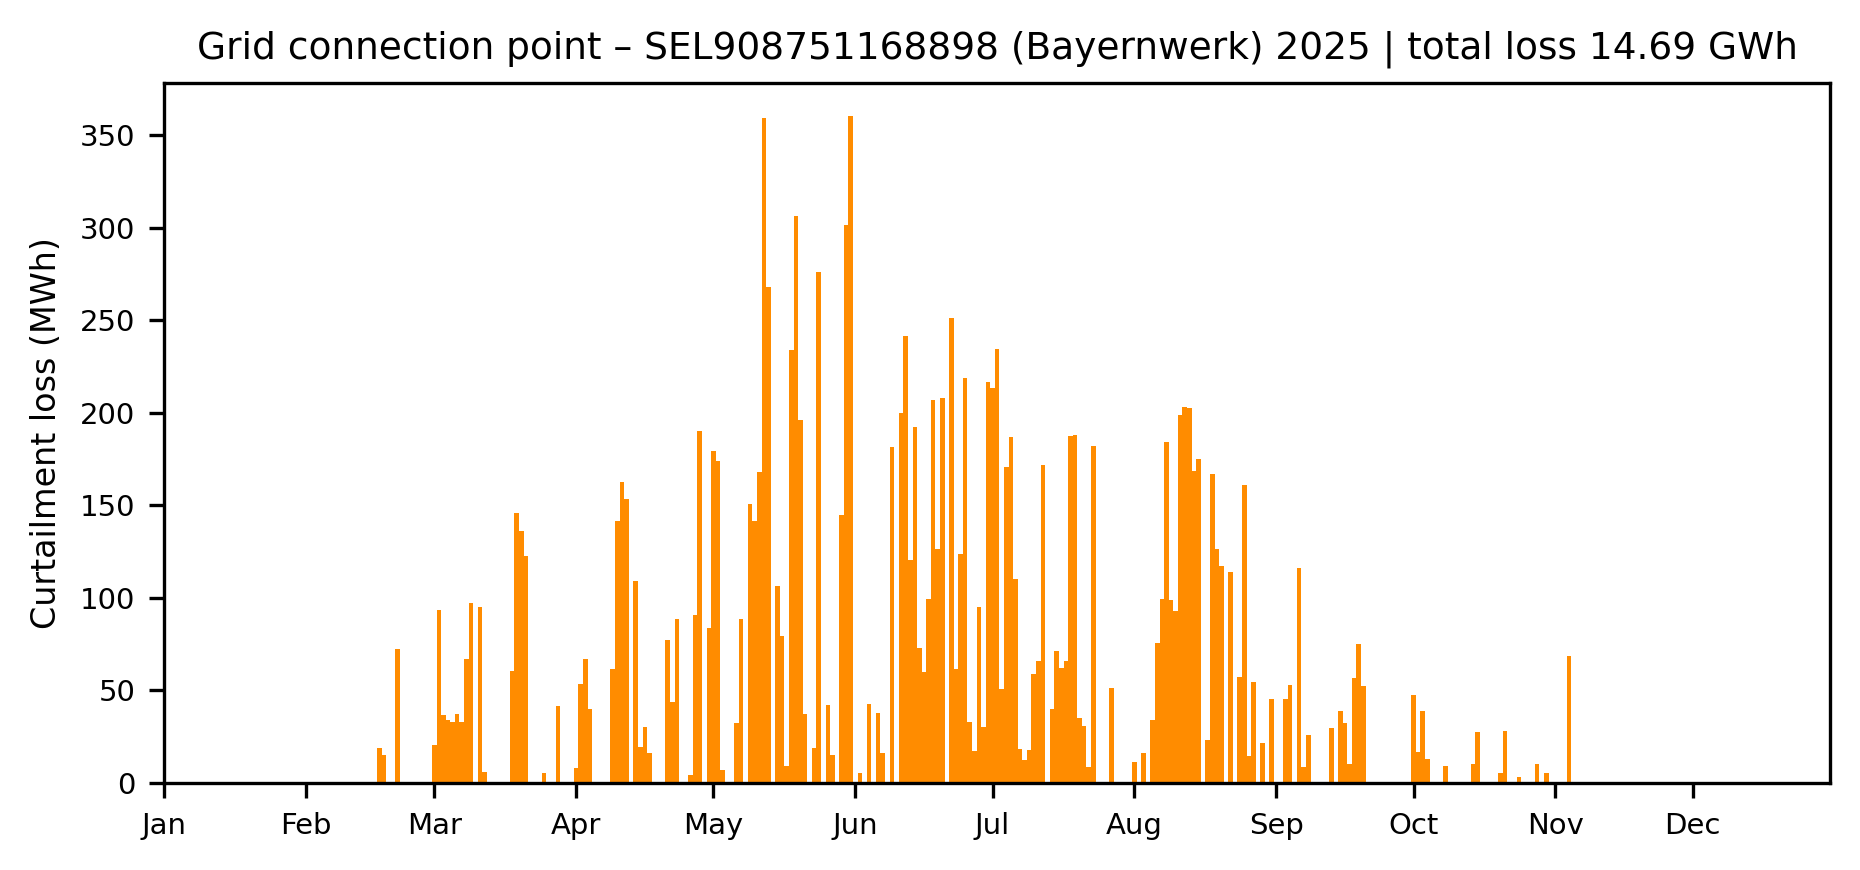

C:\Users\user\AppData\Local\Temp\ipykernel_6012\1744195774.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


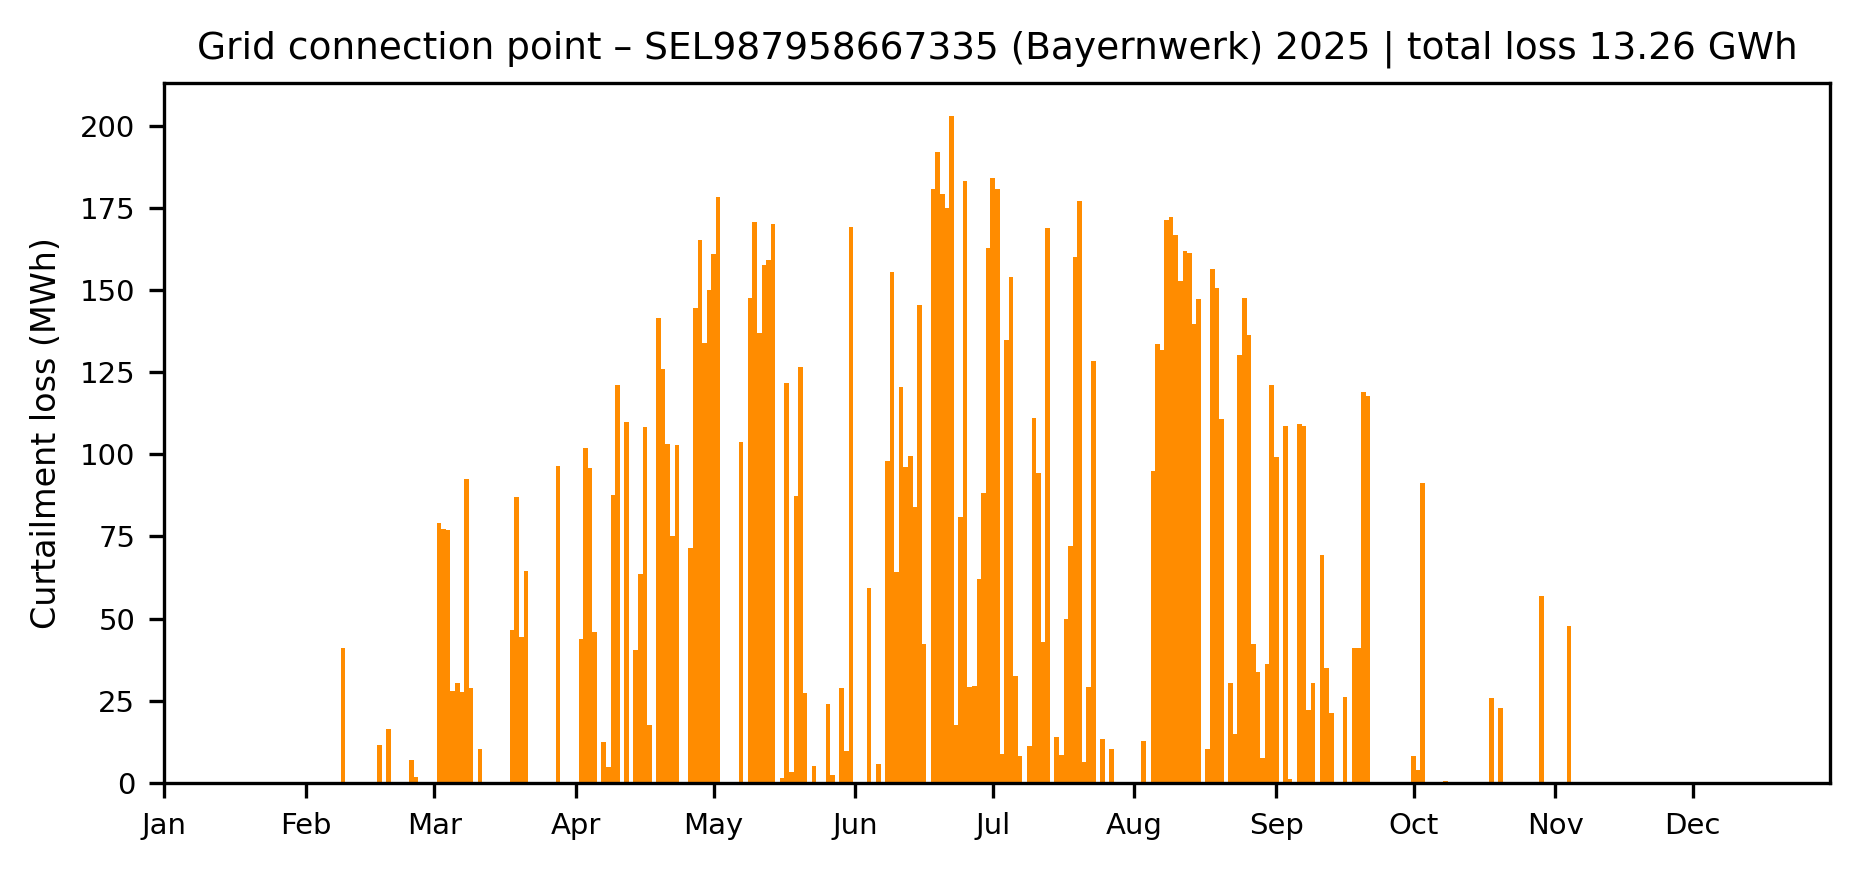

C:\Users\user\AppData\Local\Temp\ipykernel_6012\1744195774.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


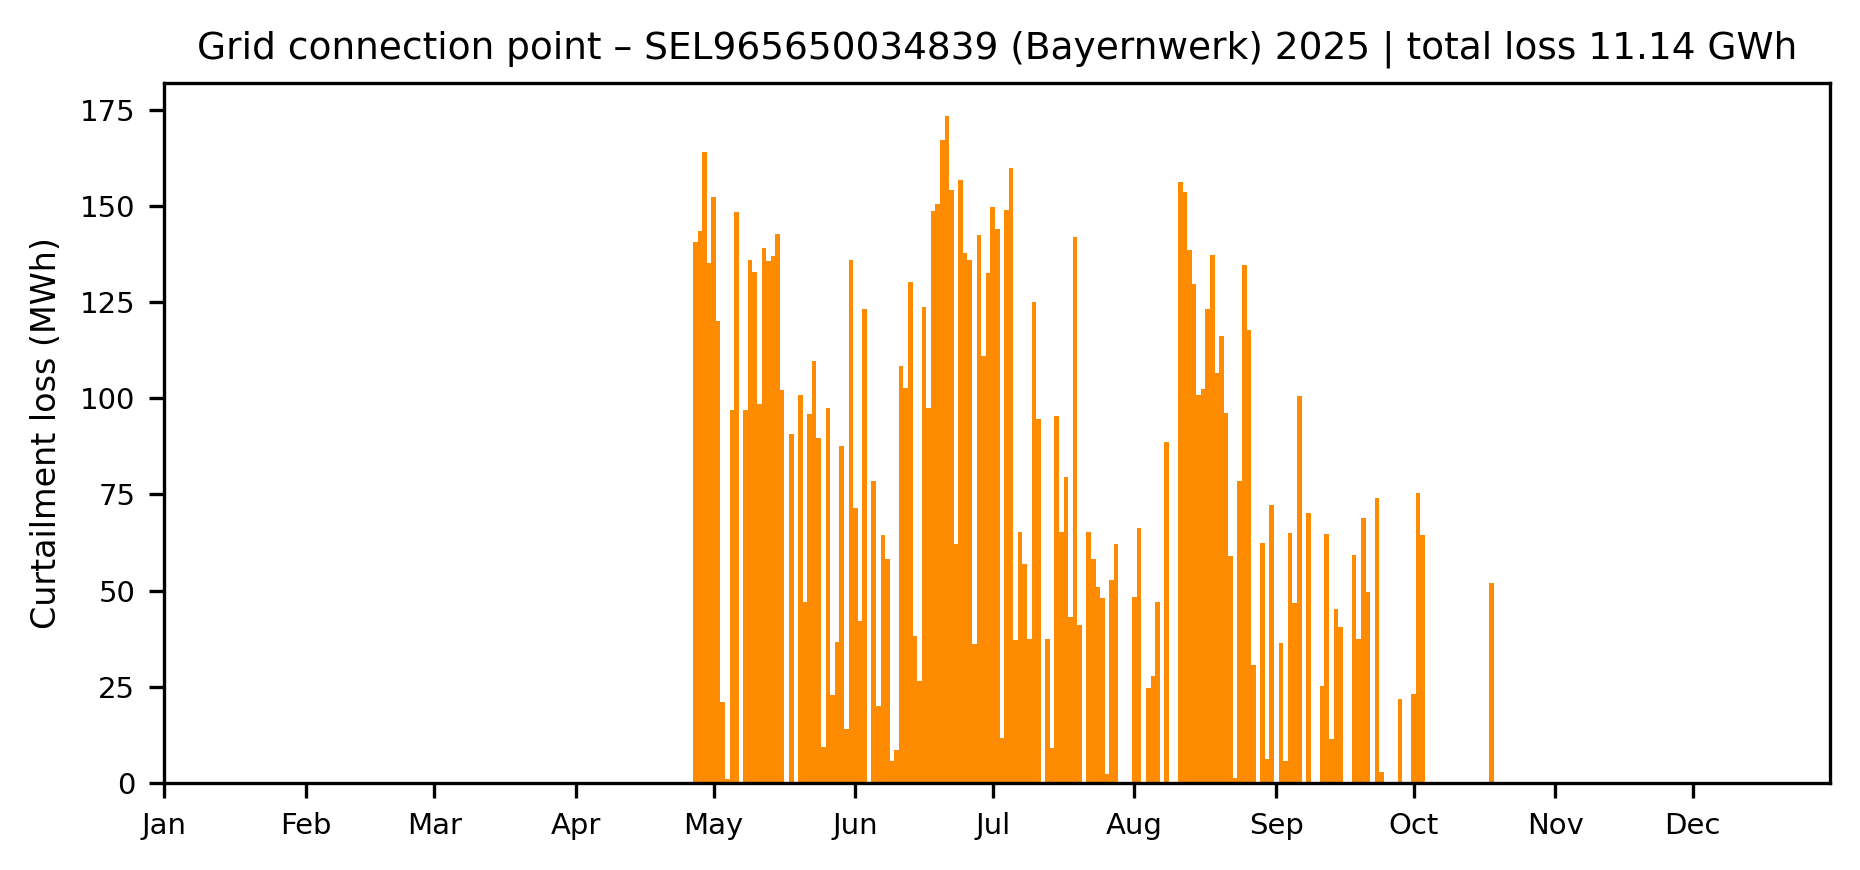

C:\Users\user\AppData\Local\Temp\ipykernel_6012\1744195774.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


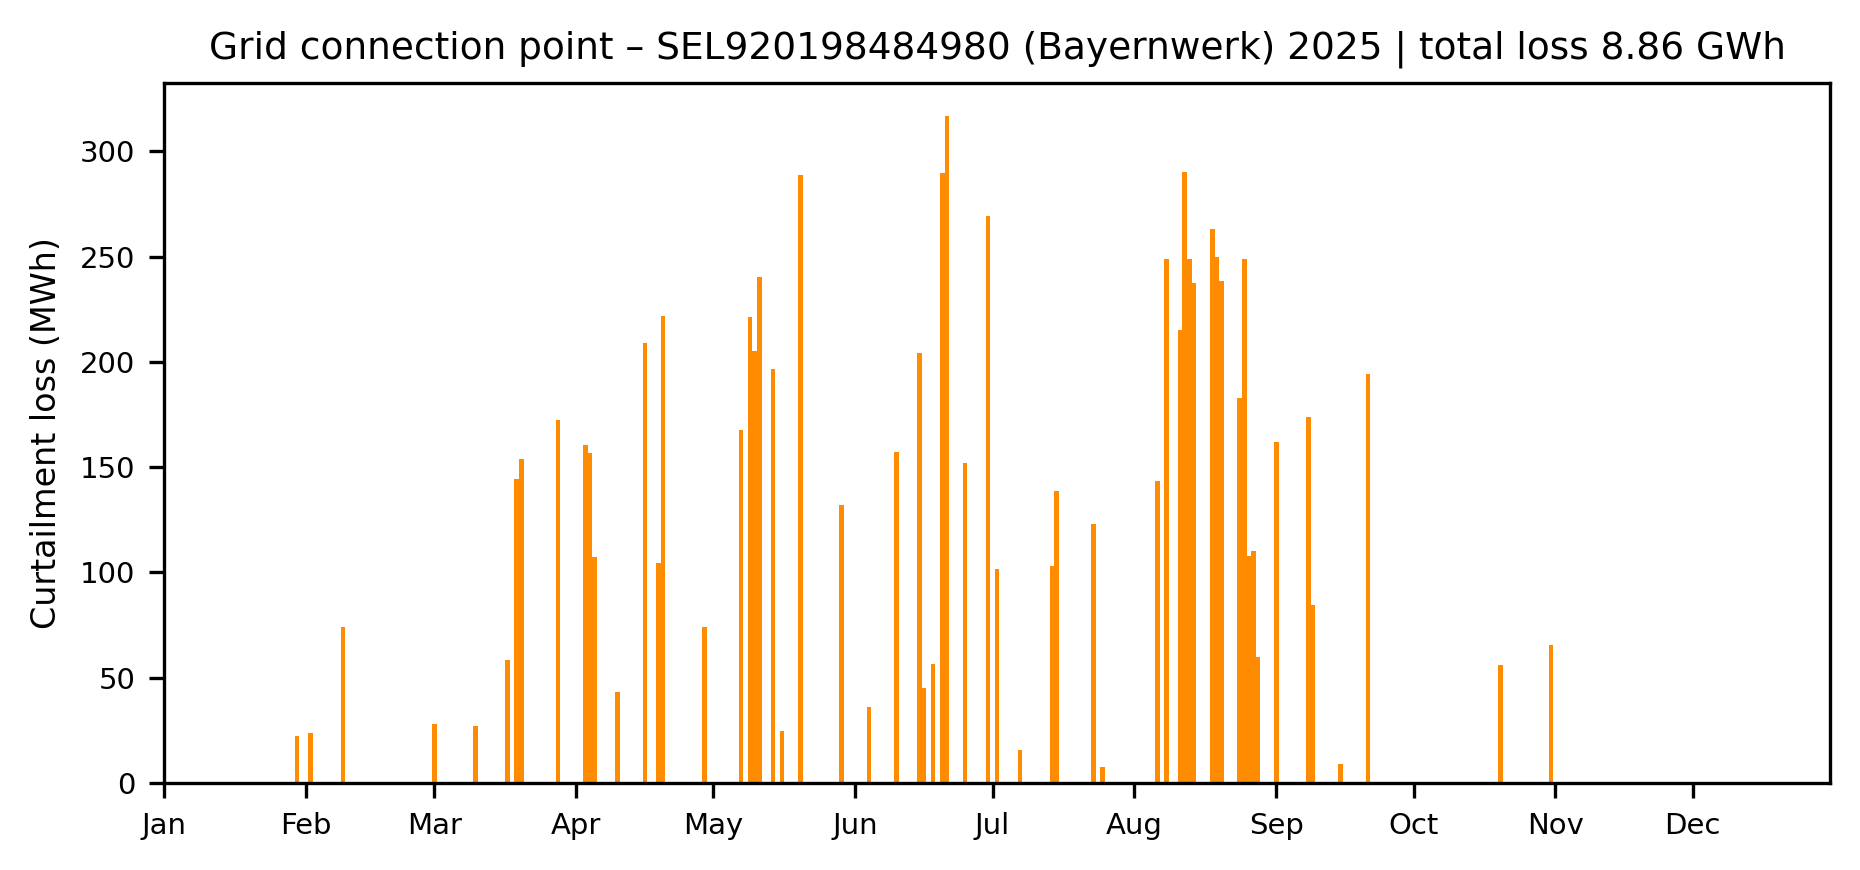

In [5]:
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

query_top = """
    SELECT
        netzanschluss,
        SUM(verlust) AS verlust_kwh_gesamt
    FROM redispatch.redispatch_eeg_bayernwerk
    WHERE verlust > 0
      AND netzanschluss IS NOT NULL
    GROUP BY netzanschluss
    ORDER BY verlust_kwh_gesamt DESC
    LIMIT 10
"""
df_top = pd.read_sql(query_top, conn)

werte_top, einheit_top = scale_energy(df_top["verlust_kwh_gesamt"])
display(
    pd.DataFrame({
        "grid connection": df_top["netzanschluss"],
        f"total loss ({einheit_top})": werte_top.round(2),
    })
)

netzanschluesse = df_top["netzanschluss"].tolist()

start = datetime(2025, 1, 1)
end = datetime(2025, 12, 31)

for netzanschluss in netzanschluesse:
    query = """
        SELECT 
            DATE(star) AS tag,
            SUM(verlust) AS verlust_kwh
        FROM redispatch.redispatch_eeg_bayernwerk
        WHERE netzanschluss = %s
          AND verlust > 0
        GROUP BY DATE(star)
        ORDER BY DATE(star)
    """
    df_daily = pd.read_sql(query, conn, params=(netzanschluss,))

    if df_daily.empty:
        print(f"No data for {netzanschluss}")
        continue

    df_daily["tag"] = pd.to_datetime(df_daily["tag"])
    df_daily = df_daily.set_index("tag")
    idx = pd.date_range(start, end, freq="D")
    df_daily = df_daily.reindex(idx, fill_value=0)
    df_daily = df_daily.reset_index().rename(columns={"index": "tag"})

    gesamt_kwh = df_top.loc[df_top["netzanschluss"] == netzanschluss, "verlust_kwh_gesamt"].values[0]
    gesamt_wert, gesamt_einheit = scale_energy(pd.Series([gesamt_kwh]))
    werte, einheit = scale_energy(df_daily["verlust_kwh"])

    fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI)
    ax.bar(df_daily["tag"], werte, width=1, color="darkorange")
    ax.set_ylabel(f"Curtailment loss ({einheit})", fontsize=FS_LABEL)
    ax.set_title(f"Grid connection point – {netzanschluss} (Bayernwerk) 2025 "
                 f"| total loss {gesamt_wert.iloc[0]:,.2f} {gesamt_einheit}", fontsize=FS_TITLE)
    ax.set_xlim([start, end])
    ax.tick_params(axis="both", labelsize=FS_TICK)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.margins(x=0)
    plt.tight_layout()
    plt.show()

conn.close()


## Grid connection points with the most curtailment days

C:\Users\user\AppData\Local\Temp\ipykernel_3416\4003592409.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_top_days = pd.read_sql(query_top_days, conn)


,grid connection,curtailment days,total loss (GWh)
0,SEL992718014014,238,5.71
1,SEL907734400598,231,2.67
2,SEL905942775040,230,2.58
3,SEL950546433735,211,3.94
4,SEL937166065850,211,4.54
5,SEL939457871720,198,2.36
6,SEL921912871635,196,27.36
7,SEL966883065133,186,25.87
8,SEL967833167709,185,21.79
9,SEL961115295814,184,0.68


C:\Users\user\AppData\Local\Temp\ipykernel_3416\4003592409.py:49: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


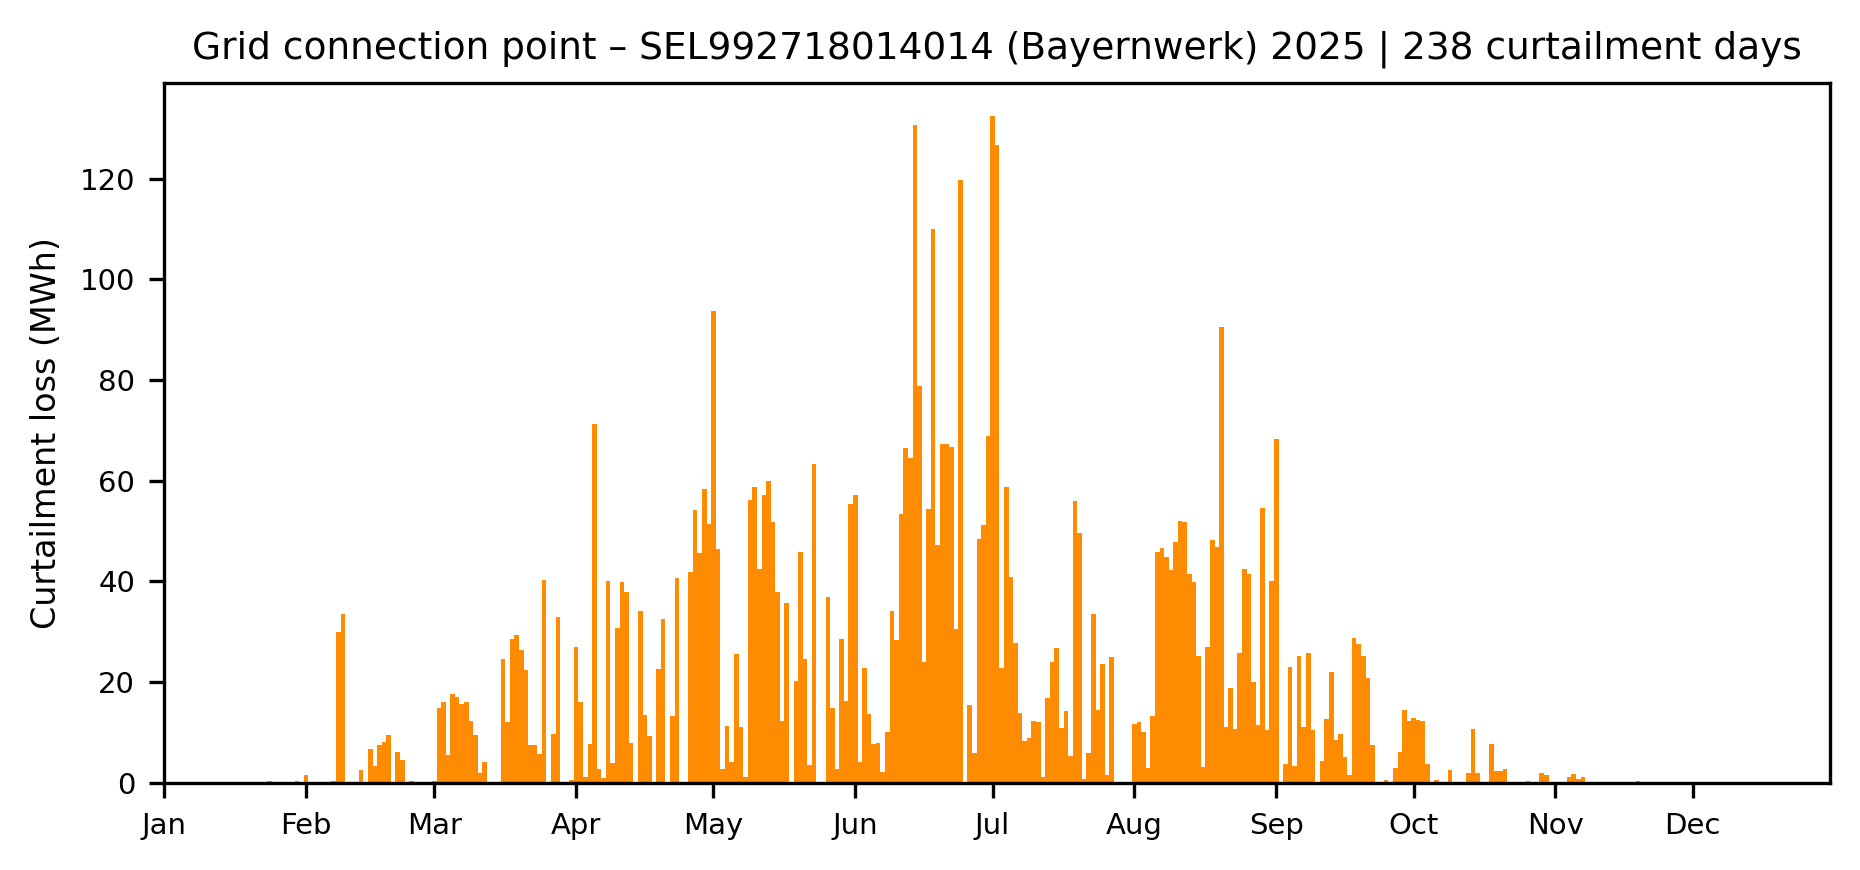

C:\Users\user\AppData\Local\Temp\ipykernel_3416\4003592409.py:49: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


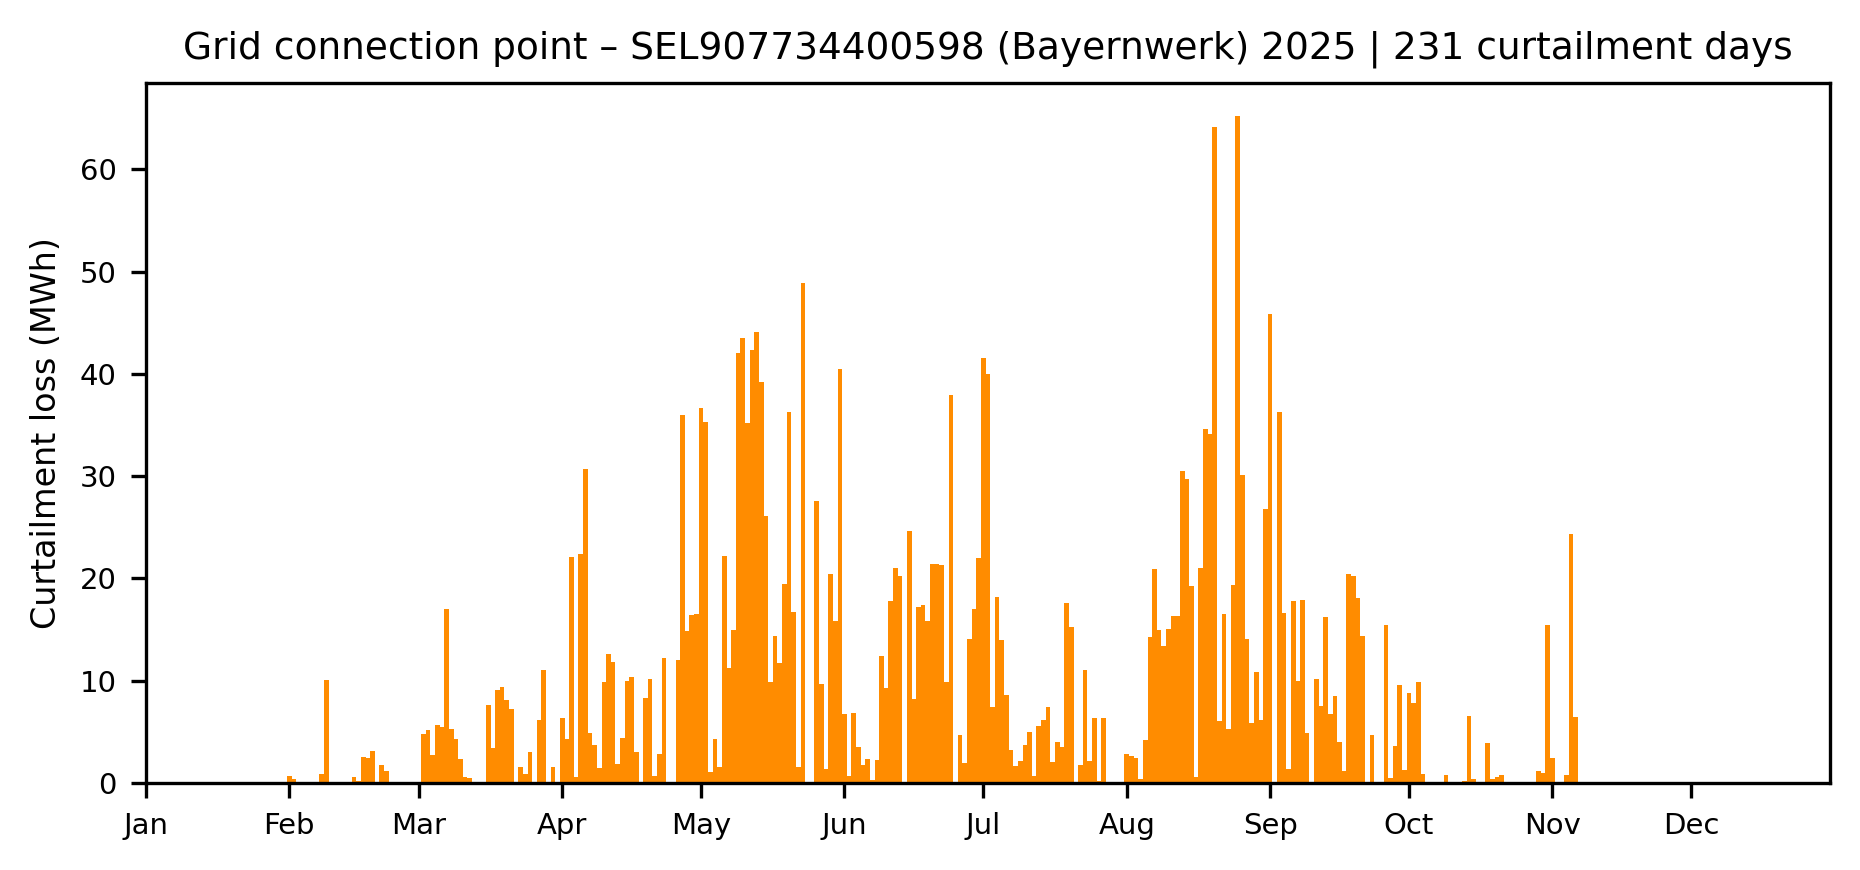

C:\Users\user\AppData\Local\Temp\ipykernel_3416\4003592409.py:49: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


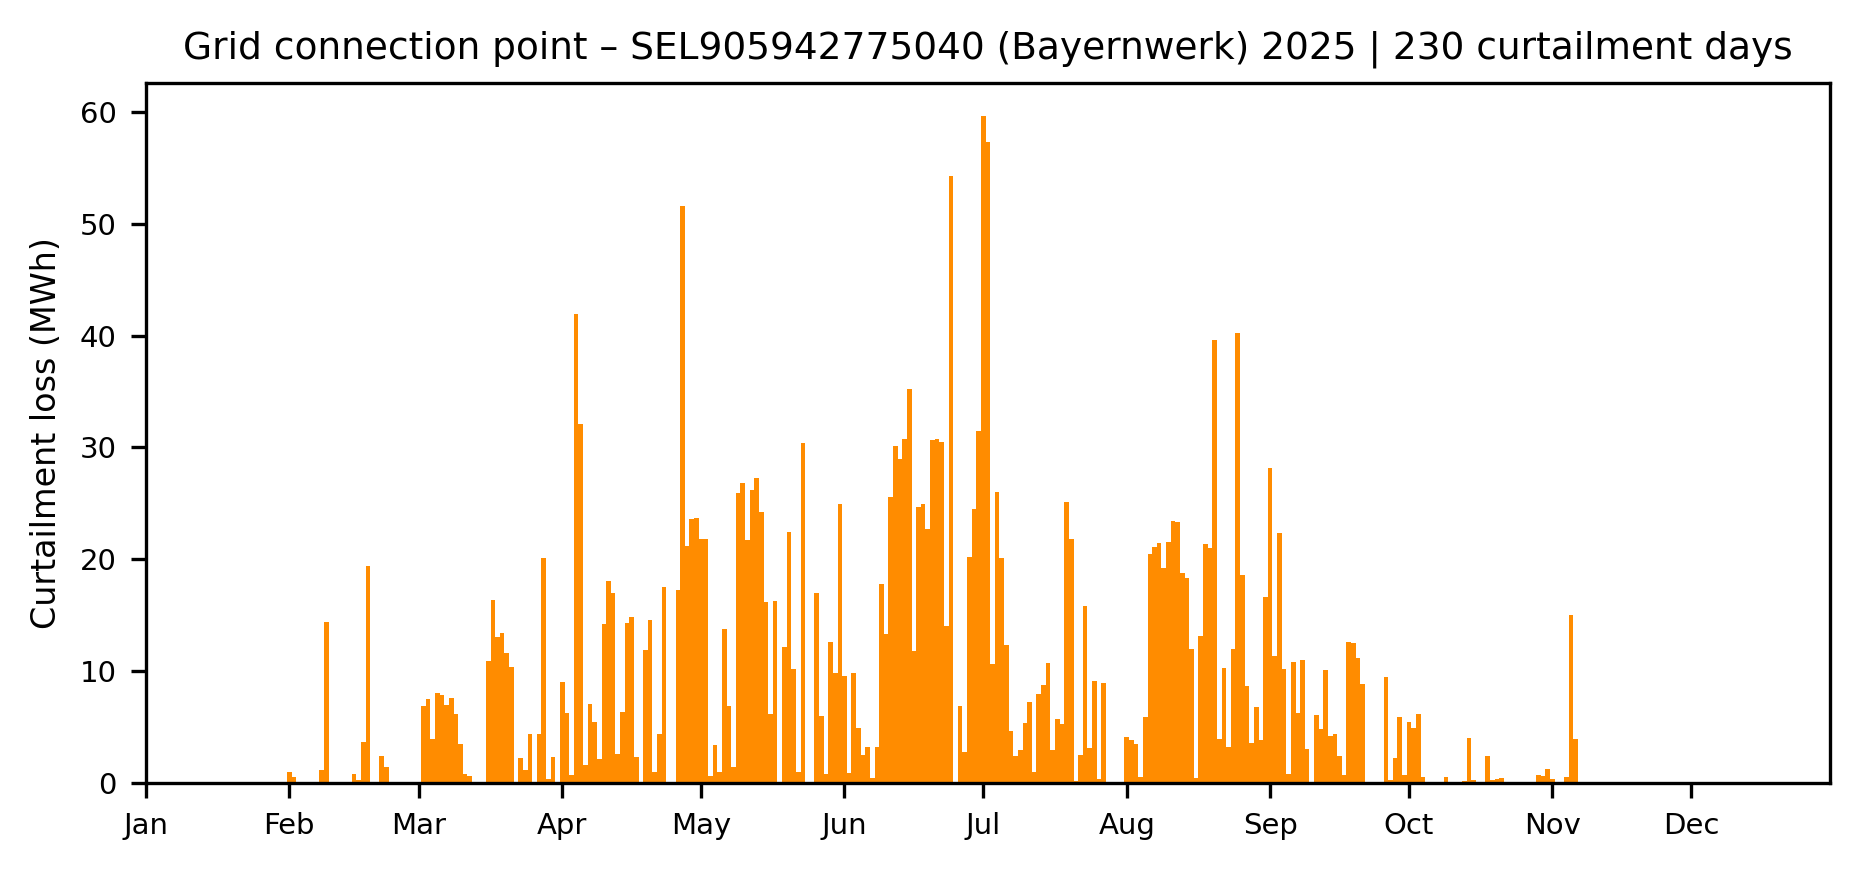

C:\Users\user\AppData\Local\Temp\ipykernel_3416\4003592409.py:49: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


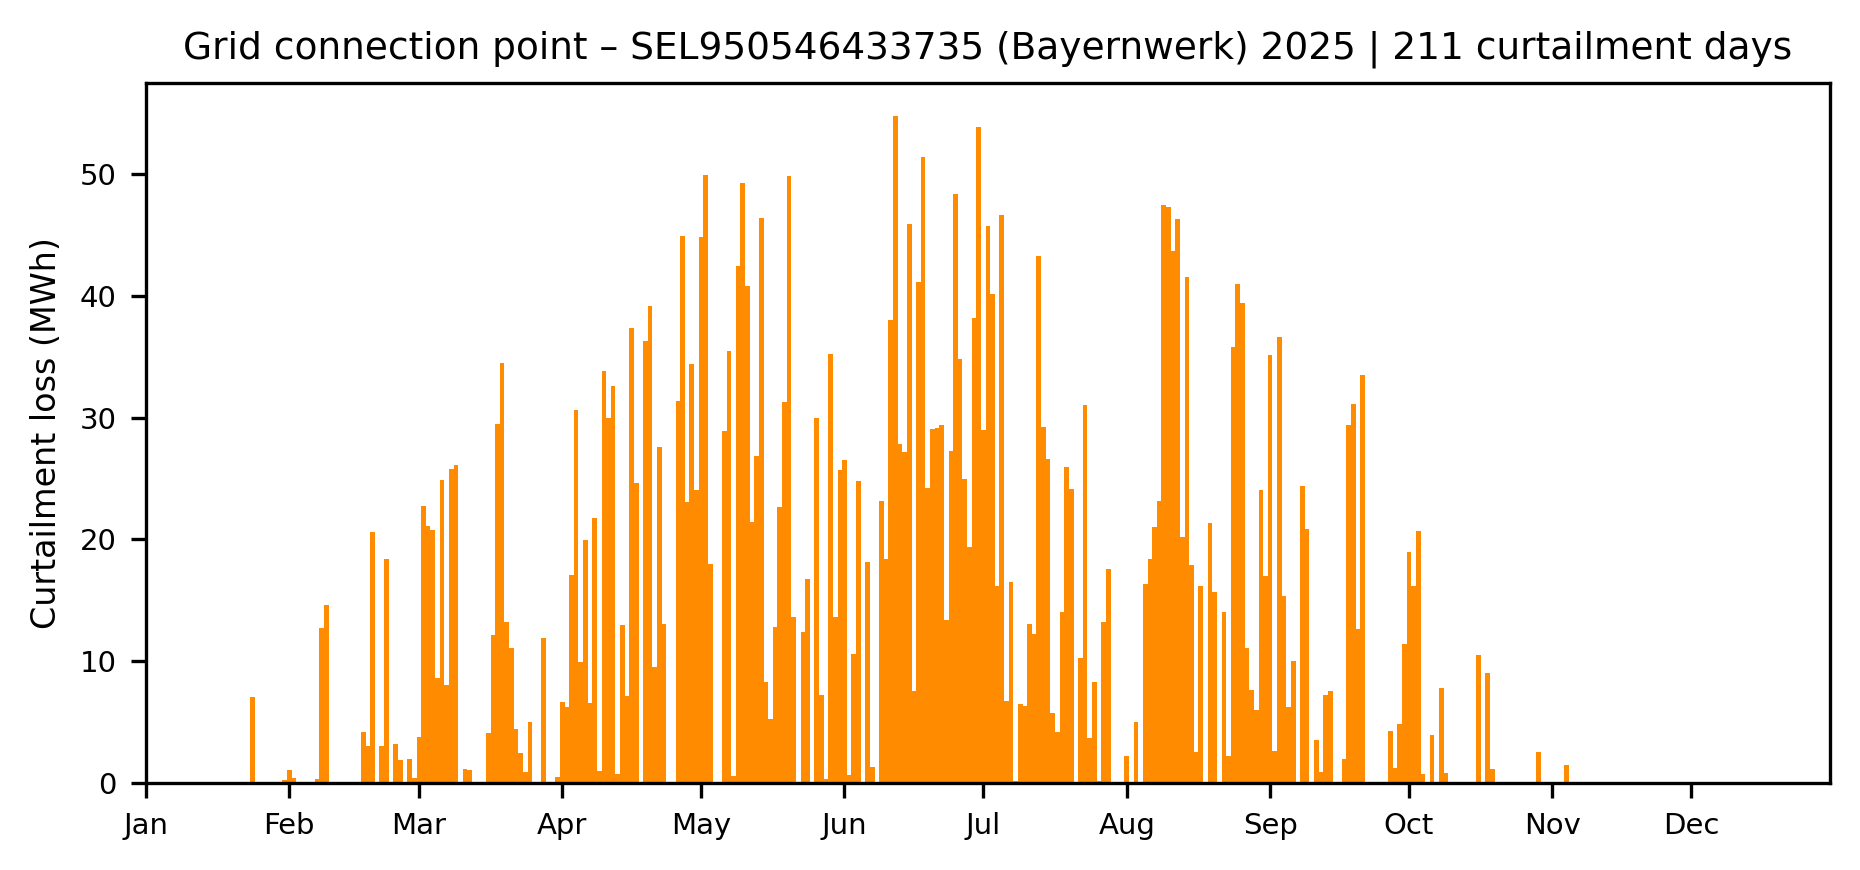

C:\Users\user\AppData\Local\Temp\ipykernel_3416\4003592409.py:49: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


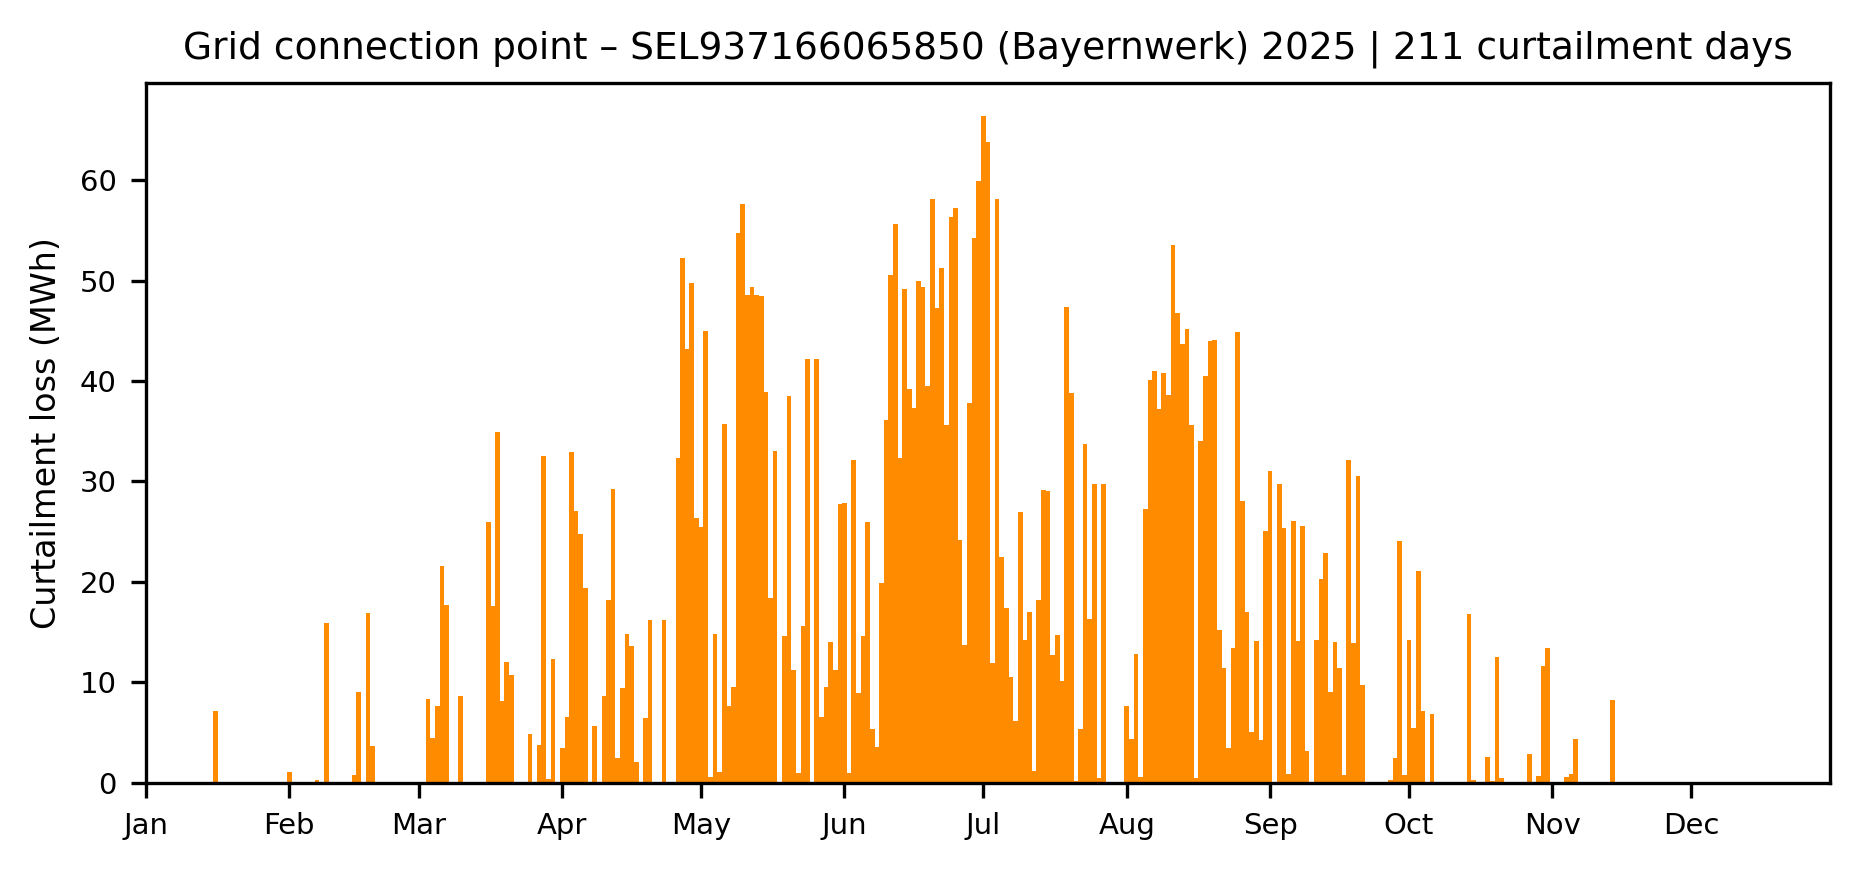

C:\Users\user\AppData\Local\Temp\ipykernel_3416\4003592409.py:49: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


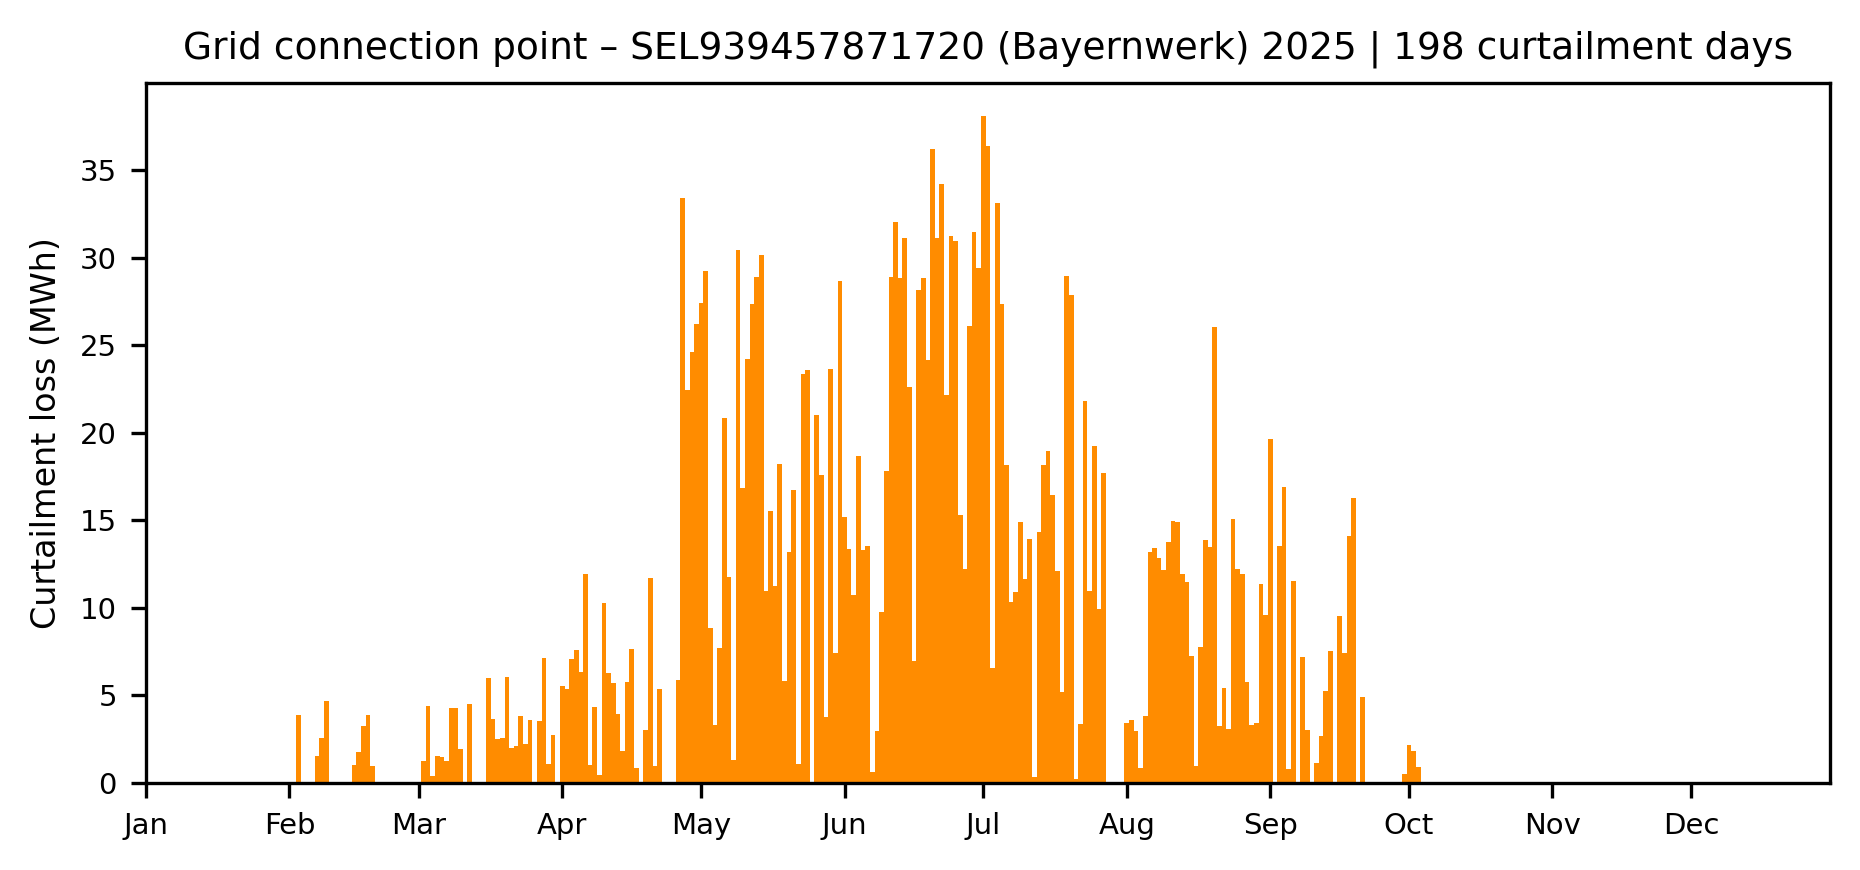

C:\Users\user\AppData\Local\Temp\ipykernel_3416\4003592409.py:49: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


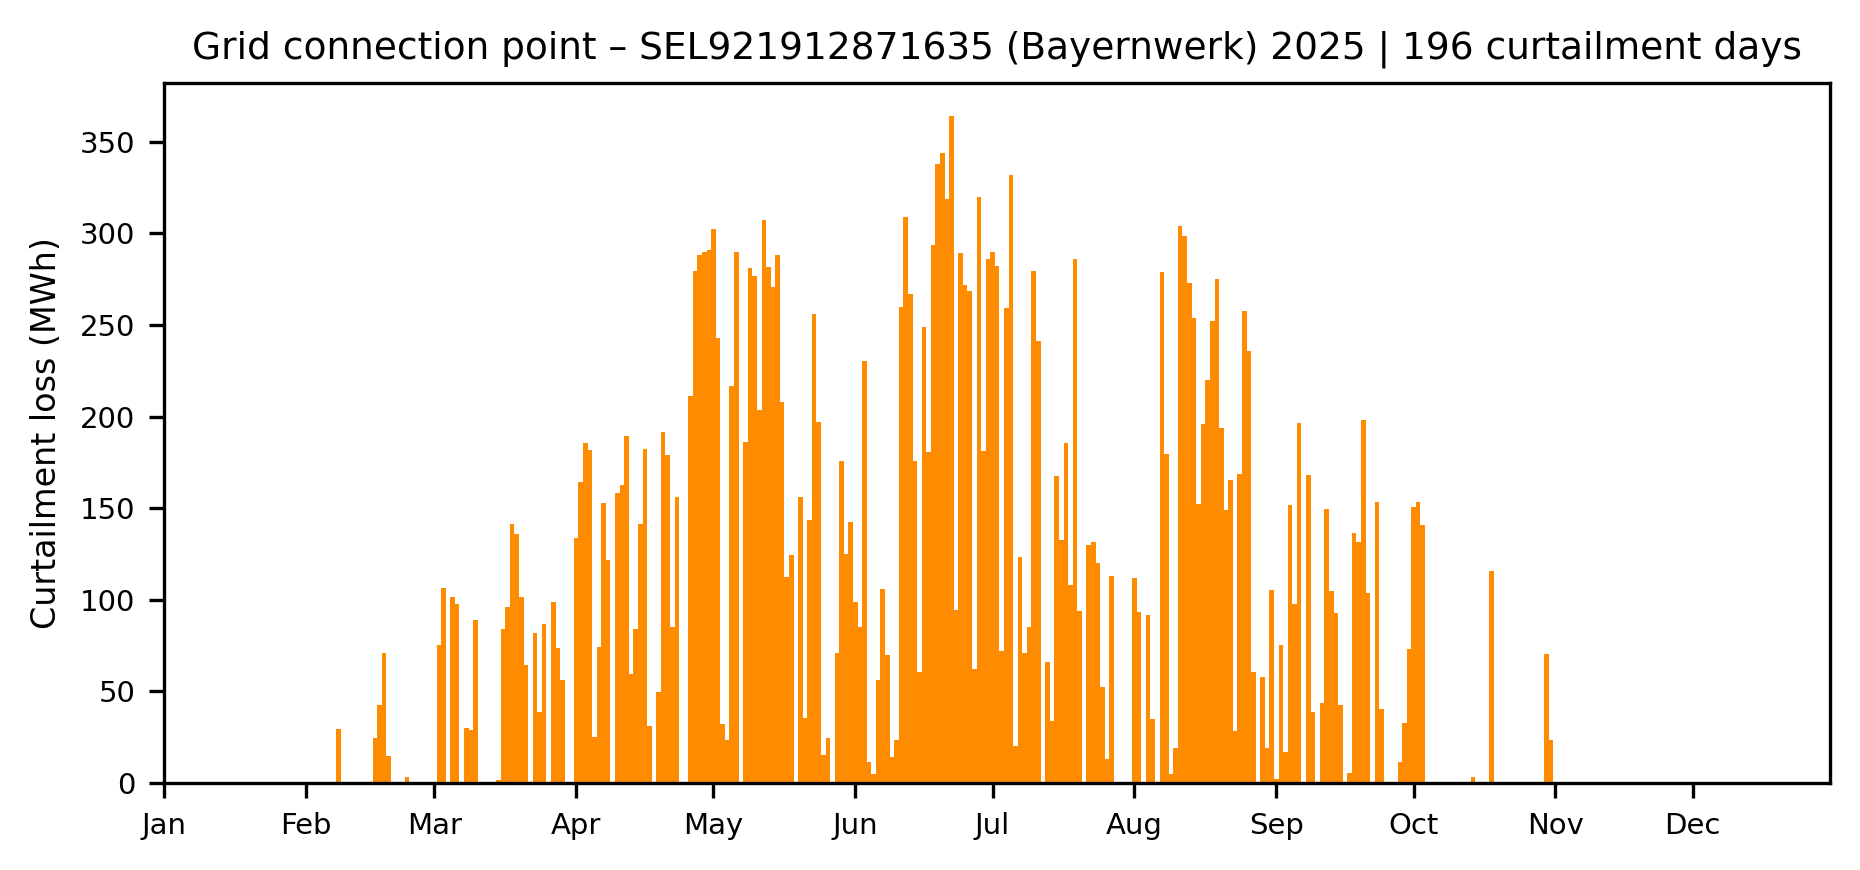

C:\Users\user\AppData\Local\Temp\ipykernel_3416\4003592409.py:49: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


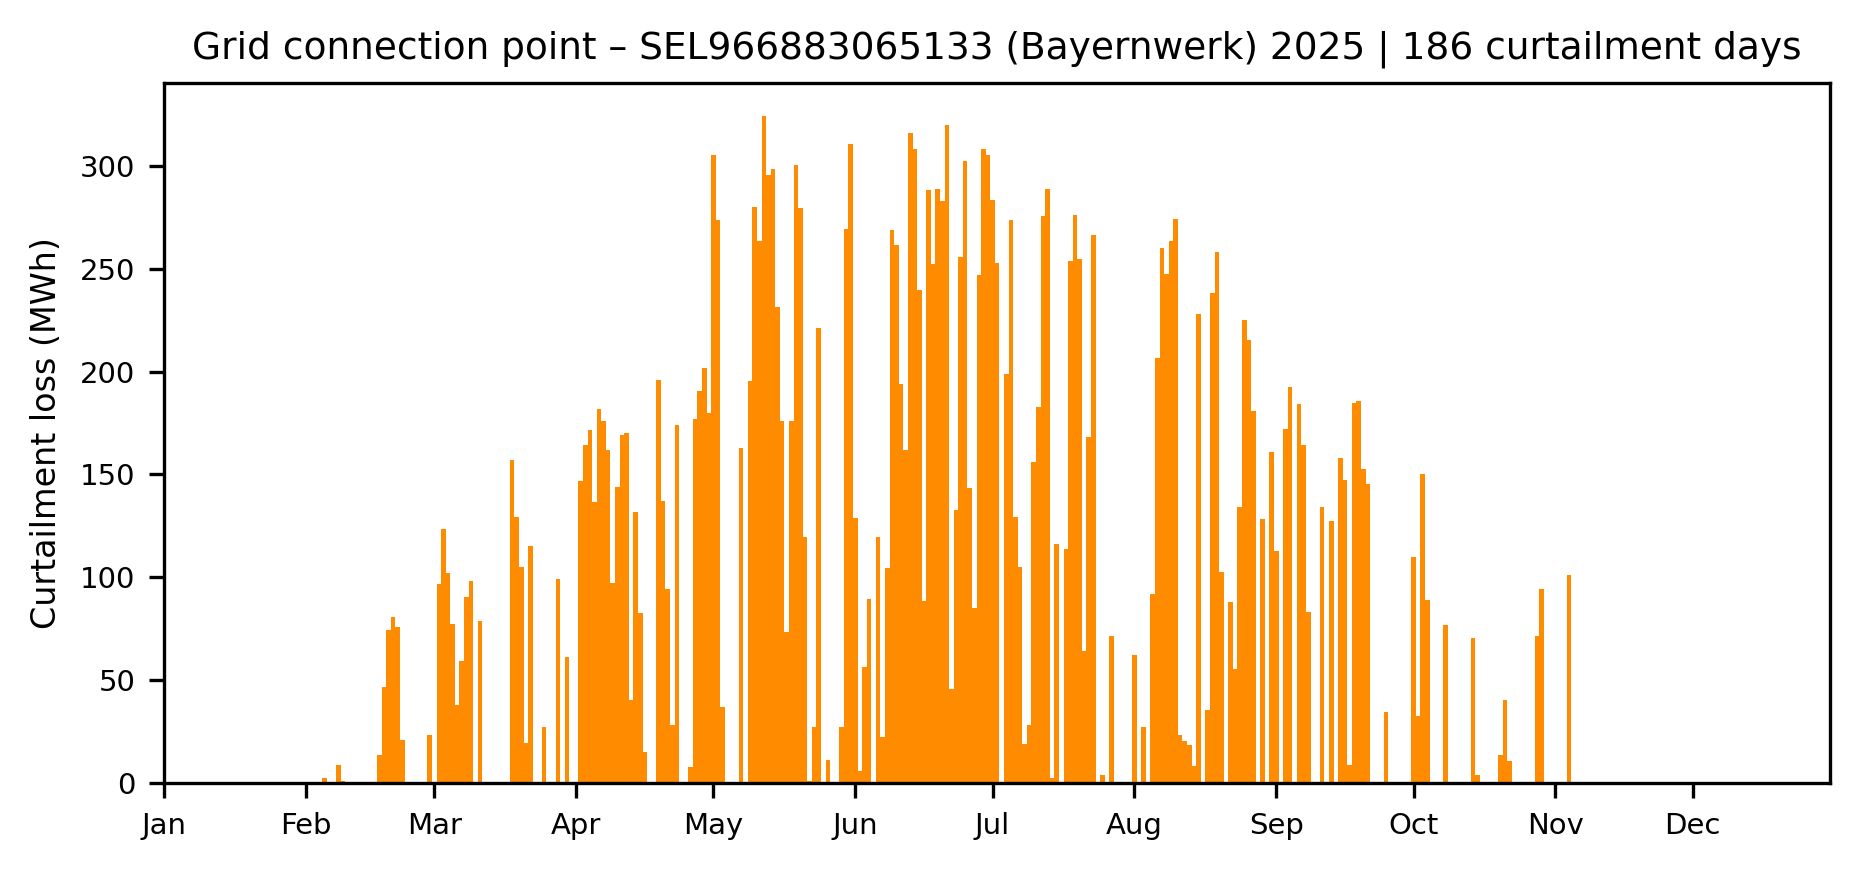

C:\Users\user\AppData\Local\Temp\ipykernel_3416\4003592409.py:49: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


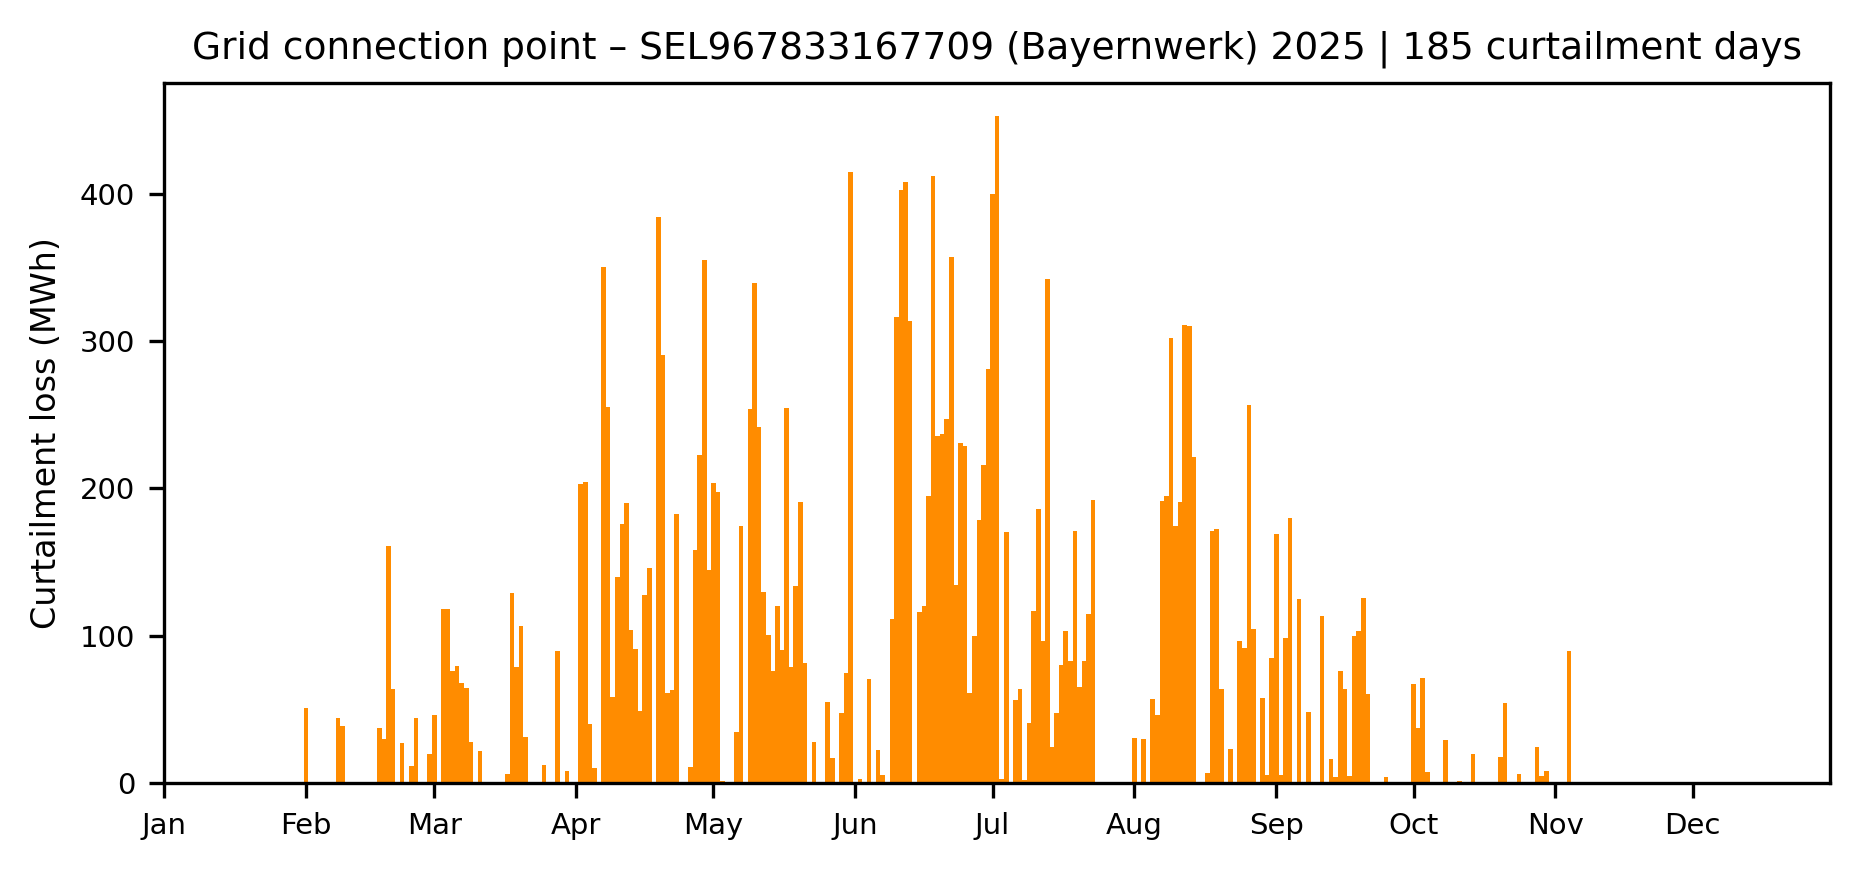

C:\Users\user\AppData\Local\Temp\ipykernel_3416\4003592409.py:49: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


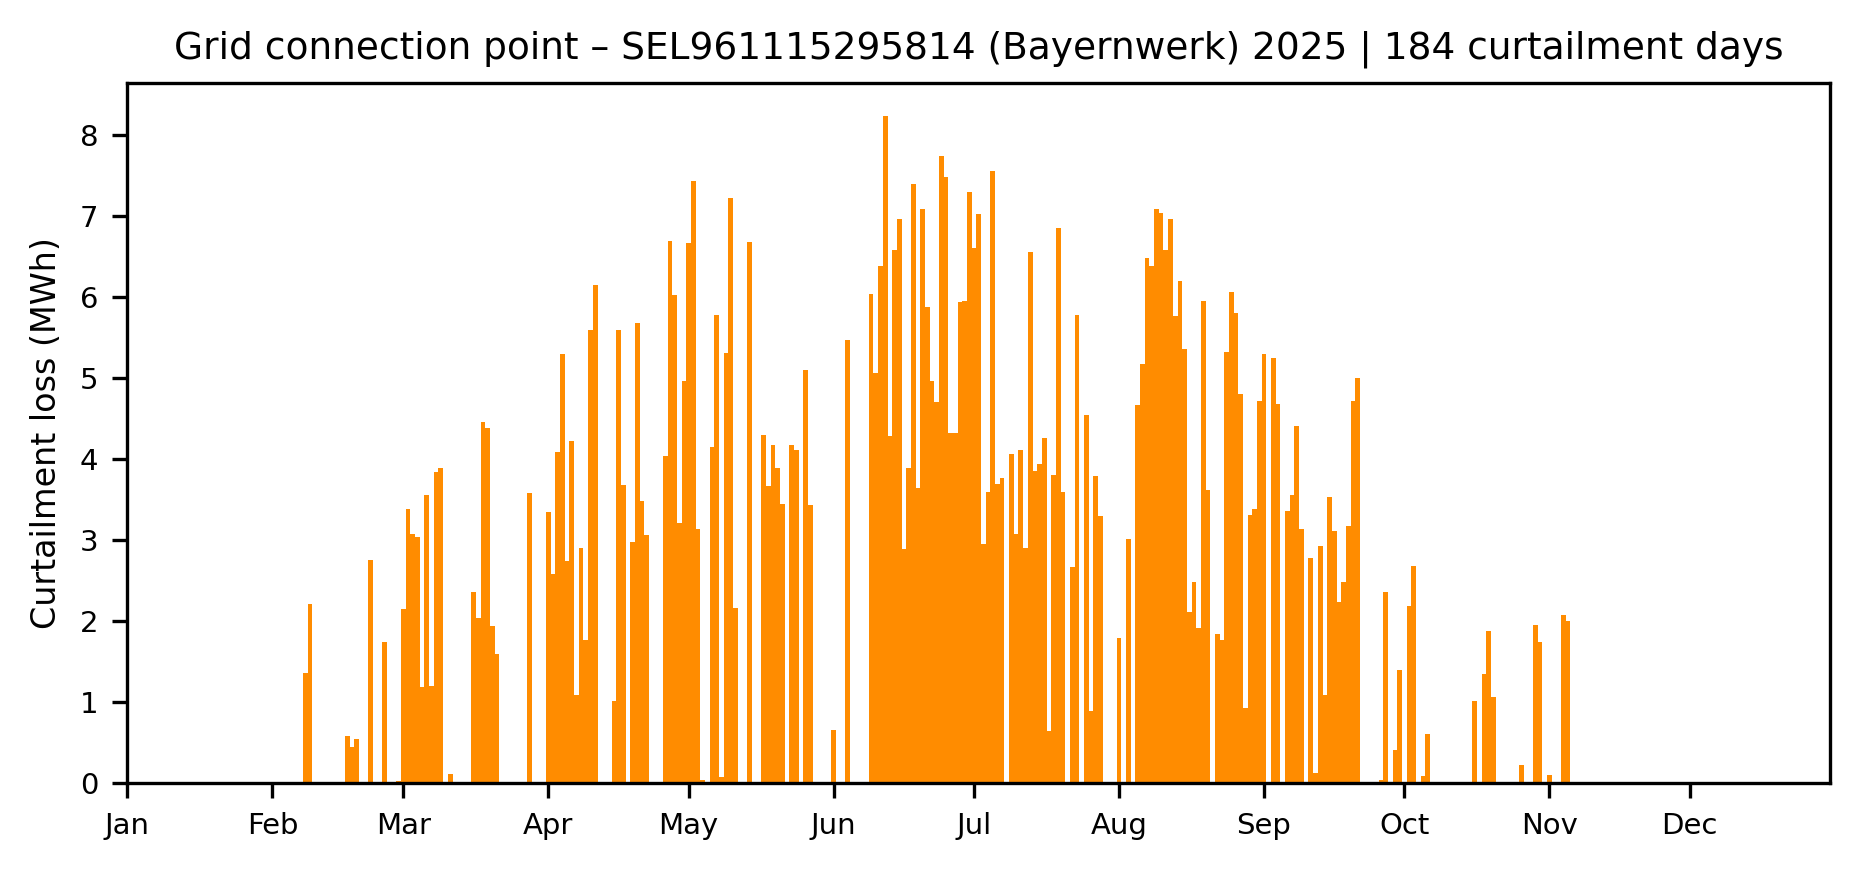

In [6]:
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

query_top_days = """
    SELECT
        netzanschluss,
        COUNT(DISTINCT DATE(star)) AS anzahl_tage,
        SUM(verlust) AS verlust_kwh_gesamt
    FROM redispatch.redispatch_eeg_bayernwerk
    WHERE verlust > 0
      AND netzanschluss IS NOT NULL
    GROUP BY netzanschluss
    ORDER BY anzahl_tage DESC
    LIMIT 10
"""
df_top_days = pd.read_sql(query_top_days, conn)

werte_top, einheit_top = scale_energy(df_top_days["verlust_kwh_gesamt"])
display(
    pd.DataFrame({
        "grid connection": df_top_days["netzanschluss"],
        "curtailment days": df_top_days["anzahl_tage"],
        f"total loss ({einheit_top})": werte_top.round(2),
    })
)

netzanschluesse_days = df_top_days["netzanschluss"].tolist()

start = datetime(2025, 1, 1)
end = datetime(2025, 12, 31)

for netzanschluss in netzanschluesse_days:
    query = """
        SELECT 
            DATE(star) AS tag,
            SUM(verlust) AS verlust_kwh
        FROM redispatch.redispatch_eeg_bayernwerk
        WHERE netzanschluss = %s
          AND verlust > 0
        GROUP BY DATE(star)
        ORDER BY DATE(star)
    """
    df_daily = pd.read_sql(query, conn, params=(netzanschluss,))

    if df_daily.empty:
        print(f"No data for {netzanschluss}")
        continue

    df_daily["tag"] = pd.to_datetime(df_daily["tag"])
    df_daily = df_daily.set_index("tag")
    idx = pd.date_range(start, end, freq="D")
    df_daily = df_daily.reindex(idx, fill_value=0)
    df_daily = df_daily.reset_index().rename(columns={"index": "tag"})

    tage = df_top_days.loc[df_top_days["netzanschluss"] == netzanschluss, "anzahl_tage"].values[0]
    werte, einheit = scale_energy(df_daily["verlust_kwh"])

    fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI)
    ax.bar(df_daily["tag"], werte, width=1, color="darkorange")
    ax.set_ylabel(f"Curtailment loss ({einheit})", fontsize=FS_LABEL)
    ax.set_title(f"Grid connection point – {netzanschluss} (Bayernwerk) 2025 "
                 f"| {tage} curtailment days", fontsize=FS_TITLE)
    ax.set_xlim([start, end])
    ax.tick_params(axis="both", labelsize=FS_TICK)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.margins(x=0)
    plt.tight_layout()
    plt.show()

conn.close()


## Top grid connection point (most days) – 10-minute resolution

C:\Users\user\AppData\Local\Temp\ipykernel_40056\2586042981.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_top1 = pd.read_sql(query_top1, conn)


Top-Netzanschluss: SEL937166065850 (338 Tage)


C:\Users\user\AppData\Local\Temp\ipykernel_40056\2586042981.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_10min = pd.read_sql(query_10min, conn, params=(top_netzanschluss, top_netzanschluss))


Gesamtverlust: 4,539,205.44 kWh (4,539.21 MWh)
Gespeichert: C:\Users\user\Projects\Documents\Desktop\MA - BESS\Code\MA\07_analysis\top_netzanschluss_10min.png


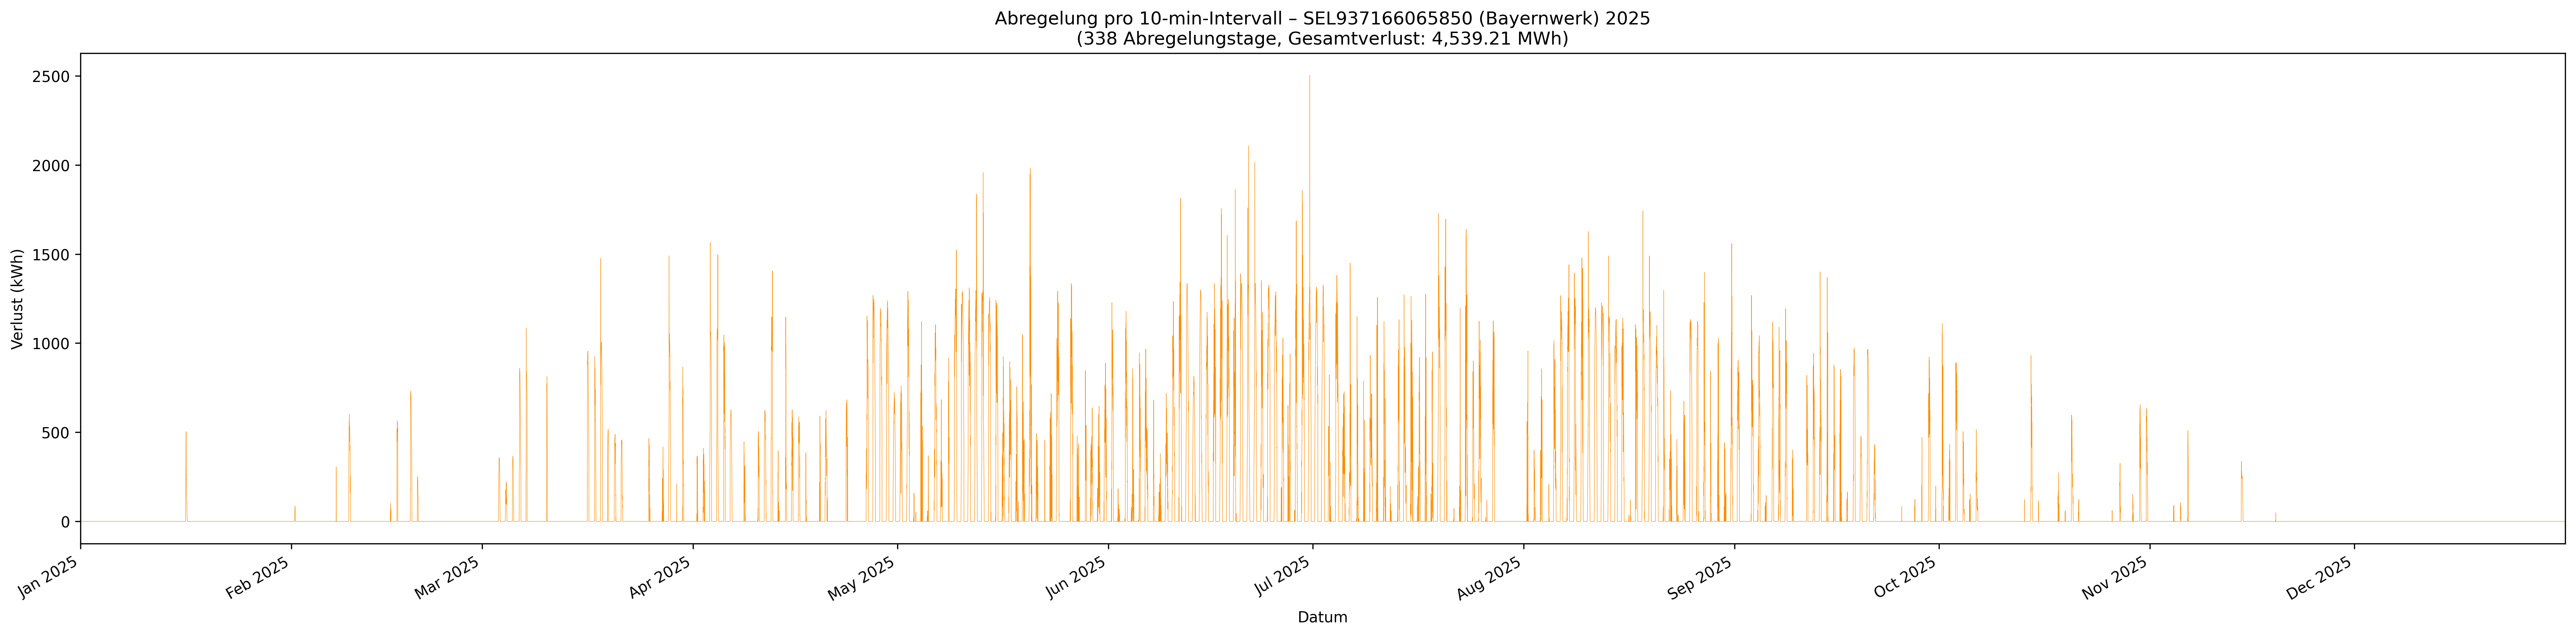

In [ ]:
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

# Grid connection point with the highest number of curtailment days
query_top1 = """
    SELECT
        netzanschluss,
        COUNT(DISTINCT DATE(star)) AS anzahl_tage
    FROM redispatch.redispatch_eeg_bayernwerk
    WHERE verlust IS NOT NULL
      AND netzanschluss IS NOT NULL
    GROUP BY netzanschluss
    ORDER BY anzahl_tage DESC
    LIMIT 1
"""
df_top1 = pd.read_sql(query_top1, conn)
top_netzanschluss = df_top1["netzanschluss"].iloc[0]
top_tage = df_top1["anzahl_tage"].iloc[0]
print(f"Top grid connection: {top_netzanschluss} ({top_tage} days)")

# 10-minute data joined via eventnummer from the interpolated tables
query_10min = """
    SELECT i.timestamp, i.verlust AS verlust_kwh
    FROM dwd.wind_bayernwerk_2025_interpolated i
    JOIN redispatch.redispatch_eeg_bayernwerk r
      ON r.eventnummer = i.eventnummer
    WHERE r.netzanschluss = %s
      AND i.verlust IS NOT NULL

    UNION ALL

    SELECT i.timestamp, i.verlust AS verlust_kwh
    FROM dwd.solar_bayernwerk_2025_interpolated i
    JOIN redispatch.redispatch_eeg_bayernwerk r
      ON r.eventnummer = i.eventnummer
    WHERE r.netzanschluss = %s
      AND i.verlust IS NOT NULL

    ORDER BY timestamp
"""
df_10min = pd.read_sql(query_10min, conn, params=(top_netzanschluss, top_netzanschluss))
conn.close()

df_10min["timestamp"] = pd.to_datetime(df_10min["timestamp"])

# Sum wind and solar where timestamps coincide
df_10min = df_10min.groupby("timestamp", as_index=False)["verlust_kwh"].sum()

verlust_gesamt_kwh = df_10min["verlust_kwh"].sum()
gesamt_wert, gesamt_einheit = scale_energy(pd.Series([verlust_gesamt_kwh]))
print(f"Total curtailment loss: {gesamt_wert.iloc[0]:,.2f} {gesamt_einheit}")

# Build the full 10-minute index for the year and fill gaps with zero
start = datetime(2025, 1, 1)
end = datetime(2025, 12, 31, 23, 50)
idx = pd.date_range(start, end, freq="10min")
df_10min = df_10min.set_index("timestamp").reindex(idx, fill_value=0).reset_index()
df_10min.columns = ["timestamp", "verlust_kwh"]

werte, einheit = scale_energy(df_10min["verlust_kwh"])

fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI)
ax.plot(df_10min["timestamp"], werte, linewidth=0.3, color="darkorange")
ax.set_ylabel(f"Curtailment loss per 10 min ({einheit})", fontsize=FS_LABEL)
ax.set_title(f"Curtailment per 10-minute interval – {top_netzanschluss} (Bayernwerk) 2025\n"
             f"{top_tage} curtailment days, total {gesamt_wert.iloc[0]:,.2f} {gesamt_einheit}",
             fontsize=FS_TITLE)
ax.set_xlim([start, end])
ax.tick_params(axis="both", labelsize=FS_TICK)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.margins(x=0)
plt.tight_layout()

output_path = r"C:\Users\user\Projects\Documents\Desktop\MA - BESS\Code\MA\07_analysis\top_netzanschluss_10min.png"
fig.savefig(output_path, dpi=DPI, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()


In [ ]:
# Cross-check of day counts: interpolated tables vs. redispatch table
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

query_check = """
    SELECT
        MIN(star)                                   AS first_event,
        MAX(star)                                   AS last_event,
        COUNT(DISTINCT DATE(star))                  AS days_total,
        COUNT(DISTINCT DATE(star)) FILTER (
            WHERE star >= '2025-01-01' AND star < '2026-01-01'
        )                                           AS days_2025,
        COUNT(DISTINCT DATE(star)) FILTER (
            WHERE verlust > 0
        )                                           AS days_with_loss
    FROM redispatch.redispatch_eeg_bayernwerk
    WHERE verlust IS NOT NULL
"""
display(pd.read_sql(query_check, conn))
conn.close()

print(f"Days from interpolated tables (loss > 0): {(df_daily_all['verlust_kwh'] > 0).sum()}")
print(f"Period covered by interpolated tables: {df_daily_all['tag'].min()} to {df_daily_all['tag'].max()}")


C:\Users\user\AppData\Local\Temp\ipykernel_20520\992773926.py:25: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  display(pd.read_sql(query_check, conn))


,min_star,max_star,tage_gesamt,tage_2025,tage_verlust_groesser_null
0,2025-01-01 08:01:02,2025-12-18 07:04:51,344,344,294


Tage aus interpolierten Tabellen (verlust > 0): 294
Zeitraum interpolierte Tabellen: 2025-01-01 bis 2025-12-18


## Substations: curtailment over the year (wind + solar)

Selection of the substations with the largest and most regular curtailment volume
and a raster plot of hour of day × year of the curtailed power.

In [7]:
# Combined 10-minute curtailment time series (solar + wind) per substation
import numpy as np

DSO = "bayernwerk"
TAB_SOLAR = f"dwd.solar_{DSO}_2025_interpolated"
TAB_WIND = f"dwd.wind_{DSO}_2025_interpolated"
TAB_RD = f"redispatch.redispatch_eeg_{DSO}"

conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)


def vorhandene_spalten(conn, tabelle):
    schema, name = tabelle.split(".")
    return set(pd.read_sql(f"""
        SELECT column_name
        FROM information_schema.columns
        WHERE table_schema = '{schema}' AND table_name = '{name}'
    """, conn)["column_name"])


def verlust_ausdruck(spalten, alias):
    """Loss term depending on the columns available in the interpolated table."""
    if "verlust" in spalten:
        return f"GREATEST(COALESCE({alias}.verlust, 0), 0)"
    if {"energy_kwh_10min", "abregelung"} <= spalten:
        return (f"GREATEST(COALESCE({alias}.energy_kwh_10min, 0) "
                f"- COALESCE({alias}.abregelung, 0), 0)")
    return None


# Inner aggregation per asset: overlapping events would otherwise be counted twice.
term_solar = verlust_ausdruck(vorhandene_spalten(conn, TAB_SOLAR), "s")
if term_solar is None:
    raise RuntimeError(f"{TAB_SOLAR} has no loss columns "
                       f"- please run the energy calculation for {DSO}.")

df_10min_solar = pd.read_sql(f"""
    SELECT location, timestamp, SUM(verlust_kwh) AS solar
    FROM (
        SELECT r.location, s.timestamp, r.assetkey, MAX({term_solar}) AS verlust_kwh
        FROM {TAB_SOLAR} s
        JOIN {TAB_RD} r ON r.eventnummer = s.eventnummer
        WHERE r.location IS NOT NULL AND btrim(r.location) <> ''
        GROUP BY r.location, s.timestamp, r.assetkey
    ) t
    GROUP BY location, timestamp
""", conn)

term_wind = verlust_ausdruck(vorhandene_spalten(conn, TAB_WIND), "w")
if term_wind is not None:
    df_10min_wind = pd.read_sql(f"""
        SELECT location, timestamp, SUM(verlust_kwh) AS wind
        FROM (
            SELECT r.location, w.timestamp, r.assetkey, MAX({term_wind}) AS verlust_kwh
            FROM {TAB_WIND} w
            JOIN {TAB_RD} r ON r.eventnummer = w.eventnummer
            WHERE r.location IS NOT NULL AND btrim(r.location) <> ''
            GROUP BY r.location, w.timestamp, r.assetkey
        ) t
        GROUP BY location, timestamp
    """, conn)
    wind_quelle = TAB_WIND
else:
    # Fallback without interpolated wind losses: spread the event loss evenly over the slots
    df_10min_wind = pd.read_sql(f"""
        WITH ev AS (
            SELECT location, assetkey, star, ende,
                   GREATEST(COALESCE(verlust, 0), 0) AS verlust_kwh,
                   GREATEST(1, CEIL(EXTRACT(EPOCH FROM (ende - star)) / 600.0)) AS n_slots
            FROM {TAB_RD}
            WHERE location IS NOT NULL AND btrim(location) <> ''
              AND lower(left(energie, 4)) = 'wind'
              AND verlust IS NOT NULL
              AND ende > star
        )
        SELECT location, timestamp, SUM(verlust_kwh) AS wind
        FROM (
            SELECT ev.location,
                   date_bin('10 minutes', gs, TIMESTAMP '2000-01-01') AS timestamp,
                   ev.assetkey,
                   MAX(ev.verlust_kwh / ev.n_slots) AS verlust_kwh
            FROM ev
            CROSS JOIN LATERAL generate_series(ev.star, ev.ende - interval '1 second',
                                               interval '10 minutes') gs
            GROUP BY 1, 2, 3
        ) t
        GROUP BY location, timestamp
    """, conn)
    wind_quelle = f"{TAB_RD} (fallback)"
conn.close()

for df, spalte in ((df_10min_solar, "solar"), (df_10min_wind, "wind")):
    df["timestamp"] = pd.to_datetime(df["timestamp"]).dt.floor("10min")
    df[spalte] = df[spalte].astype(float)

df_10min = (
    df_10min_solar.groupby(["location", "timestamp"], as_index=False)["solar"].sum()
    .merge(df_10min_wind.groupby(["location", "timestamp"], as_index=False)["wind"].sum(),
           on=["location", "timestamp"], how="outer")
    .fillna({"solar": 0.0, "wind": 0.0})
)
df_10min["gesamt"] = df_10min["solar"] + df_10min["wind"]

summen, einheit_summe = scale_energy(pd.Series([df_10min["solar"].sum(), df_10min["wind"].sum()]))
print(f"Wind source:           {wind_quelle}")
print(f"Substations total:     {df_10min['location'].nunique()}")
print(f"10-minute data points: {len(df_10min):,}")
print(f"Curtailment solar:     {summen.iloc[0]:,.2f} {einheit_summe}")
print(f"Curtailment wind:      {summen.iloc[1]:,.2f} {einheit_summe}")


C:\Users\user\AppData\Local\Temp\ipykernel_6012\1710796494.py:21: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return set(pd.read_sql(f"""
C:\Users\user\AppData\Local\Temp\ipykernel_6012\1710796494.py:44: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_10min_solar = pd.read_sql(f"""
C:\Users\user\AppData\Local\Temp\ipykernel_6012\1710796494.py:72: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_10min_wind = pd.read_sql(f"""


Wind source:           redispatch.redispatch_eeg_bayernwerk (fallback)
Substations total:     1364
10-minute data points: 1,837,729
Curtailment solar:     764.98 GWh
Curtailment wind:      8.33 GWh


In [8]:
# Key figures per substation: energy, mix and rhythm of the curtailment
JAHR = 2025
SLOTS = 144                # 10-minute slots per day
DT = 1 / 6                 # time step in hours
TOP_N_UW = 30              # candidates (by total curtailment)
MIN_TAGE = 20
ENTLADEFENSTER_H = 4       # pause length that counts as a usable discharge window

IDX_JAHR = pd.date_range(f"{JAHR}-01-01", f"{JAHR}-12-31 23:50", freq="10min")


def zeitreihen(df, loc):
    """Power series (MW) over the full year, gaps filled with zero."""
    g = (df[df["location"] == loc]
         .groupby("timestamp")[["solar", "wind"]].sum()
         .reindex(IDX_JAHR, fill_value=0.0))
    return g["solar"].to_numpy() * 6 / 1e3, g["wind"].to_numpy() * 6 / 1e3


def laufabschnitte(maske):
    """Start and end indices of contiguous True ranges."""
    d = np.diff(np.concatenate(([0], maske.astype(np.int8), [0])))
    return np.flatnonzero(d == 1), np.flatnonzero(d == -1)


energie_je_loc = df_10min.groupby("location")["gesamt"].sum().sort_values(ascending=False)
uw_store = {}
zeilen = []

for loc in energie_je_loc.head(TOP_N_UW).index:
    p_solar, p_wind = zeitreihen(df_10min, loc)
    p_ges = p_solar + p_wind
    aktiv = p_ges > 0
    tage = len(np.unique(IDX_JAHR[aktiv].normalize()))
    if tage < MIN_TAGE:
        continue

    start, ende = laufabschnitte(aktiv)
    block_h = (ende - start) * DT
    pause_h = (start[1:] - ende[:-1]) * DT if len(start) > 1 else np.array([])

    uw_store[loc] = {"p_solar": p_solar, "p_wind": p_wind,
                     "block_h": block_h, "pause_h": pause_h}

    zeilen.append({
        "location": loc,
        "e_abregelung_gwh": float(p_ges.sum() * DT) / 1e3,
        "wind_anteil": float(p_wind.sum() / p_ges.sum()),
        "tage": tage,
        "lade_h": float(aktiv.sum() * DT),
        "p_max_mw": float(p_ges.max()),
        "p90_mw": float(np.percentile(p_ges[aktiv], 90)),
        "n_bloecke": len(start),
        "block_h_median": float(np.median(block_h)),
        "pause_h_median": float(np.median(pause_h)) if pause_h.size else np.nan,
        "pausen_ok": float((pause_h >= ENTLADEFENSTER_H).mean()) if pause_h.size else 0.0,
    })

df_uw = pd.DataFrame(zeilen)
df_uw["energie_norm"] = (np.log10(df_uw["e_abregelung_gwh"].clip(lower=0.01))
                         .pipe(lambda s: (s - s.min()) / (s.max() - s.min())))
df_uw["score"] = (0.4 * df_uw["energie_norm"]
                  + 0.3 * (df_uw["tage"] / 365)
                  + 0.3 * df_uw["pausen_ok"])
df_uw = df_uw.sort_values("score", ascending=False).reset_index(drop=True)

SPALTEN_EN = {
    "location": "substation",
    "score": "score",
    "e_abregelung_gwh": "curtailed energy (GWh)",
    "wind_anteil": "wind share (-)",
    "tage": "days with curtailment",
    "lade_h": "charging hours (h)",
    "p_max_mw": "peak power (MW)",
    "p90_mw": "P90 power (MW)",
    "n_bloecke": "curtailment blocks (-)",
    "block_h_median": "median block length (h)",
    "pause_h_median": "median pause length (h)",
    "pausen_ok": f"pauses >= {ENTLADEFENSTER_H} h (-)",
}

display(df_uw[list(SPALTEN_EN)].rename(columns=SPALTEN_EN).round(3))


,substation,score,curtailed energy (GWh),wind share (-),days with curtailment,charging hours (h),peak power (MW),P90 power (MW),curtailment blocks (-),median block length (h),median pause length (h),pauses >= 4 h (-)
0,Bundorf,0.801,42.896,0.000,199,1187.333,86.658,70.960,252,5.500,16.833,0.793
1,Straßkirchen,0.726,26.811,0.000,183,1117.000,51.858,41.720,209,5.833,17.500,0.875
2,Altomünster,0.608,13.991,0.000,173,1055.833,53.993,34.279,190,6.417,17.667,0.910
3,Straubing,0.607,16.773,0.000,125,724.833,46.288,38.398,135,5.667,18.000,0.925
4,Großbardorf,0.599,17.976,0.000,137,786.000,42.643,35.953,166,5.250,17.333,0.824
5,Gangkofen,0.595,15.095,0.000,149,964.333,53.398,38.852,168,6.333,17.000,0.886
6,Bogen,0.555,11.346,0.000,164,998.500,57.523,31.046,185,6.000,17.667,0.886
7,Berg im Gau,0.541,14.711,0.000,170,950.000,53.504,29.075,257,3.000,16.250,0.664
8,Moos,0.524,8.663,0.000,179,1092.833,38.562,22.234,197,6.000,17.583,0.908
9,Schierling,0.523,13.023,0.000,178,1076.833,30.673,22.928,271,3.500,16.167,0.656


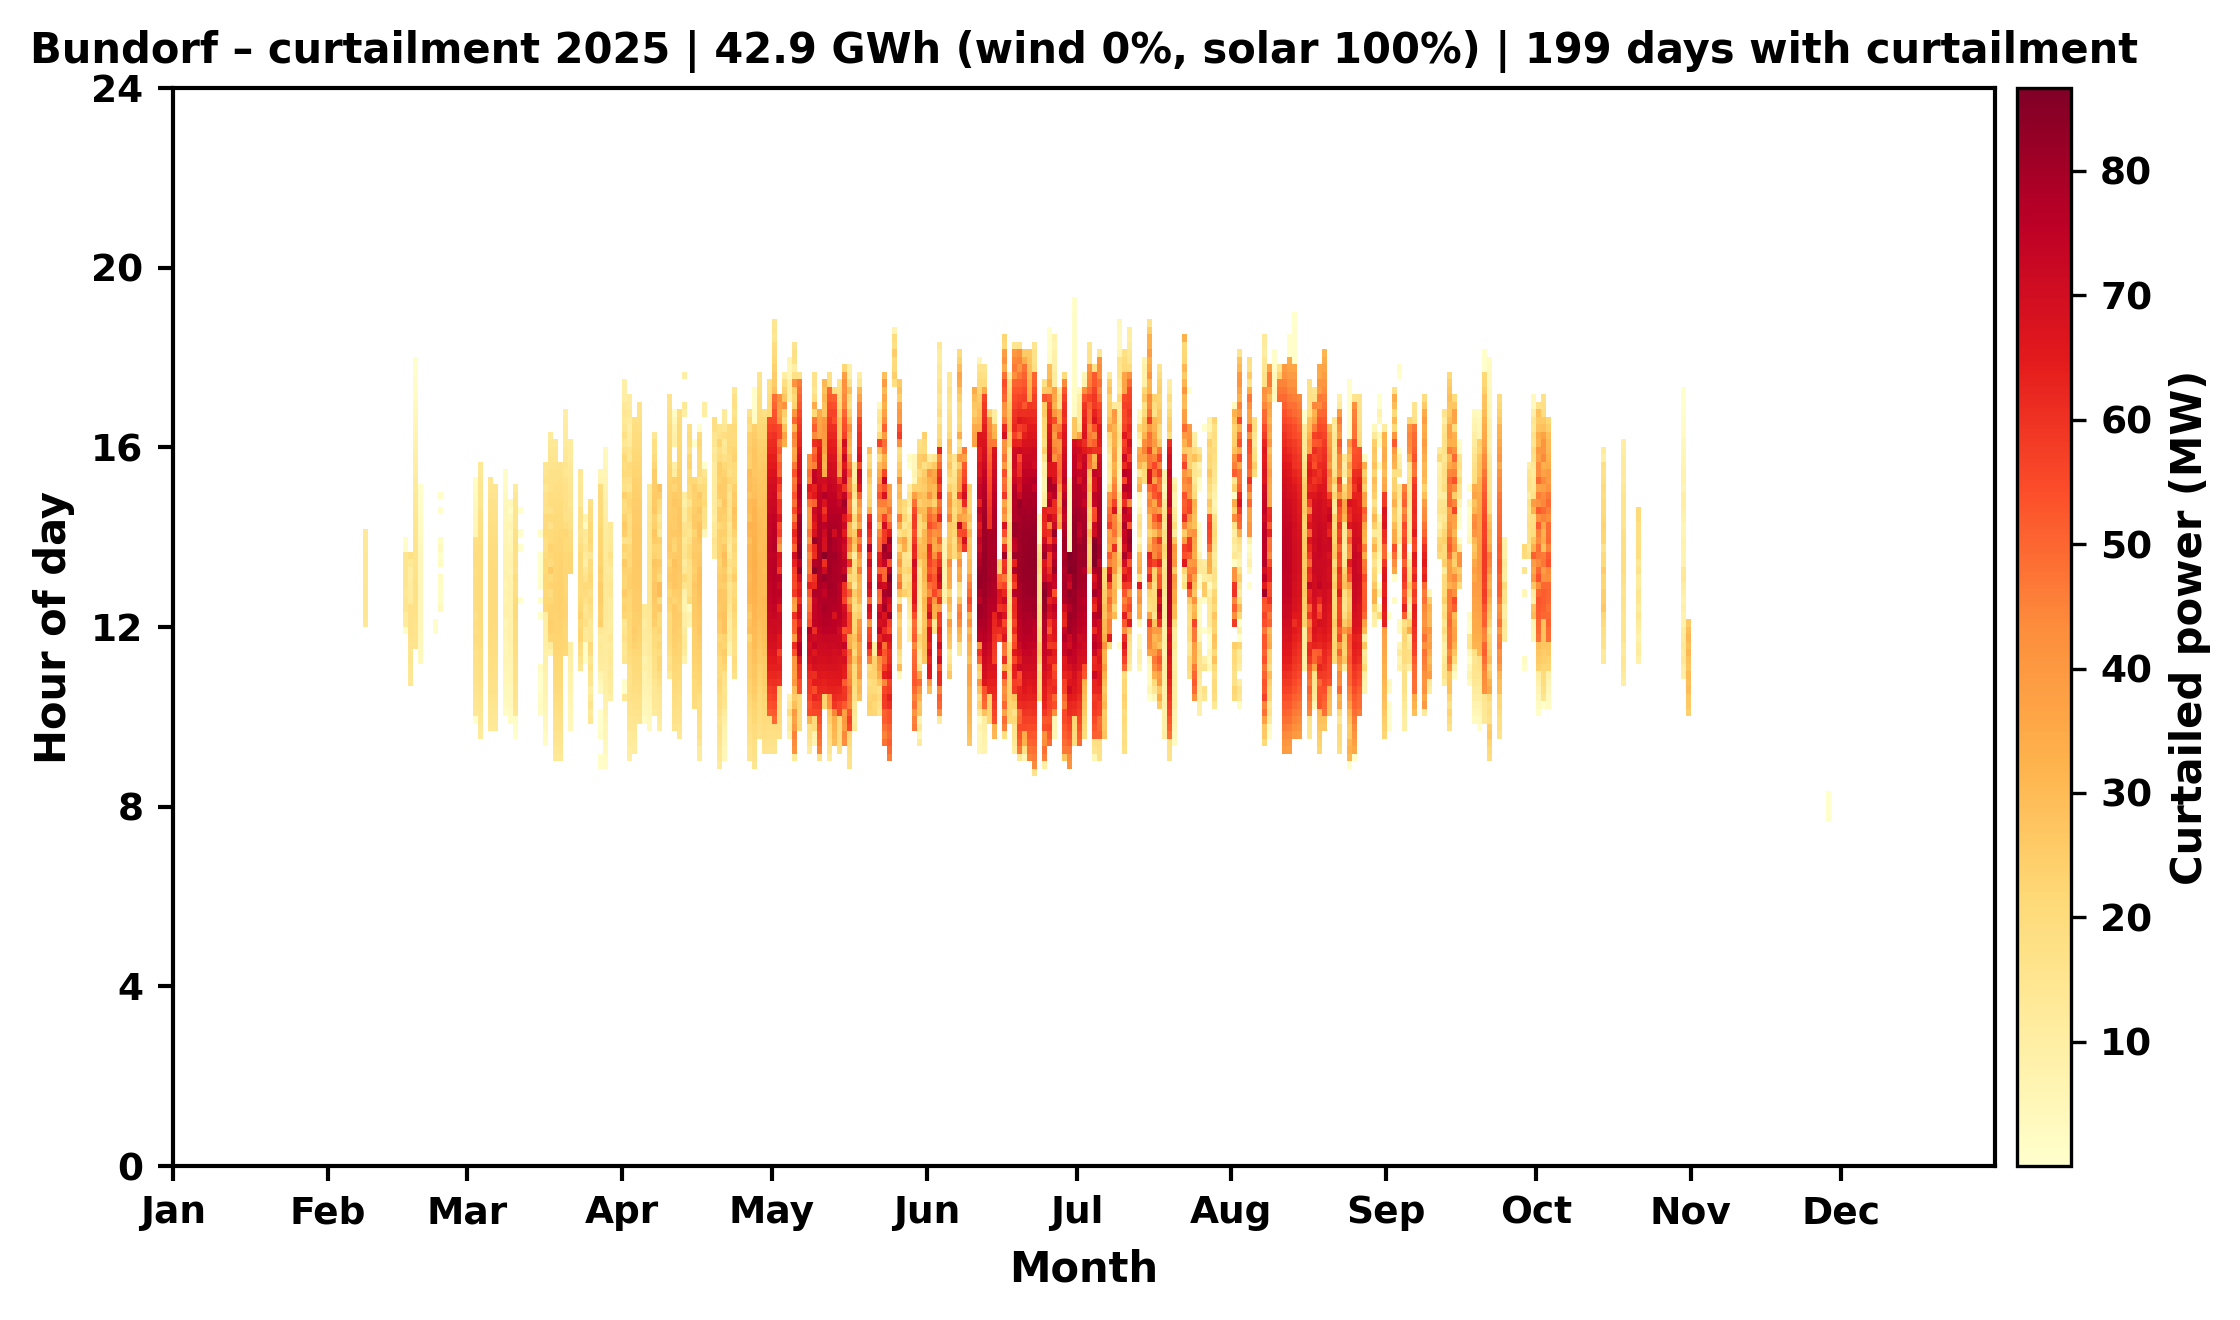

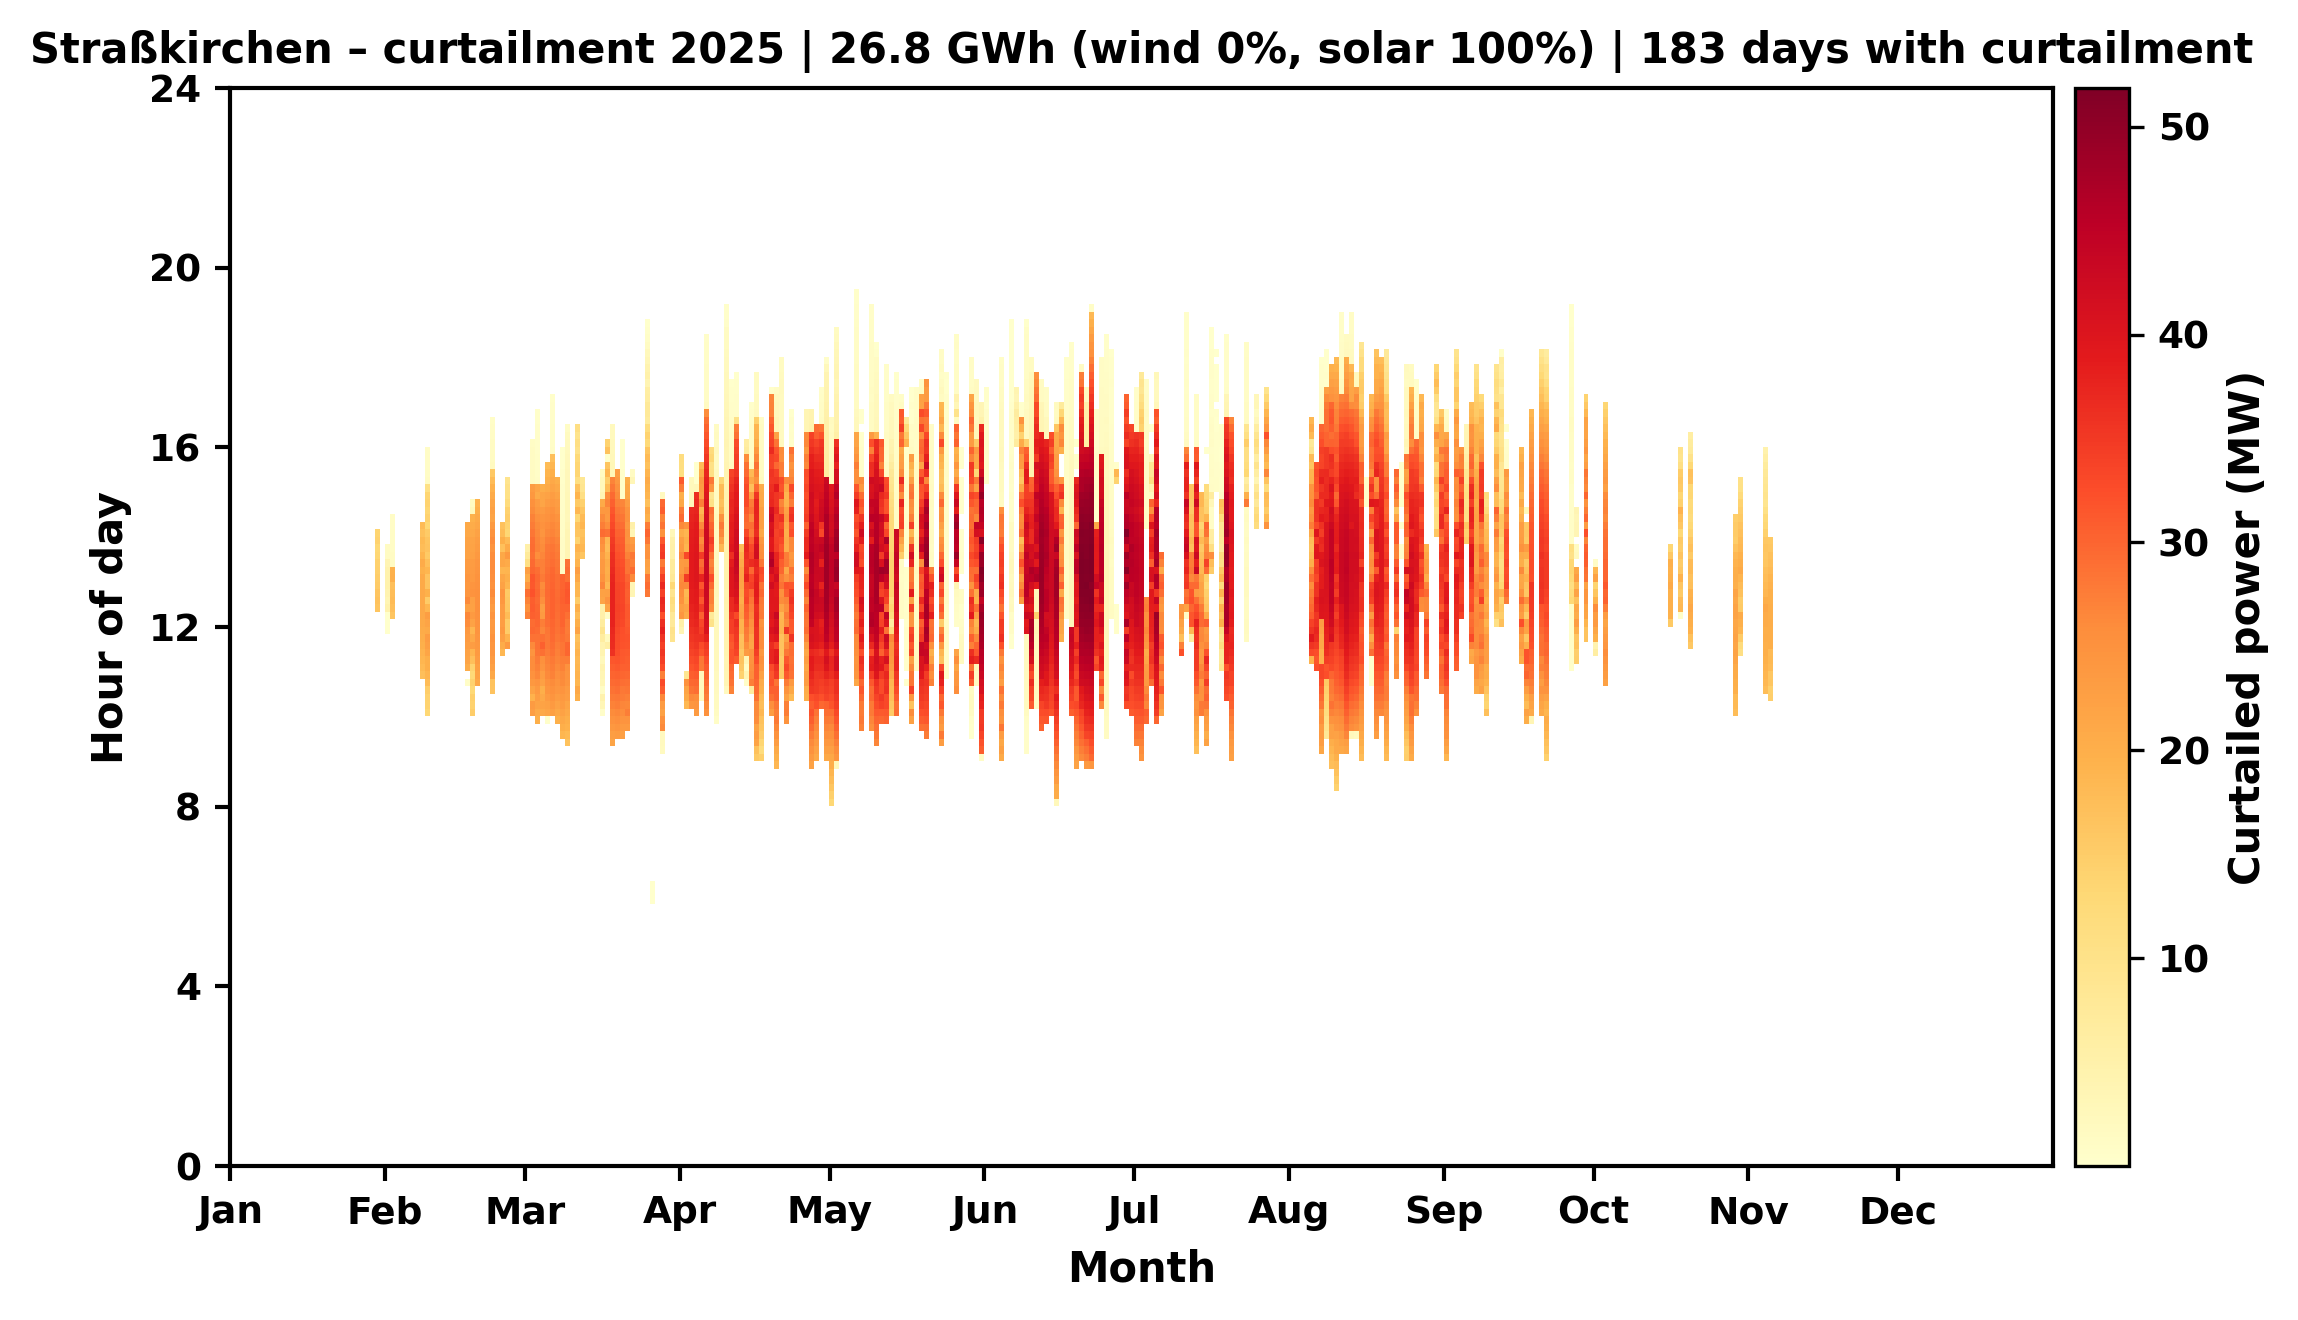

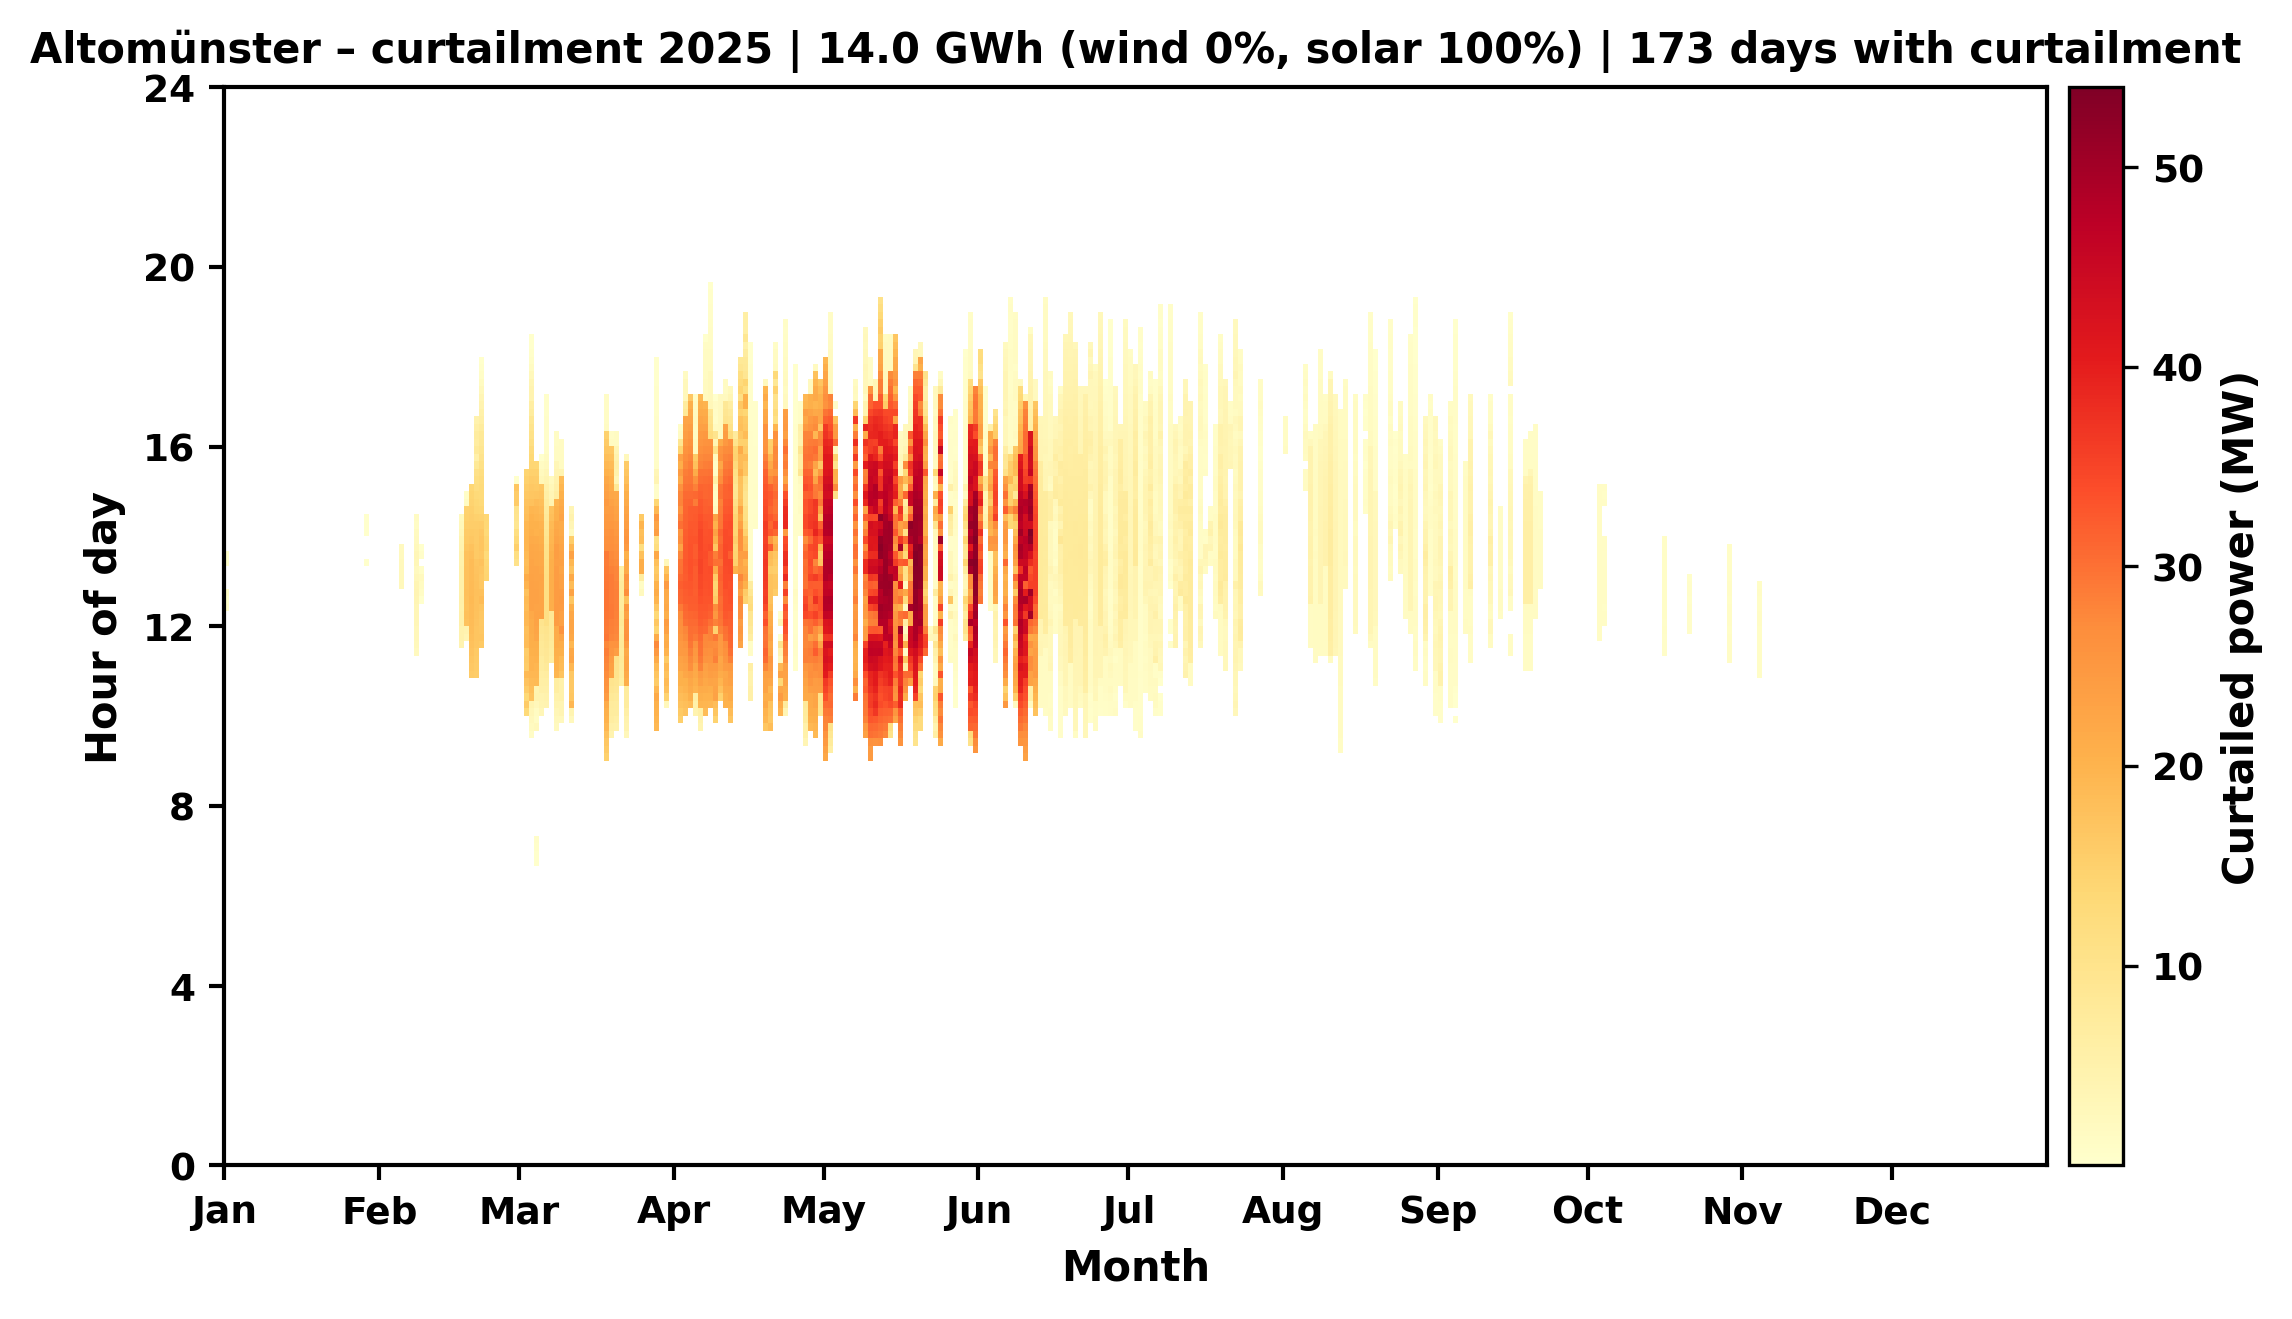

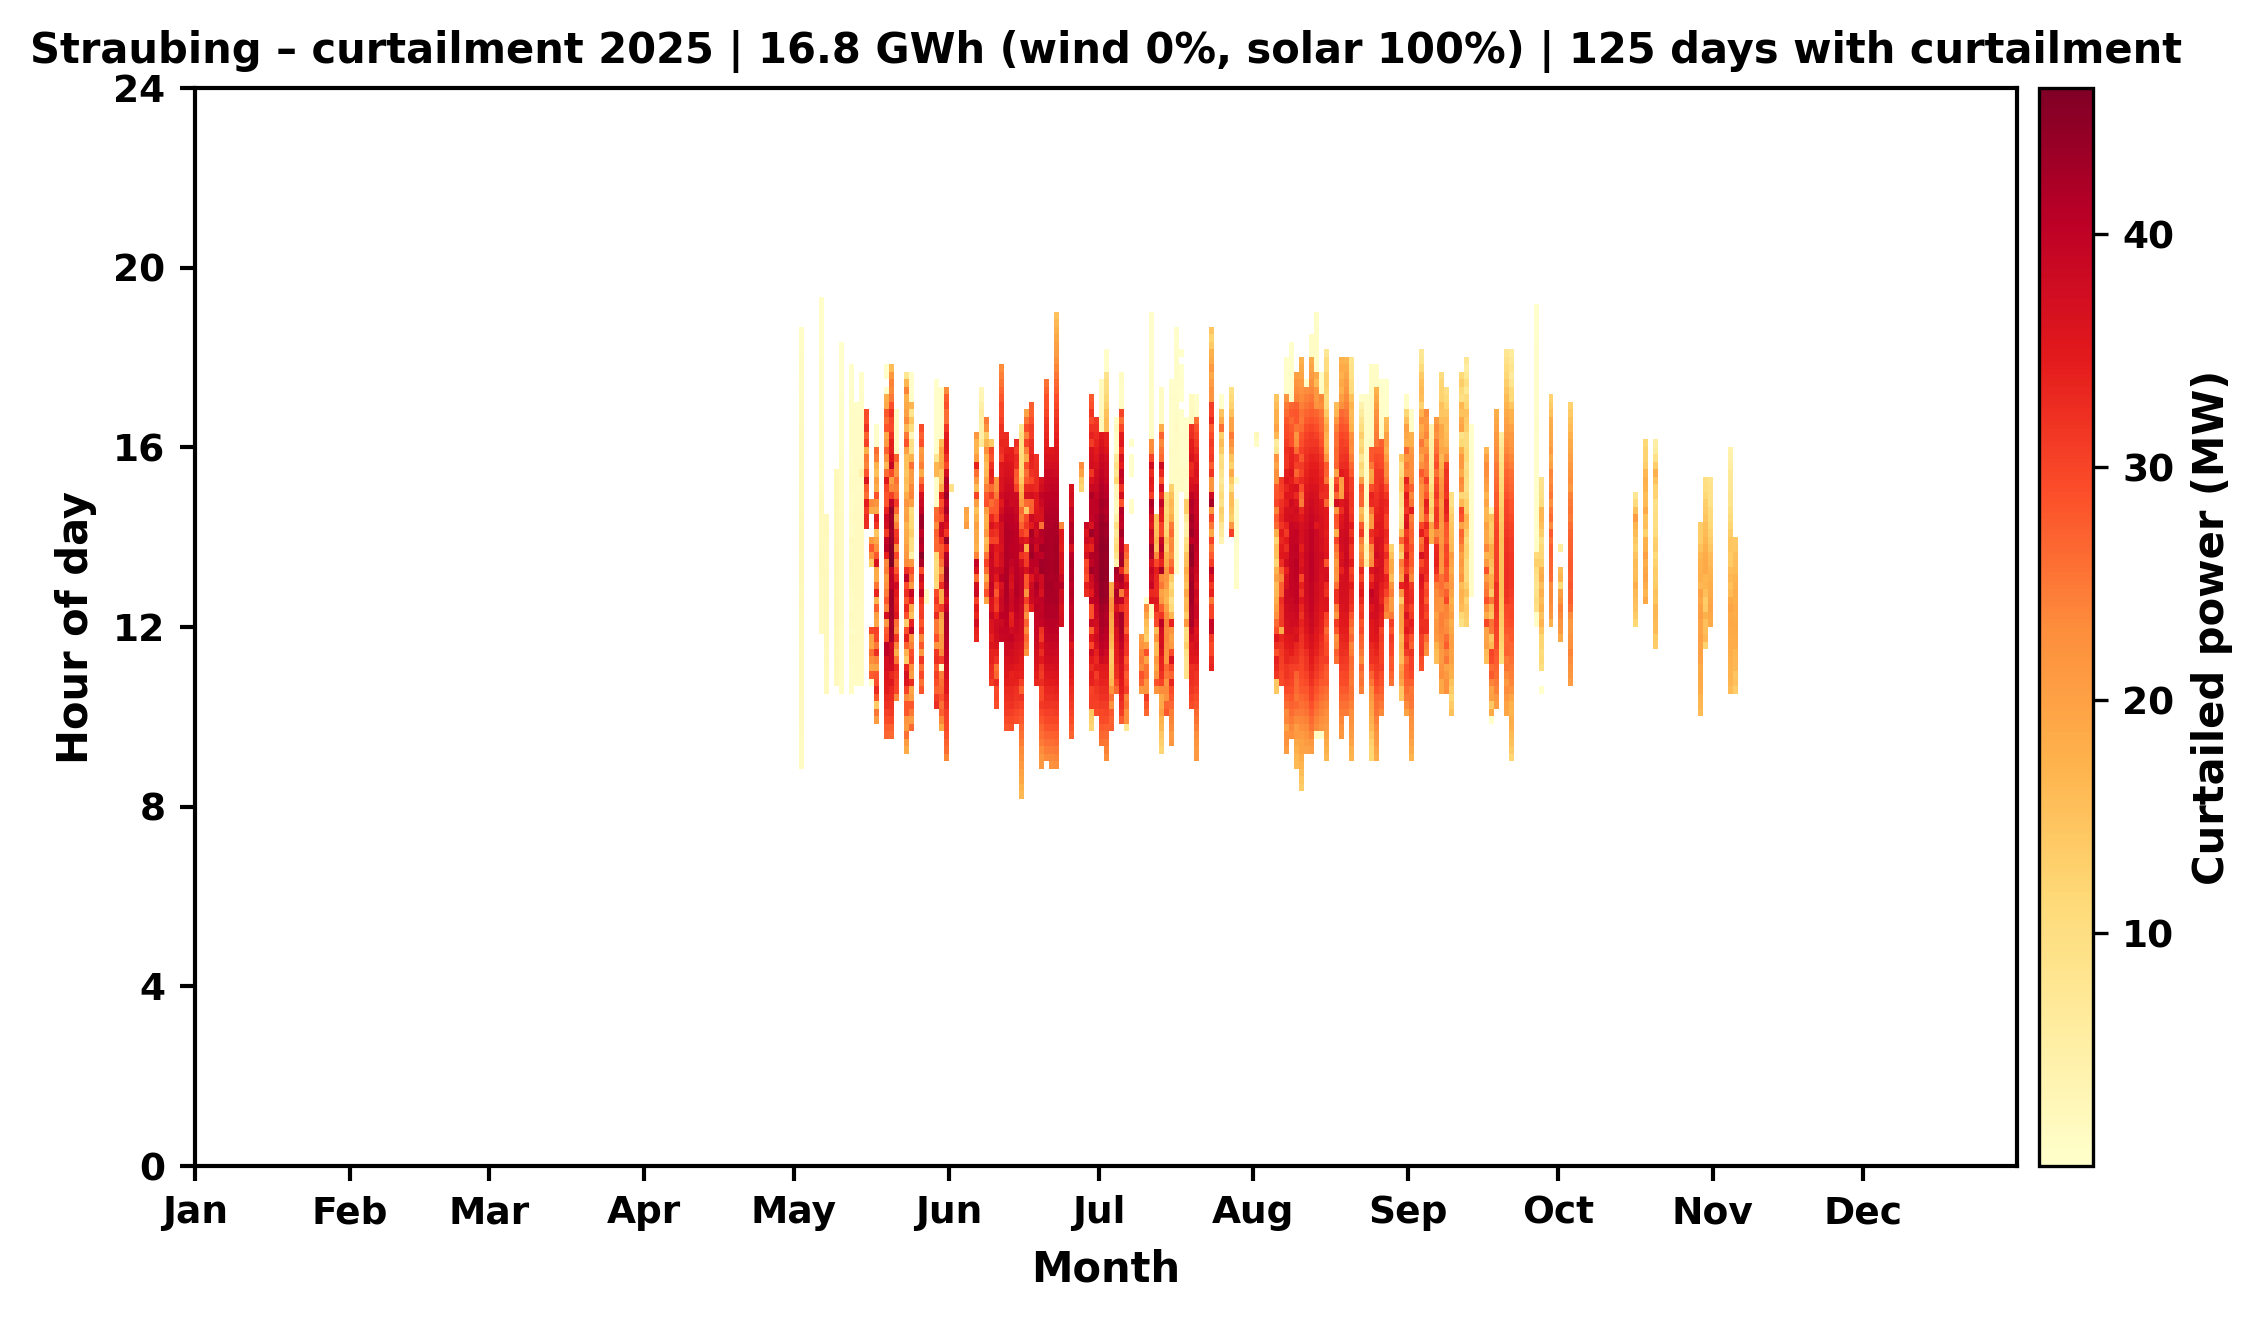

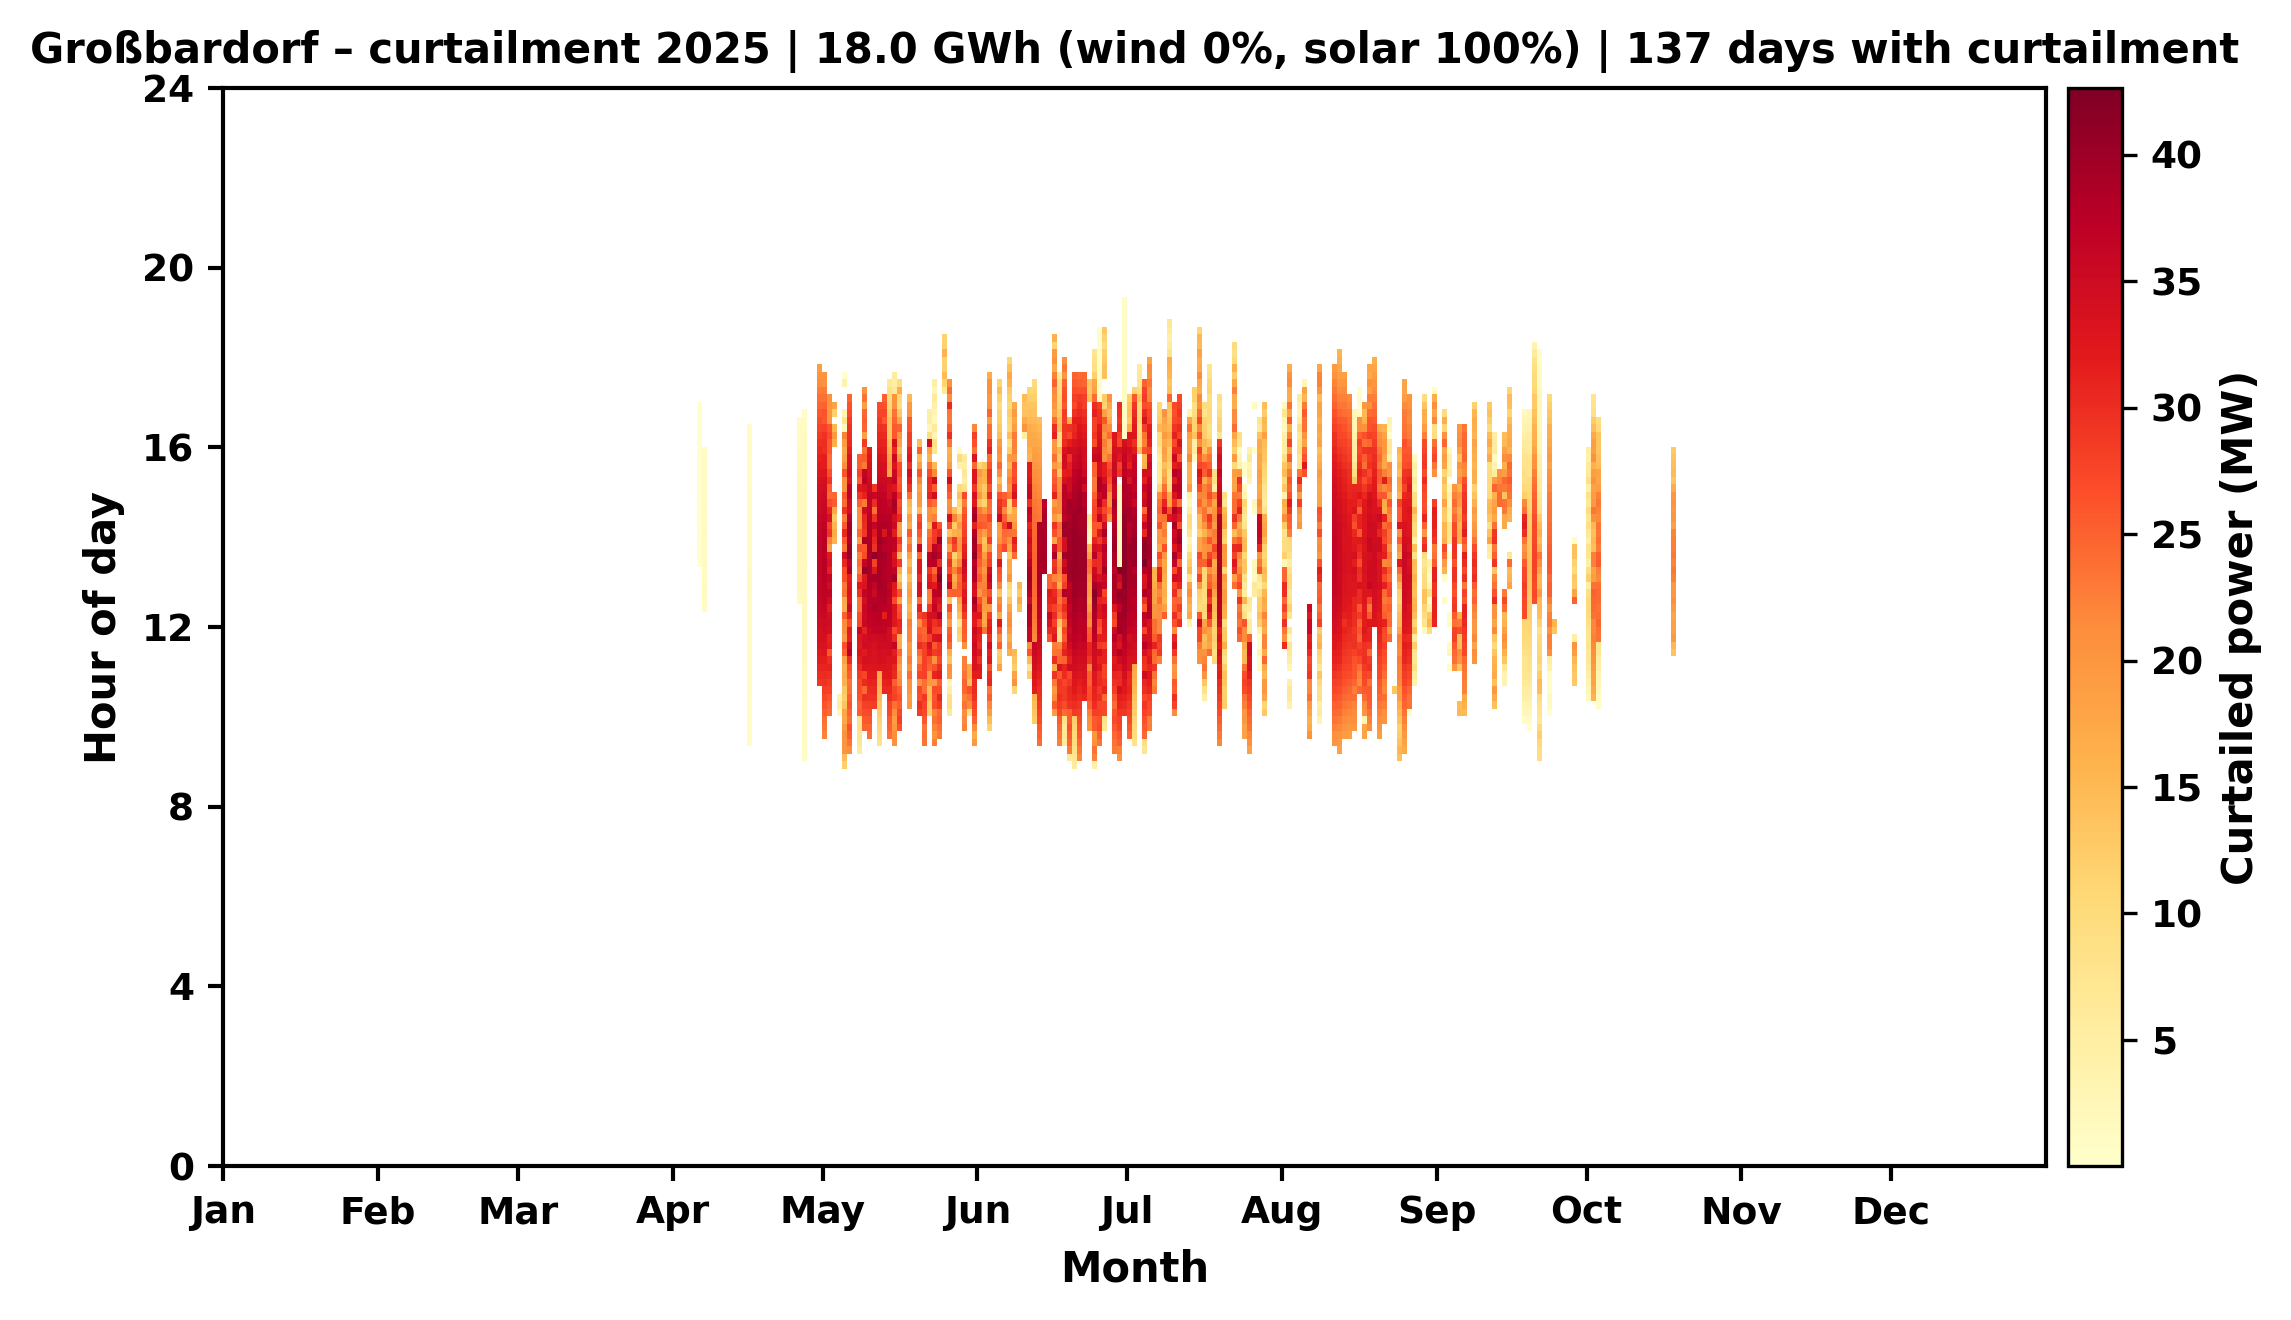

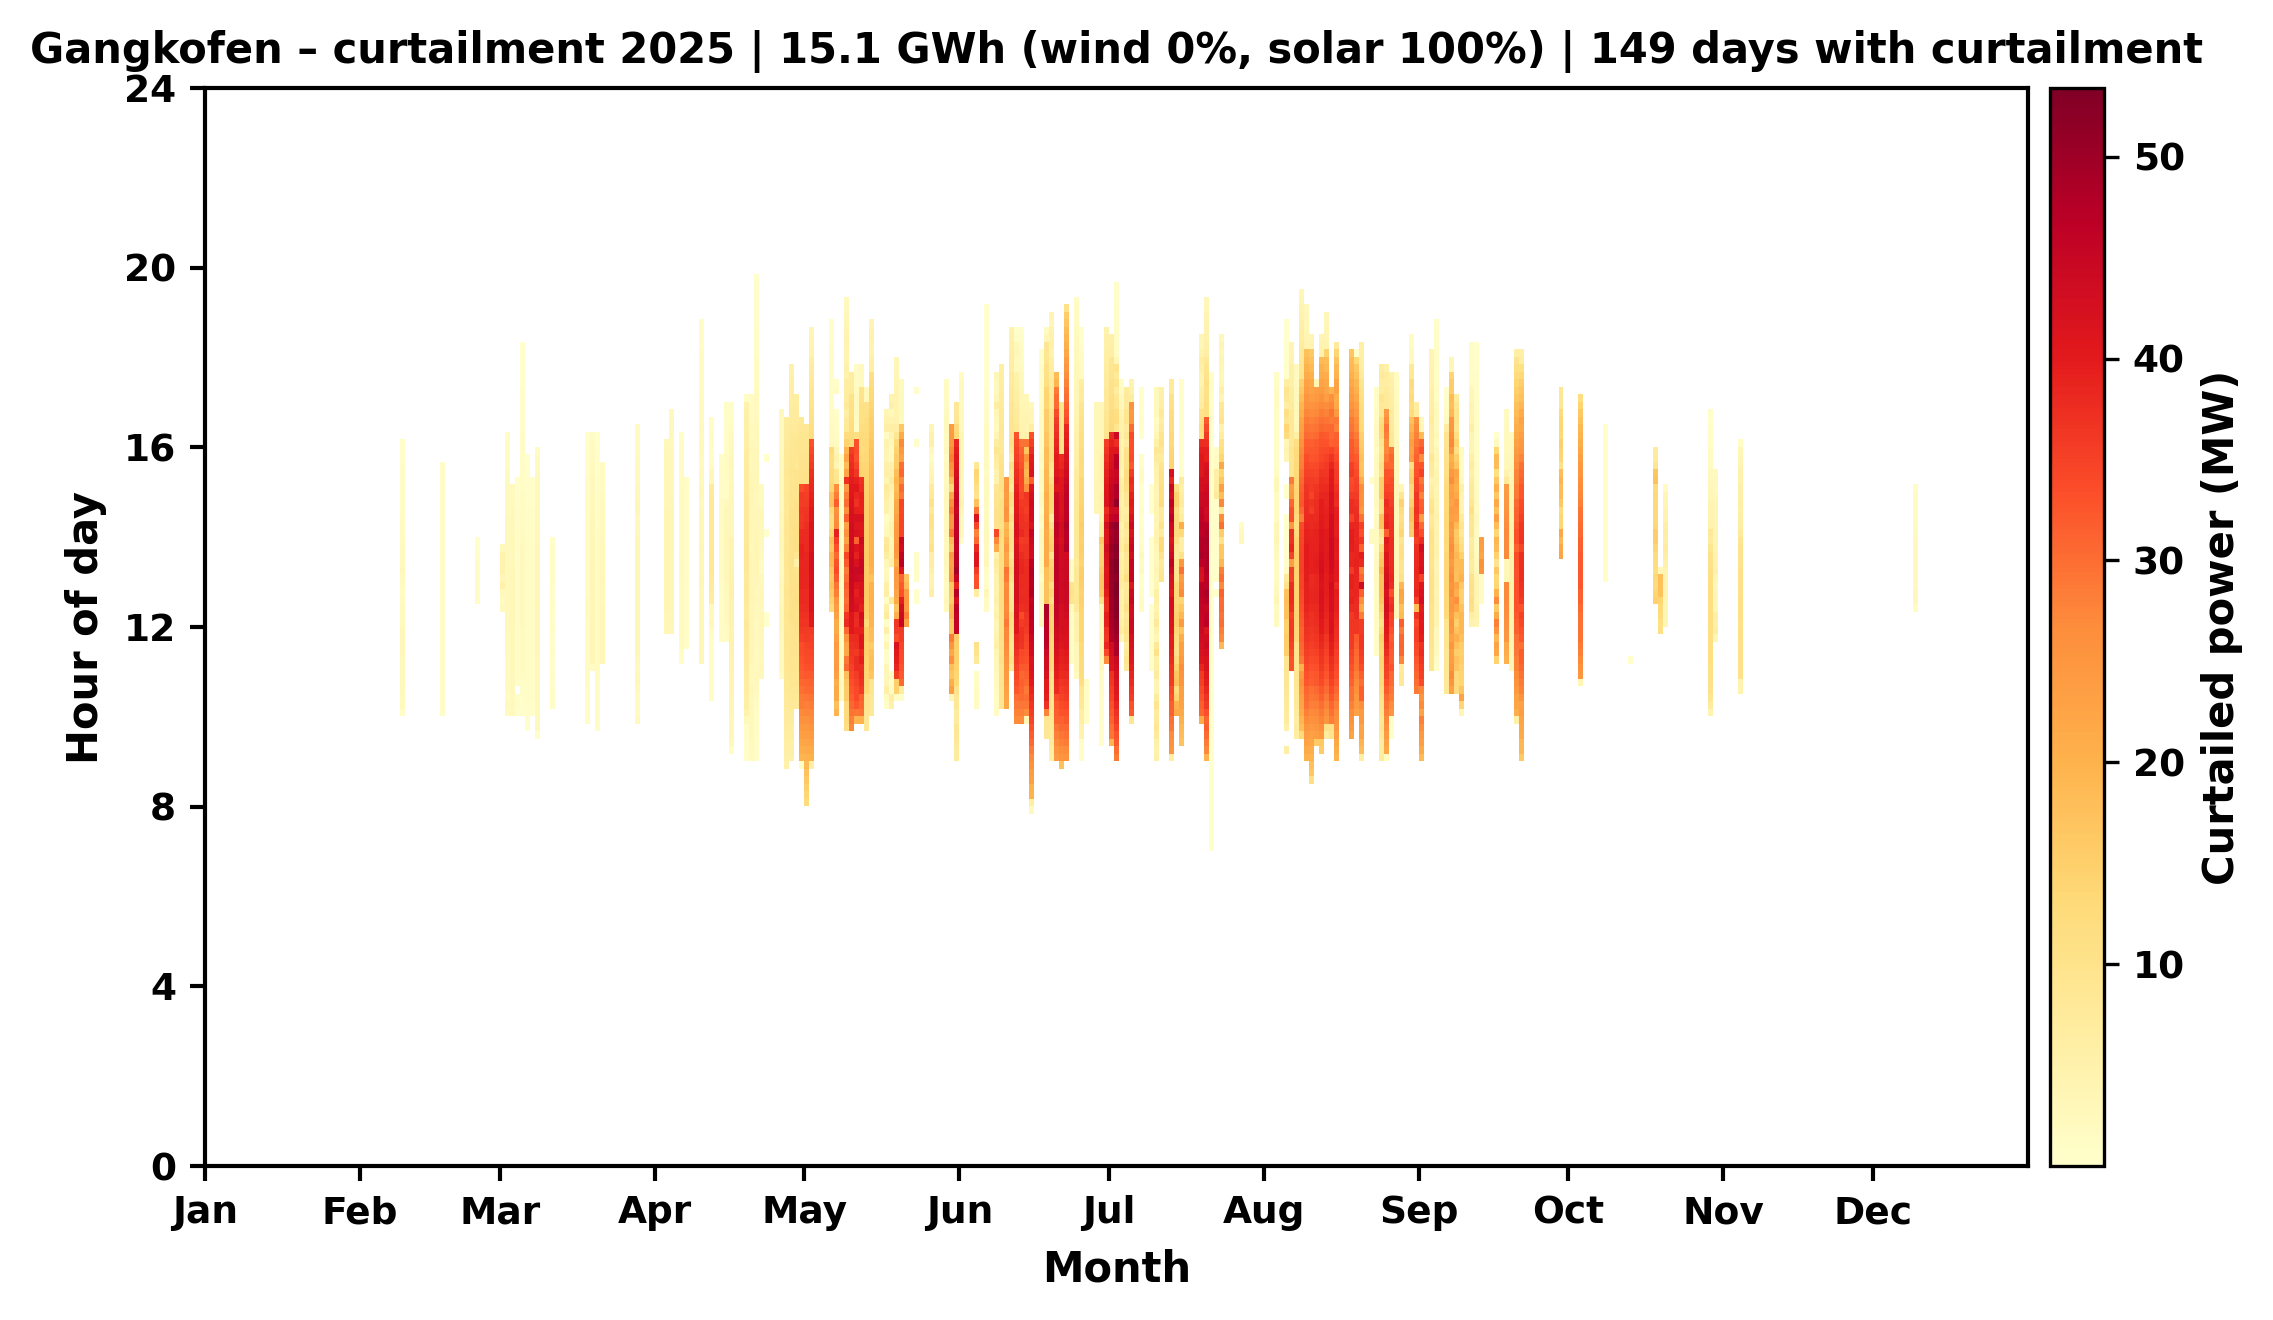

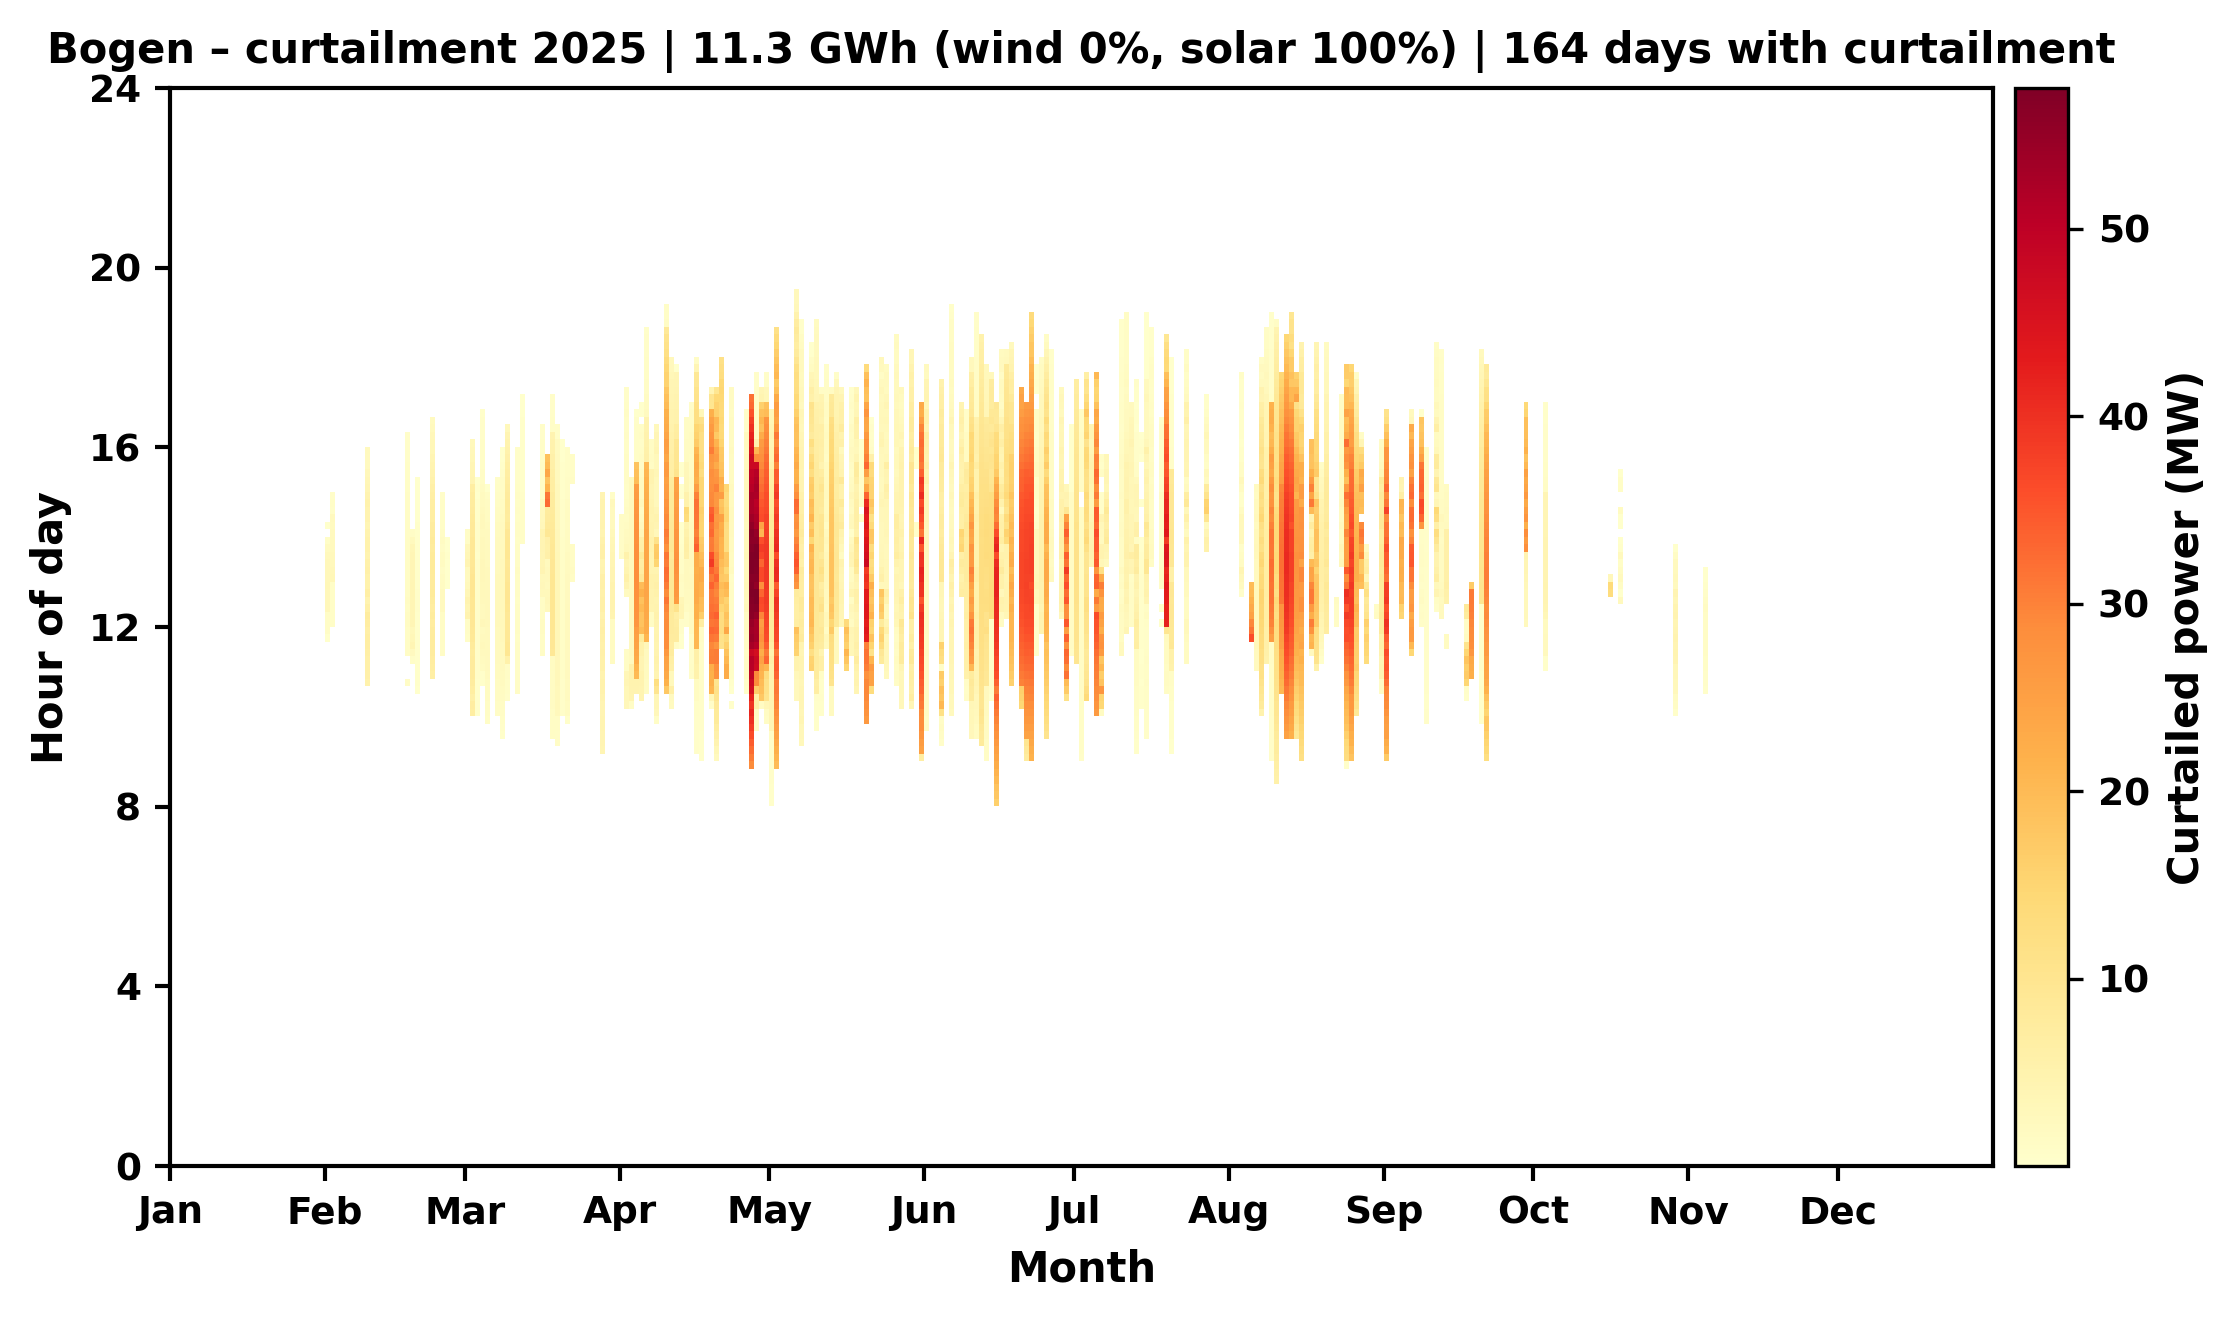

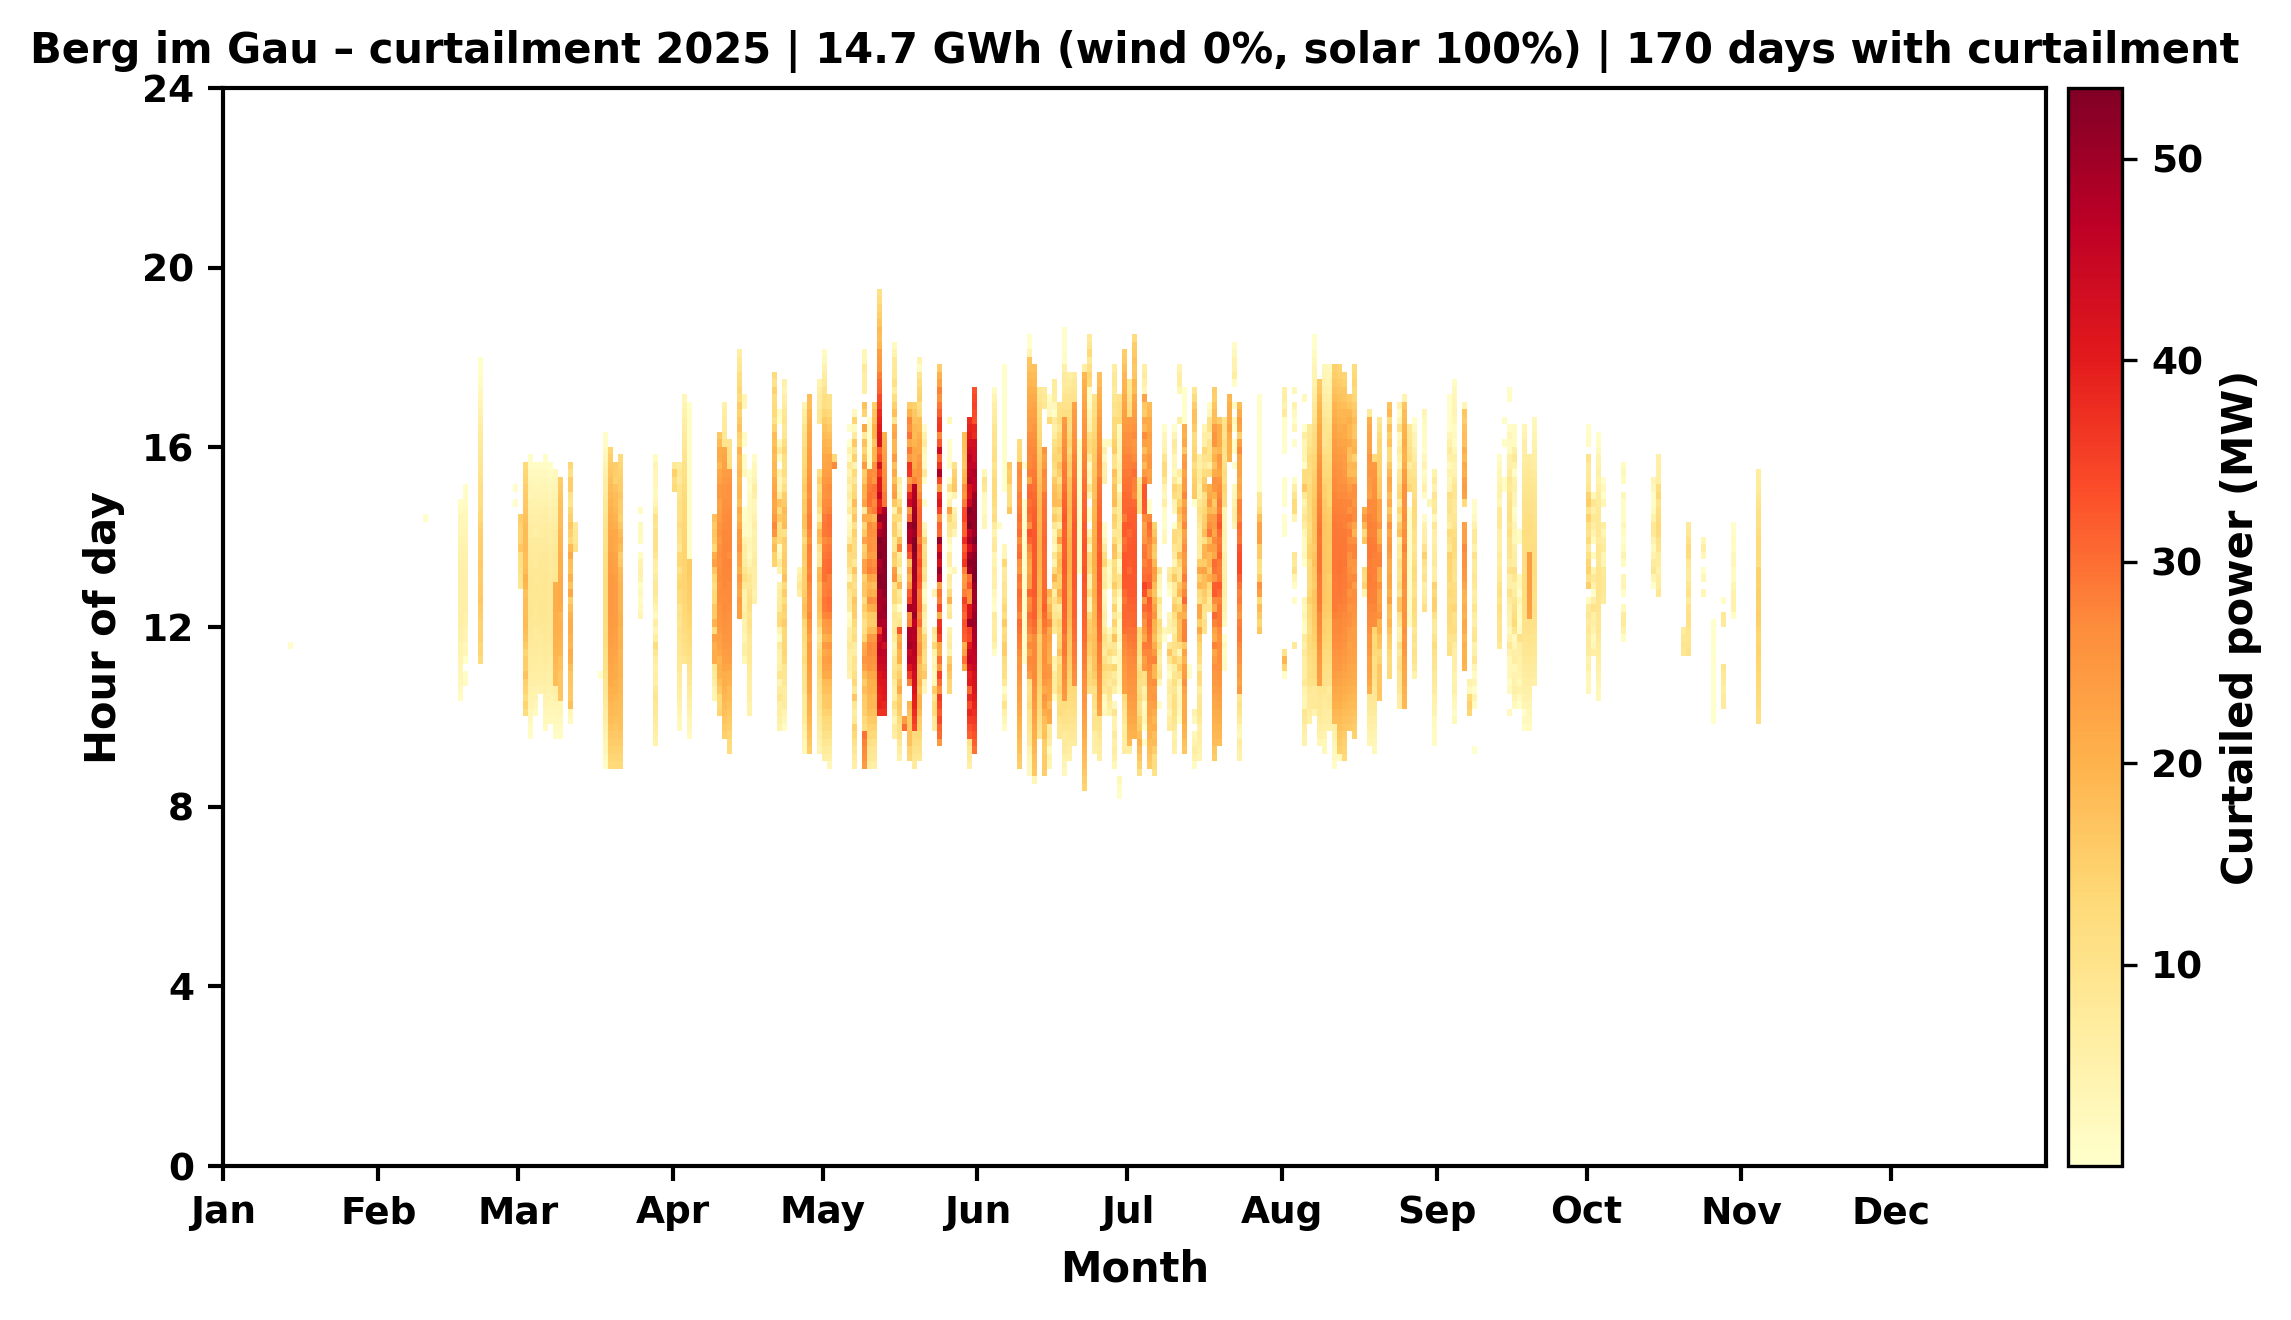

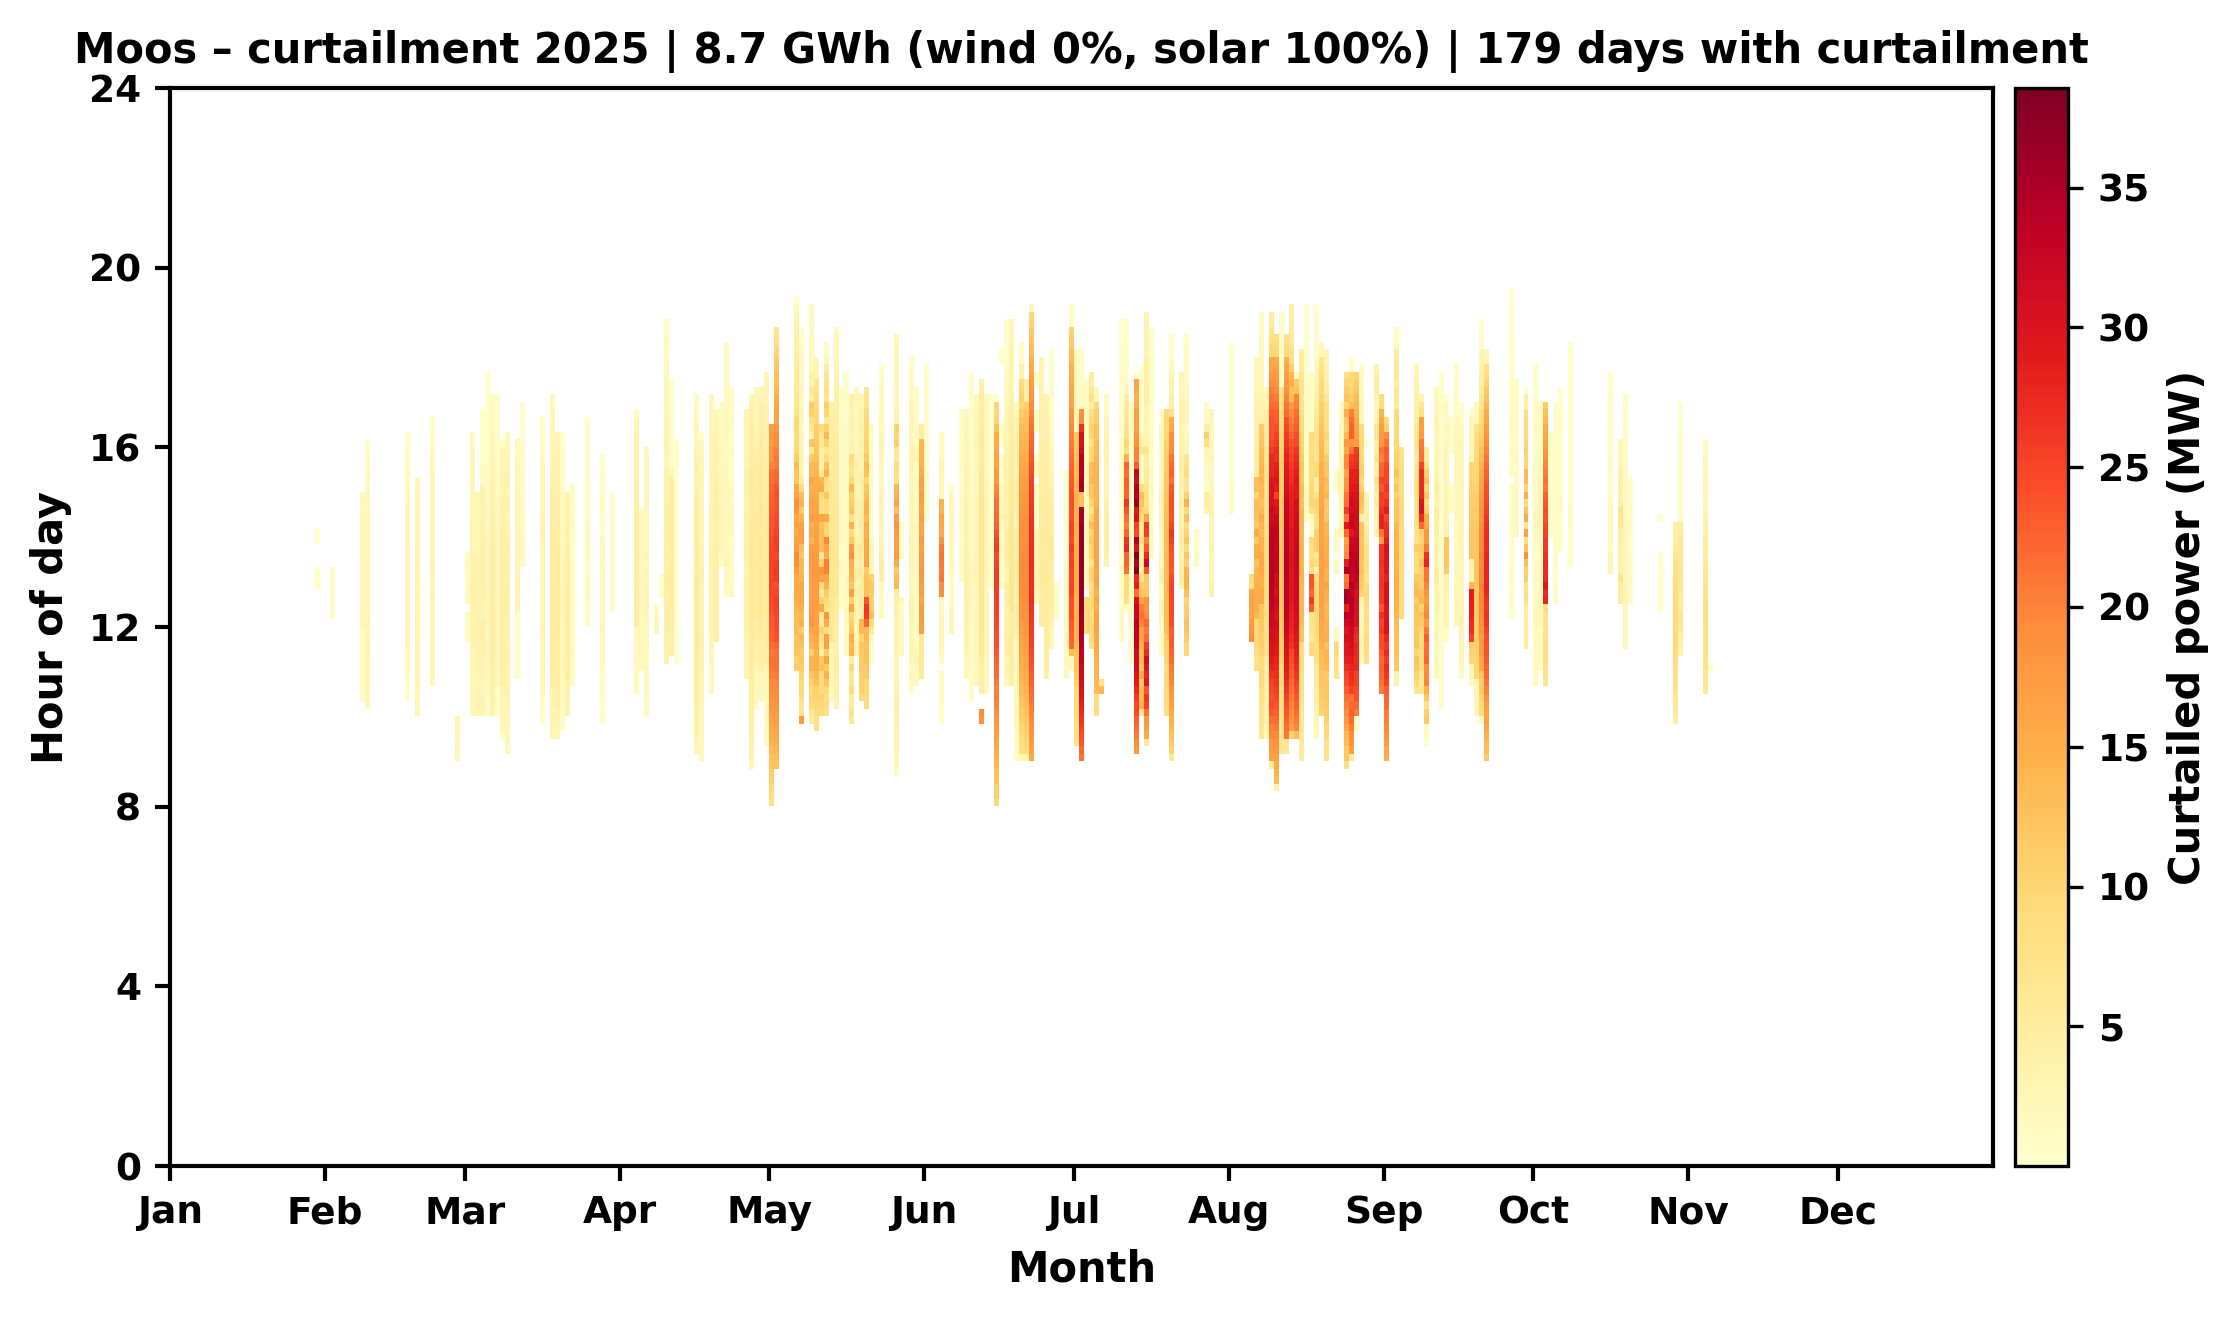

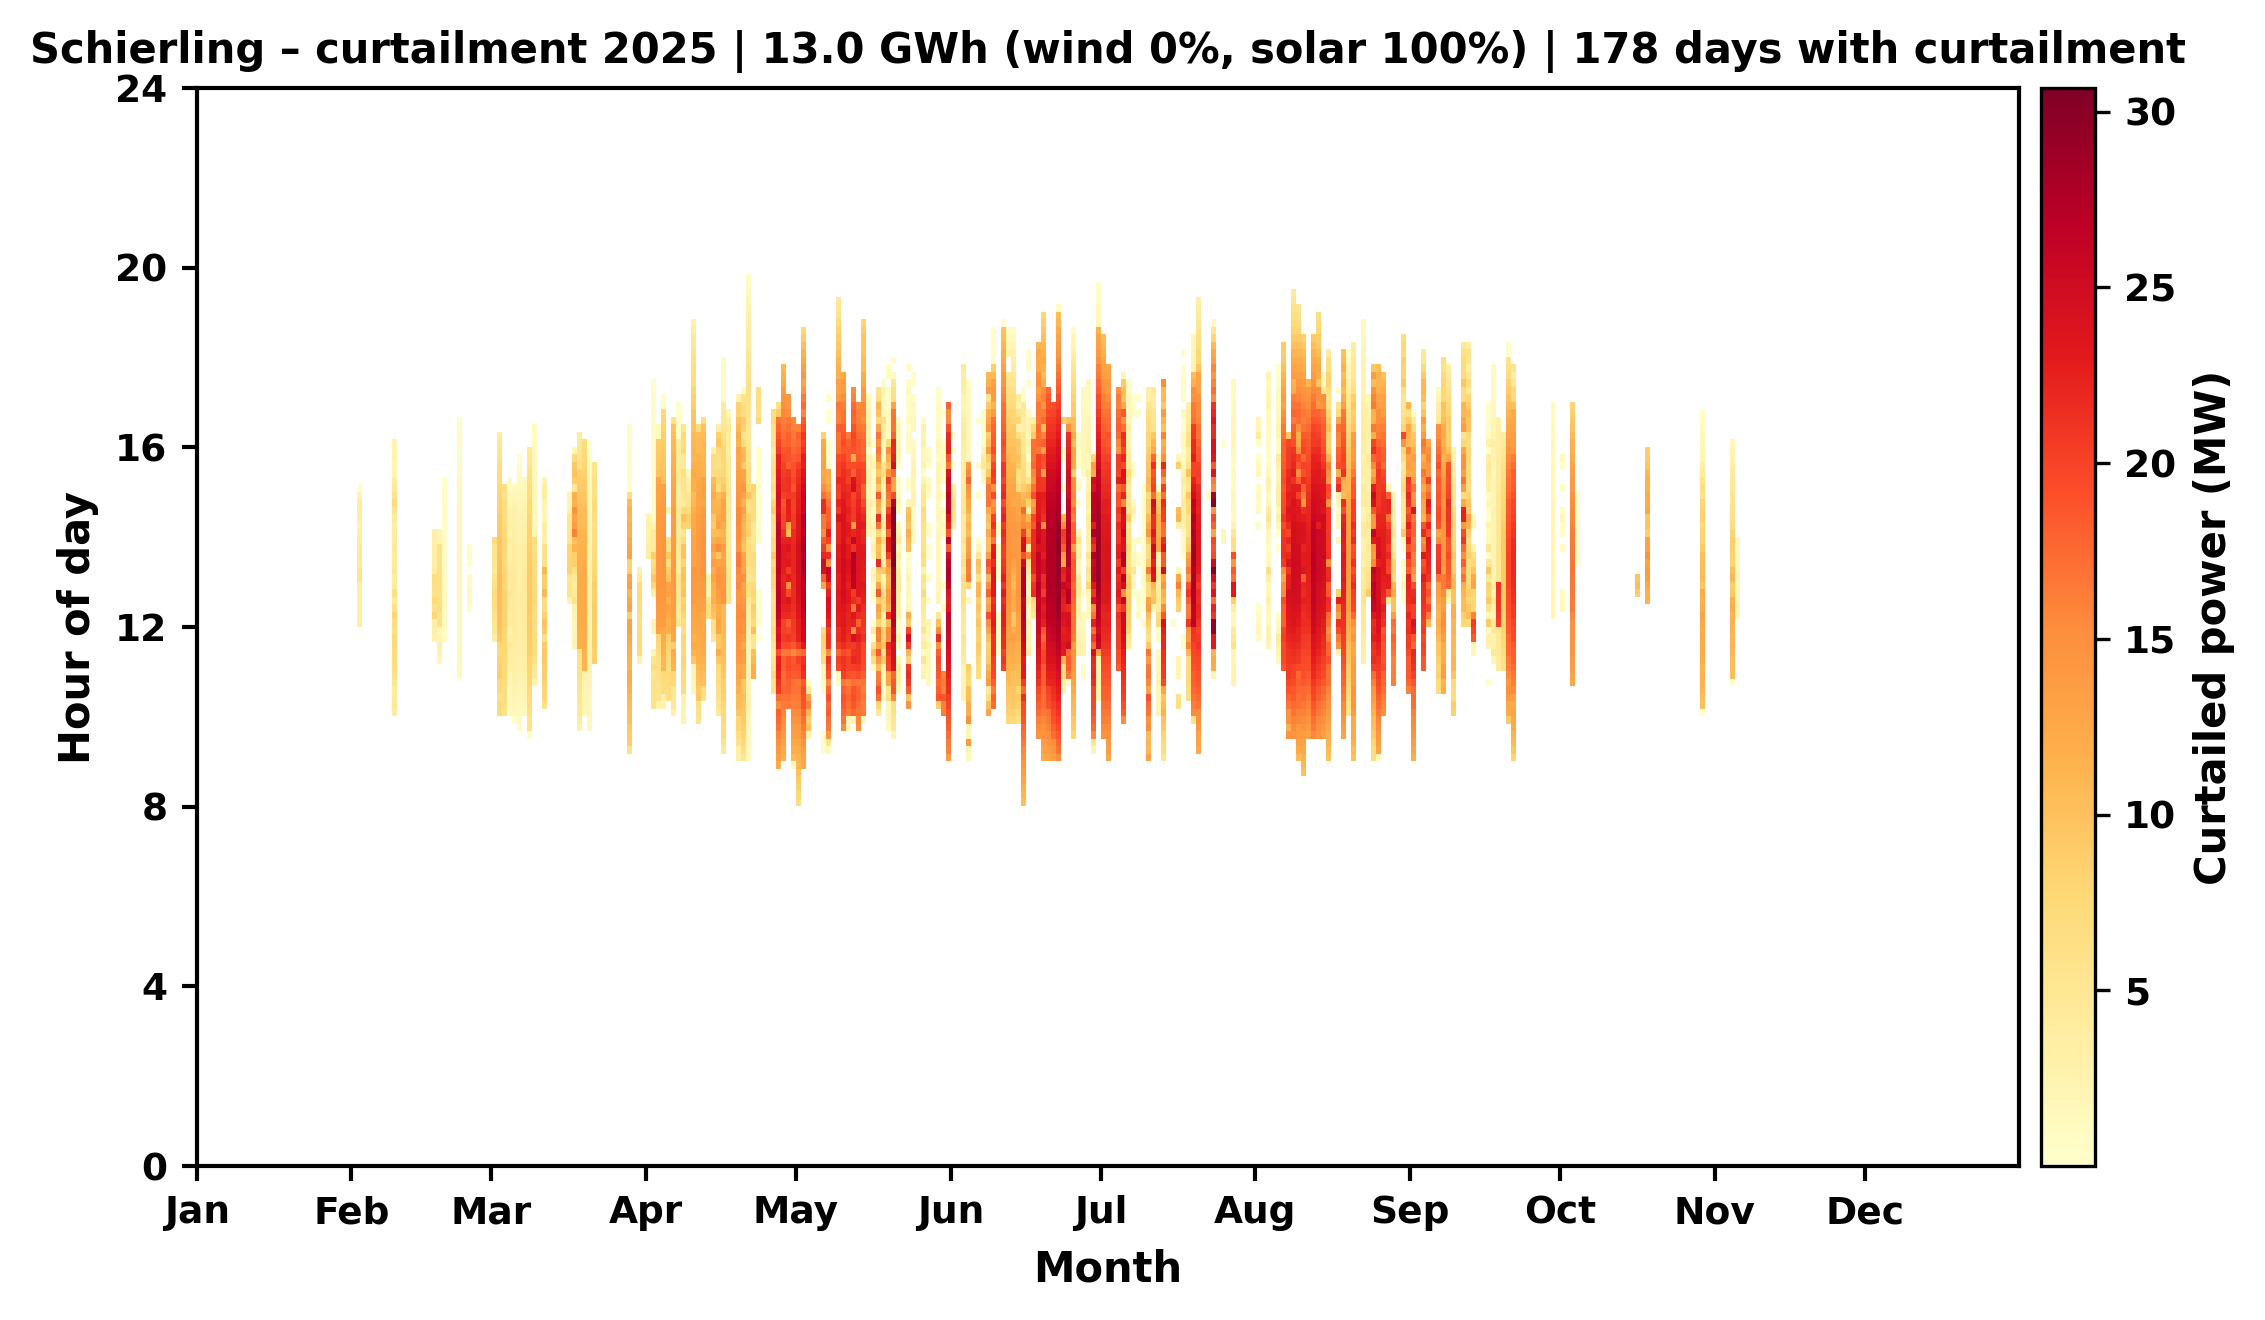

In [11]:
# Raster plot: hour of day over the year, coloured by curtailed power
TOP_N_PLOT = 10

# Slightly larger, bold labels so the figures stay readable in the printed thesis
FS_LABEL_UW, FS_TICK_UW, FS_TITLE_UW = 10, 9, 10
FIGSIZE_UW = (8.0, 4.5)

monate_en = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monats_ticks = [(datetime(JAHR, m, 1) - datetime(JAHR, 1, 1)).days for m in range(1, 13)]

cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad("white")

for _, kand in df_uw.head(TOP_N_PLOT).iterrows():
    loc = kand["location"]
    d = uw_store[loc]
    p_ges = d["p_solar"] + d["p_wind"]        # MW

    p_plot, einheit_p = scale_power(p_ges * 1e3)
    e_plot, einheit_e = scale_energy(pd.Series([kand["e_abregelung_gwh"] * 1e6]))

    raster = np.asarray(p_plot).reshape(-1, SLOTS).T
    raster = np.where(raster > 0, raster, np.nan)

    fig, ax = plt.subplots(figsize=FIGSIZE_UW, dpi=DPI)
    im = ax.imshow(raster, aspect="auto", cmap=cmap, origin="lower", interpolation="none",
                   extent=[0, raster.shape[1], 0, 24])
    ax.set_xticks(monats_ticks)
    ax.set_xticklabels(monate_en)
    ax.set_yticks(range(0, 25, 4))
    ax.set_xlabel("Month", fontsize=FS_LABEL_UW, fontweight="bold")
    ax.set_ylabel("Hour of day", fontsize=FS_LABEL_UW, fontweight="bold")
    ax.tick_params(axis="both", labelsize=FS_TICK_UW, width=1.0)
    plt.setp(ax.get_xticklabels() + ax.get_yticklabels(), fontweight="bold")
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)
    ax.set_title(f"{loc} – curtailment {JAHR} | {e_plot.iloc[0]:.1f} {einheit_e} "
                 f"(wind {kand['wind_anteil']:.0%}, solar {1 - kand['wind_anteil']:.0%}) | "
                 f"{int(kand['tage'])} days with curtailment",
                 fontsize=FS_TITLE_UW, fontweight="bold")
    cbar = fig.colorbar(im, ax=ax, pad=0.01)
    cbar.set_label(f"Curtailed power ({einheit_p})", fontsize=FS_LABEL_UW, fontweight="bold")
    cbar.ax.tick_params(labelsize=FS_TICK_UW)
    plt.setp(cbar.ax.get_yticklabels(), fontweight="bold")
    plt.tight_layout()
    plt.show()
